# Разведочный анализ данных PTB-XL

Команда 146. Чекпоинт 2.

Цель проекта - по 12-канальной ЭКГ определять пять диагностических групп:
NORM, MI, STTC, CD и HYP. У одной записи бывает несколько меток, поэтому решаем
задачу мультиметочной классификации. На этом этапе проверяем данные и разметку,
исследуем сигналы, оцениваем простой бейзлайн и сравниваем аугментации.

Общий ноутбук собран из работ Ульяны Шелеговой (метаданные и метки), Ирины
Ахмадулиной (сигналы), Марии Павленко (бейзлайн) и Алексея Воронова (аугментации).
Исходные ноутбуки сохранены рядом: `eda_metadata.ipynb`, `ecg_signal_eda.ipynb`,
`baseline_model.ipynb`, `augmentation.ipynb`.

## Порядок исследования

1. Общая загрузка и правила работы с данными.
2. Метаданные и целевые метки.
3. Структура и качество ЭКГ-сигналов.
4. Бейзлайн на статистических признаках.
5. Сравнение аугментаций.
6. Общие выводы.

## 1. Данные и запуск

Используем PTB-XL 1.0.3, `records100`: 100 Гц, 10 секунд, 12 отведений, mV.
Исследование метаданных и качества сигналов охватывает все 21 799 записей.
Для бейзлайна исключаем 411 записей без пяти выбранных меток и получаем
21 388 ЭКГ. Для аугментаций оставляем исходную выборку из 175 разных пациентов
только из тренировочных фолдов. Эти числа относятся к разным частям работы.

В Google Colab можно загрузить только этот ноутбук и выполнить его с первой
кодовой ячейки: она скачает репозиторий, установит зависимости и подготовит
данные. Репозиторий и сигналы сохраняются в `/content/ptbxl-checkpoint2/`.
При создании новой среды Colab подготовка выполняется заново.

Локальная подготовка из корня репозитория:

```bash
uv sync --locked
uv run python scripts/download_checkpoint2.py
uv run jupyter lab
```

Далее открыть `notebooks/EDA.ipynb` и выполнить ячейки по порядку.
При повторном запуске отдельного раздела сначала выполнить его ячейку настройки данных.
Полный набор сигналов хранится в `data/raw/ptb-xl/`, выборка для аугментаций -
в `data/augmentation_ptbxl_1.0.3/`. Данные в Git не добавляются.
Кэш 48 признаков бейзлайна создаётся в `data/processed/`.

Метки строятся функцией `prepare_labels` из `notebooks/labels.py`:
учитываем присутствие диагностического SCP-кода, включая likelihood 0.
Порядок меток: NORM, MI, STTC, CD, HYP. Используем фолды 1-8 для обучения,
9 для валидации и 10 для теста. Метаданные и отчёт врача не входят
в признаки текущего бейзлайна.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

# В Colab одного ipynb недостаточно: нужны модули проекта и сигналы.
if "google.colab" in sys.modules:
    colab_root = Path("/content/ptbxl-checkpoint2")
    if not colab_root.exists():
        subprocess.run([
            "git", "clone", "--depth", "1",
            "https://github.com/Icemist/hse-ai-2026-ecg-ptbxl.git", str(colab_root),
        ], check=True)
    if not (colab_root / "scripts/download_checkpoint2.py").is_file():
        # До слияния PR берём его версию; после слияния достаточно main.
        subprocess.run(["git", "fetch", "--depth", "1", "origin", "refs/pull/3/head"],
                       cwd=colab_root, check=True)
        subprocess.run(["git", "checkout", "--detach", "FETCH_HEAD"],
                       cwd=colab_root, check=True)
    os.chdir(colab_root)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q", "-e", str(colab_root),
        "nbformat", "matplotlib>=3.9",
    ], check=True)
    subprocess.run([sys.executable, "scripts/download_checkpoint2.py"], check=True)

import numpy as np
import pandas as pd

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").is_file() and (p / "src/ecg_ptbxl").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Запускайте ноутбук из папки репозитория. "
                            "В Google Colab сначала выполните эту ячейку подготовки.")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks"))
from labels import CLASSES, prepare_labels

PTBXL_DIR = ROOT / "data/raw/ptb-xl"
database_path = PTBXL_DIR / "ptbxl_database.csv"
statements_path = PTBXL_DIR / "scp_statements.csv"
if not database_path.is_file() or not statements_path.is_file():
    raise FileNotFoundError("Сначала выполните: uv run python scripts/download_checkpoint2.py")
labels_df = prepare_labels(database_path, statements_path)
assert len(labels_df) == 21799 and labels_df.ecg_id.is_unique
assert labels_df.has_target_label.sum() == 21388

# Проверяем совместимость общего разбиения до всех экспериментов.
split_metadata = pd.read_csv(database_path, usecols=["ecg_id", "patient_id", "strat_fold"])
split_metadata["split"] = np.select(
    [split_metadata.strat_fold <= 8, split_metadata.strat_fold == 9],
    ["train", "validation"], default="test")
assert split_metadata.groupby("patient_id")["split"].nunique().max() == 1
display(split_metadata.groupby("split", sort=False).agg(
    records=("ecg_id", "size"), patients=("patient_id", "nunique")))

,records,patients
split,,
train,17418,15023
validation,2183,1942
test,2198,1904


## 2. Метаданные и целевые метки

Часть Ульяны Шелеговой.

In [3]:
import pandas as pd
from pathlib import Path
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
PROJECT_ROOT = ROOT
data_path = PROJECT_ROOT / "data"

database_path = PTBXL_DIR / "ptbxl_database.csv"
statements_path = PTBXL_DIR / "scp_statements.csv"

df = pd.read_csv(database_path)
scp = pd.read_csv(statements_path, index_col=0)

In [5]:
print('Размер основной базы ЭКГ: ', df.shape)
# 21799 записей, 28 признаков
print("Размер справочника кодов:", scp.shape)
# справочник содержит 71 код

Размер основной базы ЭКГ:  (21799, 28)
Размер справочника кодов: (71, 12)


In [6]:
print('Столбцы датасета ЭКГ (ptbxl_database.csv):', df.columns)

Столбцы датасета ЭКГ (ptbxl_database.csv): Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr'],
      dtype='object')


### Работа с пропусками

In [7]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing_values, "missing_percent": missing_percent})
missing_table = missing_table.sort_values(by="missing_percent", ascending=False)
print(missing_table)

                              missing_count  missing_percent
electrodes_problems                   21769            99.86
infarction_stadium2                   21696            99.53
pacemaker                             21508            98.67
burst_noise                           21186            97.19
baseline_drift                        20201            92.67
extra_beats                           19850            91.06
static_noise                          18539            85.05
infarction_stadium1                   16187            74.26
height                                14825            68.01
weight                                12378            56.78
validated_by                           9378            43.02
heart_axis                             8468            38.85
nurse                                  1473             6.76
site                                     17             0.08
recording_date                            0             0.00
device                  

* Больше 90% пропусков в столбах: electrodes_problems, pacemaker, burst_noise, baseline_drift, extra_beats
* Больше 70%: static_noise, infarction_stadium1
* Больше 50%: height, weight

Тем не менее, все названные признаки относятся к дополнительным полям, не несущим ключевой информации (Additional fields are heart_axis, infarction_stadium1, infarction_stadium2, validated_by, second_opinion, initial_autogenerated_report and validated_by_human.)
Но все же с ними придется работать. Либо стоит заполнять, где пропусков не так много, либо вообще удалять признаки.  **Необходимость использования дополнительных метаданных будет оцениваться отдельно, на этапе обучения модели**.

**Авторы считают scp_codes и report - ключевыми признаками**, и они, к счастью, полностью заполнены. *Пропусков так же нет в возрасте и поле*, а они относятся к важным признакам

В текущем бейзлайне `scp_codes` служит для получения целевых меток, а `report` не используется. На вход модели идут только статистические признаки сигнала.

### Работа с дублями

In [8]:
print("Полностью дублирующиеся строки:", df.duplicated().sum())
print("Дублирующиеся patient_id:", df["patient_id"].duplicated().sum())
print('\nCколько уникальных пациентов:', df["patient_id"].nunique(), f"из {df.shape[0]}")
print("Записей на одного пациента в среднем:", len(df) / df["patient_id"].nunique())

Полностью дублирующиеся строки: 0
Дублирующиеся patient_id: 2930

Cколько уникальных пациентов: 18869 из 21799
Записей на одного пациента в среднем: 1.1552811489745085


* Полностью дублирующихся строк метаданных не обнаружено
* Но некоторые пациенты встречаются в датасете по несколько раз, а поэтому нельзя автоматически считать каждую запись независимым пациентом

### Работа с ключевыми признаками

#### ВОЗРАСТ

In [9]:
print(df['age'].describe()) # есть возраст 300 лет.
print('Сколько записей с людьми старше 100 лет:', df[df['age'] > 100].shape[0])
print('Распределение по возрасту старше 100 лет\n', df[df['age'] > 100]['age'].value_counts(dropna=False))

count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64
Сколько записей с людьми старше 100 лет: 293
Распределение по возрасту старше 100 лет
 age
300.0    293
Name: count, dtype: int64


293 записи - клиентам 300 лет

В описании датасета написано, что возраст пациентов старше 89 лет представлен значениями из диапазона около 300 лет, чтобы соблюсти требования HIPAA по защите медицинских данных. То есть, **300 лет - не ошибка, а сократие реального возхраста пожилым клиентов**. Тем не менее, если мы потом будем анализировать зависимость возраста от диагностических классов, **значение 300 нельзя включать как настоящий возраст. Его нужно отдельно обозначать как неизвестный/обезличенный возраст**.
-> создаем столбец, где заменяем 300 на обезличенный возраст, чтобы при обучении использовать только правдивые данные

In [10]:
df["age_clean"] = df["age"].replace(300, np.nan)

#### ПОЛ

In [11]:
print(df['sex'].value_counts(dropna=False, normalize=True)) # примерно в равном отношении пол

sex
0    0.52085
1    0.47915
Name: proportion, dtype: float64


#### Распределение ФОЛДОВ (как устроено разделение данных?)

In [12]:
print(df["strat_fold"].value_counts().sort_index())

strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64


Авторы рекомендуют: Records in fold 9 and 10 underwent at least one human evaluation and are therefore of a particularly high label quality. **We therefore propose to use folds 1-8 as training set, fold 9 as validation set and fold 10 as test set**.
-> фолды распределены примерно в равном отношении

#### РОСТ И ВЕС

In [13]:
print(df[['height', 'weight']].describe())

            height       weight
count  6974.000000  9421.000000
mean    166.702323    70.995223
std      10.867321    15.878803
min       6.000000     5.000000
25%     160.000000    60.000000
50%     166.000000    70.000000
75%     174.000000    80.000000
max     209.000000   250.000000


### СПРАВОЧНИК ДИАГНОСТИЧЕСКИХ КОДОВ

Авторы датасета говорят, что: For diagnostic statements, we also provide a proposed hierarchical organization into diagnostic_class and diagnostic_subclass.
* diagnostic_subclass - конкретная метка, присвоенная записи ЭКГ.
* diagnostic_class - более крупная категория, объединяющая несколько диагностических кодов.
* description - описание диагностического кода
* diagnostic - относится ли код к диагностическим -> Учитываем ли мы этот код как диагностическую метку в нашей задаче?

In [14]:
print('Столбцы датасета с аннотациями (scp_statements.csv):', scp.columns)

Столбцы датасета с аннотациями (scp_statements.csv): Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='object')


In [15]:
print(scp["diagnostic"].value_counts(dropna=False)) # то есть, диагностировать будем 44 кода.
print('\n', scp["diagnostic_class"].value_counts(dropna=False)) # Для построения таргета используем только диагностические коды с заполненным diagnostic_class.
print('\n', scp["diagnostic_subclass"].value_counts(dropna=False))

diagnostic
1.0    44
NaN    27
Name: count, dtype: int64

 diagnostic_class
NaN     27
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64

 diagnostic_subclass
NaN          27
IMI           6
AMI           6
STTC          5
ISCA          4
_AVB          3
ISCI          2
LAFB/LPFB     2
ISC_          1
LVH           1
NST_          1
NORM          1
IVCD          1
CRBBB         1
CLBBB         1
IRBBB         1
LAO/LAE       1
LMI           1
RAO/RAE       1
RVH           1
WPW           1
ILBBB         1
SEHYP         1
PMI           1
Name: count, dtype: int64


### ТАРГЕТ

Необходимо отдельно поработать с целевой переменной, потому что на данный момент формат записи неудобен для обучения модели.
-> **Мы преобразуем исходные scp_codes в пять укрупнённых классов (NORM, MI, STTC, CD, HYP -- ориентируясь на классы датасета scp), чтобы объединить отдельные диагностические коды в более общие категории и сформировать целевые метки для задачи мультиметочной классификации.**

In [16]:
df["scp_dict"] = df["scp_codes"].apply(ast.literal_eval) # из строки в словарь

scp_final = scp[(scp["diagnostic"] == 1) & (scp["diagnostic_class"].notna())]
def get_superclass(scp_codes):
    classes = set()
    for scp_code in scp_codes.keys():
        if scp_code in scp_final.index:
            classes.add(scp_final.loc[scp_code, "diagnostic_class"])

    return sorted(classes)

df['scp_class'] = df['scp_dict'].apply(get_superclass)

all_classes = list(scp_final['diagnostic_class'].unique())
for class_name in all_classes:
    df[class_name] = df['scp_class'].apply(lambda x: int(class_name in x))

print('Распределение классов:')
for class_name in all_classes:
    print(f'{class_name}: {round(df[class_name].sum() / df.shape[0], 2) * 100}%')

Распределение классов:
STTC: 24.0%
NORM: 44.0%
MI: 25.0%
HYP: 12.0%
CD: 22.0%


In [17]:
# Проверяем, что исходный разбор меток совпадает с общим labels.py.
pd.testing.assert_frame_equal(
    df.set_index("ecg_id")[CLASSES].sort_index(),
    labels_df.set_index("ecg_id")[CLASSES].sort_index(),
    check_dtype=False)

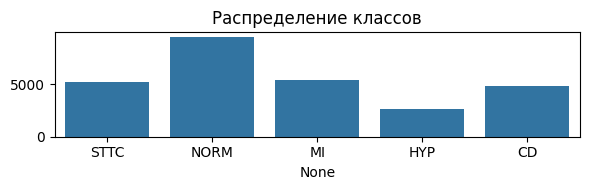

In [18]:
classes_df = df[all_classes].copy()
cls = classes_df.sum()
plt.figure(figsize=(6, 2))
sns.barplot(x=cls.index, y=cls.values)
plt.title("Распределение классов")
plt.tight_layout()
plt.show();

Есть некий **дисбаланс классов**: HYP встревчается реже всего - 12%, NORM больше всего - 44%. Стоит внимательно проверять при обучении не будет ли модель искусственно ставить NORM, чтобы повысить качество..
**В дальнейшем нужно будет внимательно оценивать качество по каждому классу, а не только общую точность**

In [19]:
labels_counting = classes_df.sum(axis=1).value_counts()

print(f'Долевое соотношение количества меток на 1 запись ЭКГ:\n{labels_counting / classes_df.shape[0]}')

Долевое соотношение количества меток на 1 запись ЭКГ:
1    0.745172
2    0.186614
3    0.042158
0    0.018854
4    0.007202
Name: count, dtype: float64


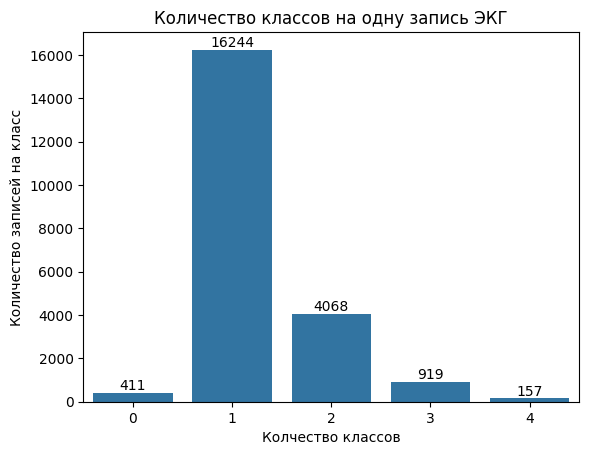

In [20]:
fig, ax = plt.subplots()
sns.barplot(x=labels_counting.index, y=labels_counting.values, ax=ax)
plt.title("Количество классов на одну запись ЭКГ")
plt.xlabel("Колчество классов")
plt.ylabel("Количество записей на класс")
ax.bar_label(ax.containers[0])
plt.show()

В основном на одну ЭКГ приходится - 1 класс (в 75% случаев), 2 класса - в 19%. 3, 0, 4 класса - в сумме реже, чем 7%.

In [21]:
zero_label_records = (classes_df.sum(axis=1) == 0)
print("Доля записей без выбранных диагностических меток:", round(zero_label_records.mean() * 100, 2), "%")
zero_df = df[df[all_classes].sum(axis=1) == 0]

def fold_to_split(fold):
    if fold <= 8:
        return "train"
    elif fold == 9:
        return "val"
    else:
        return "test"

print('\nВ какие фолды попали такие случаи без меток:\n', zero_df['strat_fold'].map(fold_to_split).value_counts())

Доля записей без выбранных диагностических меток: 1.89 %

В какие фолды попали такие случаи без меток:
 strat_fold
train    334
test      40
val       37
Name: count, dtype: int64


411 записей не имеют ни одной из пяти выбранных диагностических меток. В EDA оставляем их для описания полного датасета. В бейзлайне, как в исходной работе Марии, исключаем из всех трёх частей: 334 из train, 37 из validation и 40 из test.

### Выводы по метаданным

#### Структура и качество данных

* Датасет PTB-XL содержит 21 799 записей ЭКГ и 28 признаков.
* Справочник scp_statements.csv включает 71 диагностический и недиагностический код, из которых 44 помечены как диагностические.

**Пропущенные значения**: значительная доля пропусков обнаружена в дополнительных  **метаданных**. При этом пропуски отсутствуют в scp_codes, age и sex. Необходимость использования дополнительных метаданных и способы обработки пропусков будут определяться отдельно при подготовке данных к обучению.

**Дубликаты и структура пациентов**: полностью дублирующихся строк в датасете не обнаружено. При этом количество уникальных записей не совпадает с уникальным числом клиентов, то есть некоторые пациенты имеют несколько записей ЭКГ. Это **необходимо учитывать при разделении данных на обучающую, валидационную и тестовую выборки, чтобы записи одного пациента не попадали одновременно в разные выборки**.

 **Возраст пациентов**: в 293 записях обнаружено значение **возраста 300 лет**. Согласно описанию от авторов, такие значения используются для обезличивания возраста пациентов старше 89 лет и не являются реальным возрастом. Поэтому при анализе возрастных зависимостей их следует рассматривать как неизвестные значения, а не как фактический возраст.

**Пол**: распределение записей относительно сбалансировано

**Разбиение данных**: записи распределены между десятью фолдами примерно равномерно. Согласно рекомендациям авторов датасета, фолды 1-8 предлагается использовать для обучения, фолд 9 - для валидации, фолд 10 - для тестирования.

#### Таргет

Из исходных диагностических кодов scp_codes были выделены **пять диагностических классов**: NORM, MI, STTC, CD и HYP.

Присутствует **дисбаланс классов**: HYP встречается реже остальных категорий, тогда как NORM представлен наиболее широко. При обучении модели важно оценивать качество предсказаний отдельно для каждого класса, а не ориентироваться исключительно на общую метрику качества.

**Анализ количества целевых меток на одну запись** ЭКГ показал, что:
* 74,52% записей имеют одну диагностическую метку;
* 18,66% - две метки;
* 4,22% - три метки;
* 0,72% - четыре метки;
* 1,89% не имеют ни одной из пяти выбранных меток.

Это подтверждает **необходимость задачи мультиметочной классификации**.

Отдельного внимания требуют **1,89% записей, для которых не удалось определить ни один из пяти выбранных классов**. В анализе данных они сохранены; в бейзлайне ниже исключены из train, validation и test.

Для общего эксперимента используем `prepare_labels`, фолды 1-8/9/10 и метрики по каждому классу. Дополнительные метаданные в текущий бейзлайн не включаем.

## 3. Структура и качество ЭКГ-сигналов

Часть Ирины Ахмадулиной. Все проверки этого раздела выполняются на полном наборе, без удаления записей.

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from labels import prepare_labels, CLASSES
from scipy.ndimage import uniform_filter1d

DATA_DIR = PTBXL_DIR
METADATA_PATH = database_path

metadata = pd.read_csv(METADATA_PATH)
metadata = metadata.set_index("ecg_id", drop=False)

print("Количество записей в таблице:", len(metadata))

Количество записей в таблице: 21799


In [23]:
# Загружаем первую запись
first_ecg_id = metadata.index[0]
first_record_path = DATA_DIR / metadata.loc[first_ecg_id, "filename_lr"]
record = wfdb.rdrecord(str(first_record_path))

signal = record.p_signal

print("Размер сигнала:", signal.shape)
print("Частота дискретизации:", record.fs, "Гц")
print("Количество отведений:", len(record.sig_name))
print("Названия отведений:", record.sig_name)
print("Единицы измерения:", record.units)
print("Тип данных:", signal.dtype)
print("Продолжительность записи:", signal.shape[0]/record.fs, "секунд")

Размер сигнала: (1000, 12)
Частота дискретизации: 100 Гц
Количество отведений: 12
Названия отведений: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Единицы измерения: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Тип данных: float64
Продолжительность записи: 10.0 секунд


### Немного об экг
отведения экг: https://avatars.mds.yandex.net/i?id=78b64a462f20d36735907bbfceb4fa6f_sr-4900921-images-thumbs&n=13"

Стандартные отведения от конечностей:
- I отведение - левая рука и правая рука.
- II отведение - левая нога и правая рука.
- III отведение - левая нога и левая рука.

Усиленные однополюсные отведения от конечностей:
- aVR - усиленное отведение от правой руки.
- aVL - усиленное отведение от левой руки.
- aVF - усиленное отведение от левой ноги.

Грудные отведения: V1, V2, V3, V4, V5, V6

### Проверка структуры всех ЭКГ-записей

In [24]:
structure_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    structure_results.append({
        "ecg_id": ecg_id,
        "n_samples": signal.shape[0],
        "n_leads": signal.shape[1],
        "fs": rec.fs,
        "duration_sec": signal.shape[0]/rec.fs,
        "leads": tuple(rec.sig_name),
        "units": tuple(rec.units)})

structure_df = pd.DataFrame(structure_results)

print("Количество записей с одинаковой структурой:",
      ((structure_df["n_samples"] == 1000) & (structure_df["n_leads"] == 12)
       & (structure_df["fs"] == 100) & (structure_df["duration_sec"] == 10)).sum())

print("Количество записей с другими названиями отведений:",
      (structure_df["leads"] != tuple(record.sig_name)).sum())

print("Количество записей с другими единицами измерения:",
      (structure_df["units"] != tuple(record.units)).sum())

Количество записей с одинаковой структурой: 21799
Количество записей с другими названиями отведений: 0
Количество записей с другими единицами измерения: 0


### Структура экг-сигналов

Каждая запись содержит 1000 временных отсчётов и 12 отведений. Во всех случаях частота дискретизации - 100 Гц, продолжительность записи - 10 секунд. Названия отведений и единицы измерения совпадают во всех записях. Все сигналы в mV (милливольты).

-> Структура входных экг-сигналов однородна. Это упрощает подготовку данных к обучению модели: сигналы можно объединять в единый массив фиксированного размера без дополнительного выравнивания длины, дополнения нулями или изменения частоты дискретизации.

### Визуализация ЭКГ-сигнала

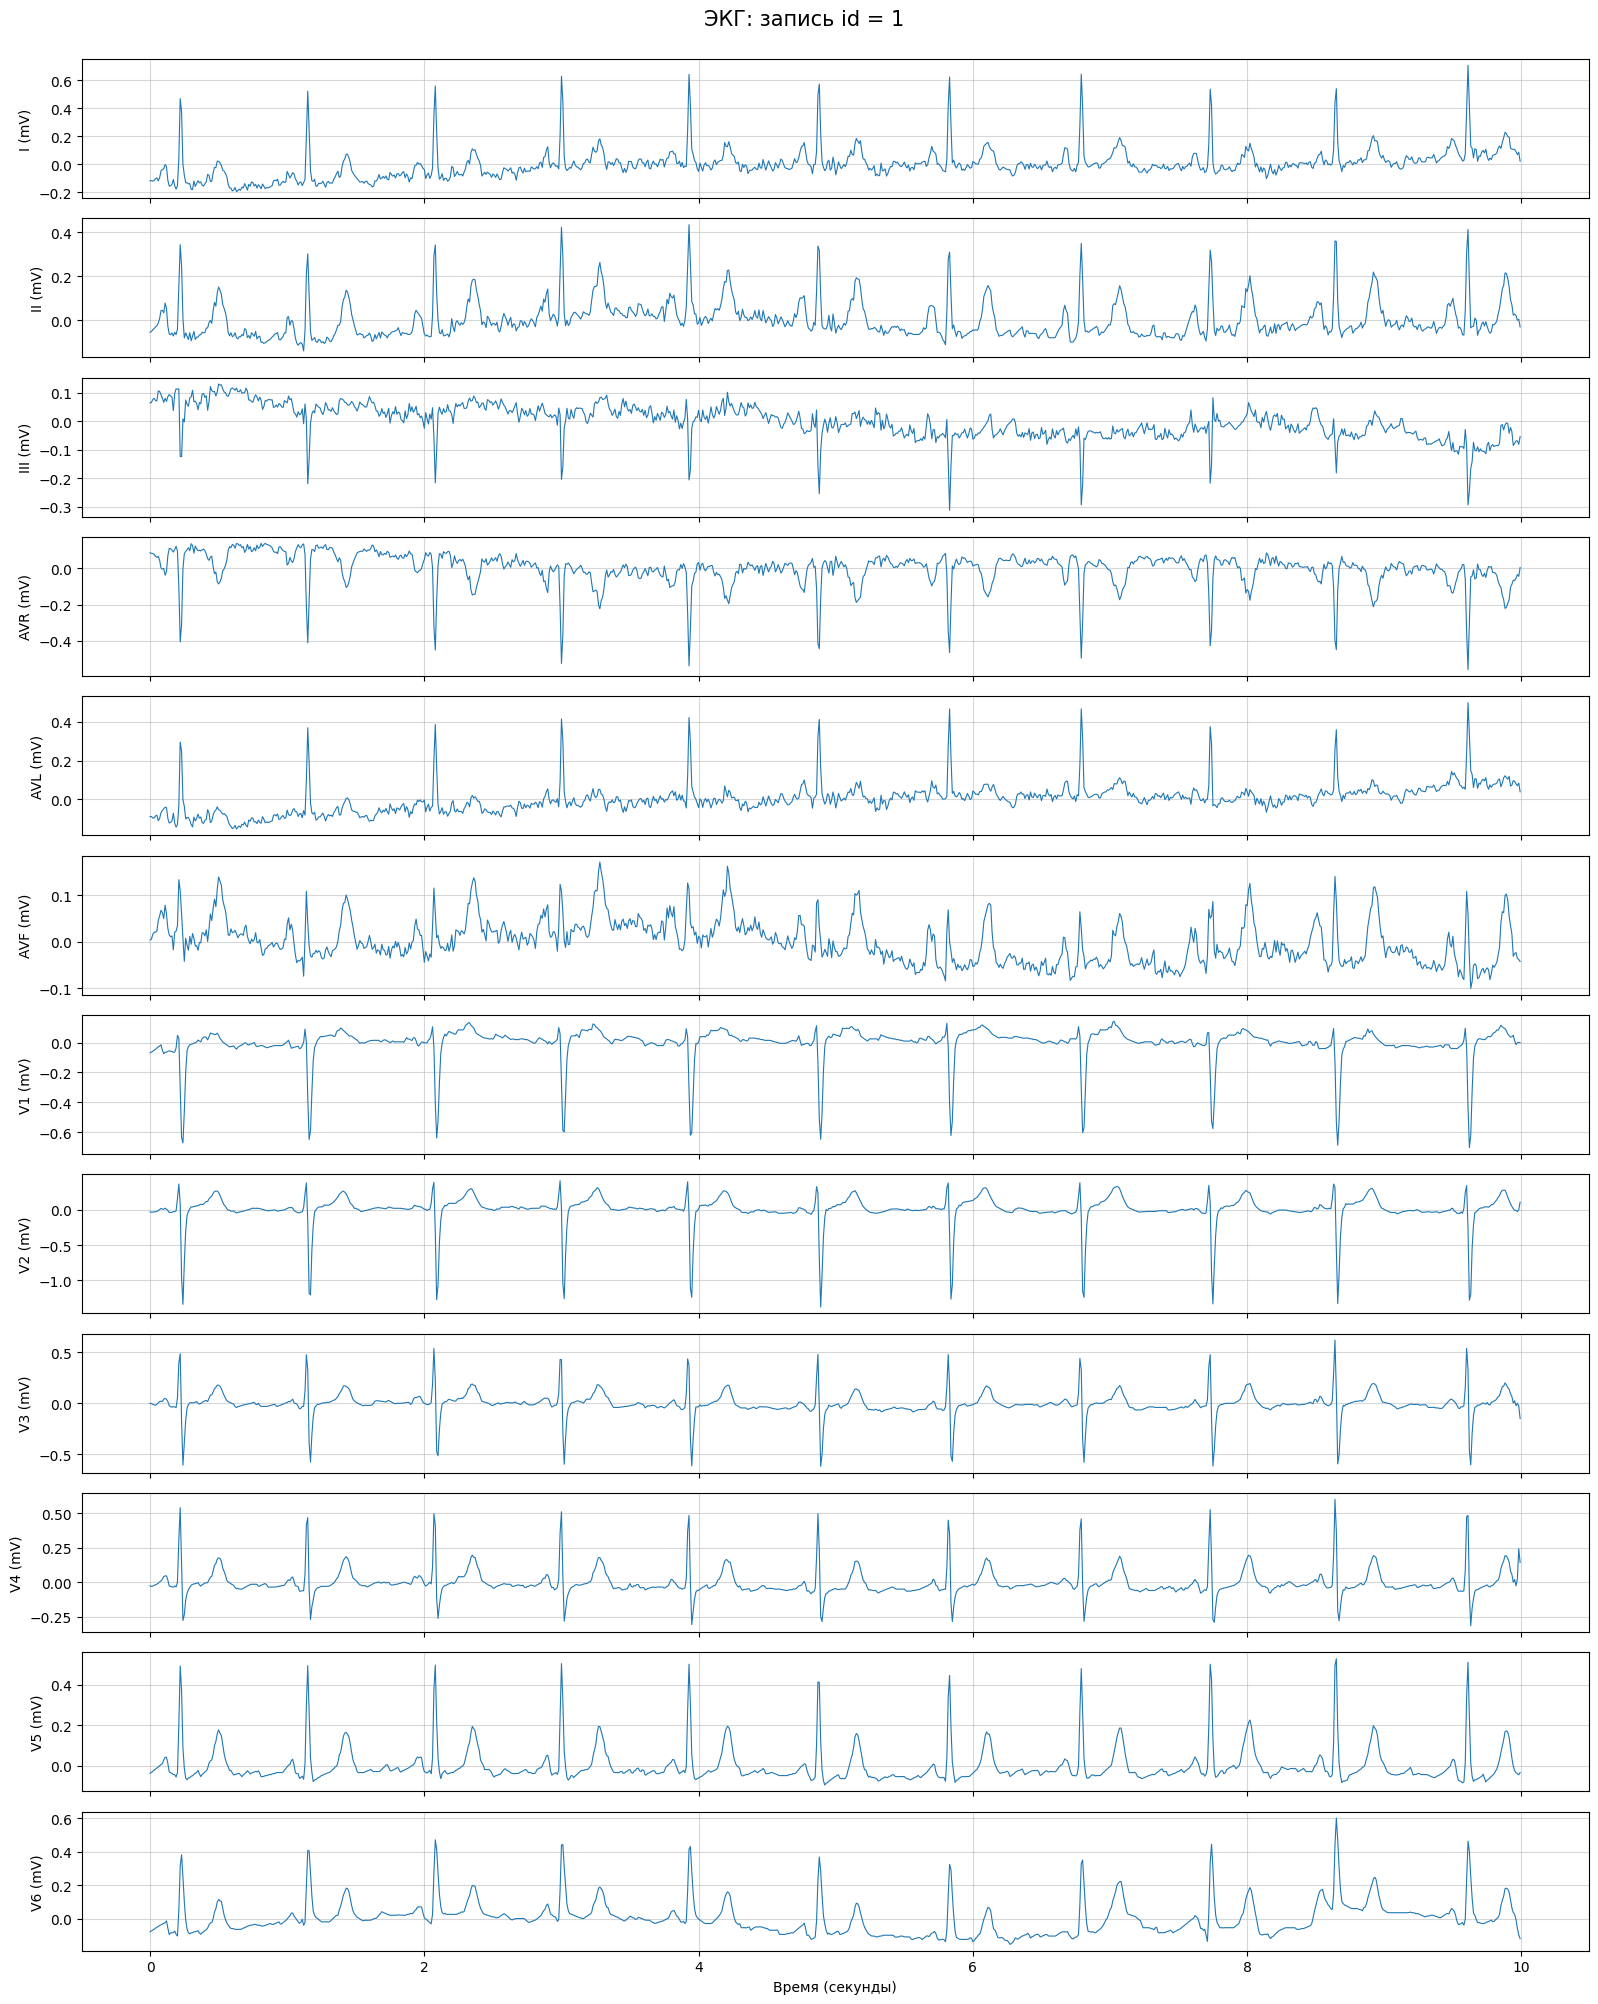

In [25]:
record = wfdb.rdrecord(str(first_record_path), physical=True)
signal = record.p_signal

time = np.arange(signal.shape[0])/record.fs
fig, axes = plt.subplots(12, 1, figsize=(16, 20), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(time, signal[:, i], linewidth=0.8)
    ax.set_ylabel(f"{record.sig_name[i]} (mV)")
    ax.grid(alpha=0.5)

axes[-1].set_xlabel("Время (секунды)")
fig.suptitle(f"ЭКГ: запись id = {first_ecg_id}", fontsize=15, y=1)

plt.tight_layout()
plt.show()

Сигналы разных отведений отличаются по форме и амплитуде. Встречаются положительные и отрицательные отклонения. Форма грудных и конечностных отведений заметно отличается.

На некоторых участках заметны медленные изменения сигнала и небольшие колебания. Это может быть связано с дрейфом и помехами/шумом.

Отведения имеют свои особенности, поэтому нужно сохранять все отведения и не считать их полностью взаимозаменяемыми.

### Разбиение на классы
(по файлу Ульяны)

In [26]:
display(labels_df.head())

,ecg_id,patient_id,strat_fold,NORM,MI,STTC,CD,HYP,n_labels,has_target_label
0,1,15709.0,3,1,0,0,0,0,1,True
1,2,13243.0,2,1,0,0,0,0,1,True
2,3,20372.0,5,1,0,0,0,0,1,True
3,4,17014.0,3,1,0,0,0,0,1,True
4,5,17448.0,4,1,0,0,0,0,1,True


### Сравнение ЭКГ-сигналов внутри каждого класса

In [27]:
records_by_class = {}

# Выбираем записи только с одним классом
for class_name in CLASSES:
    candidates = labels_df[(labels_df[class_name] == 1) & (labels_df["n_labels"] == 1)].sort_values("ecg_id")
    records_by_class[class_name] = candidates["ecg_id"].head(3).tolist() # по 3 записи для каждого класса

print("Выбранные записи:")
for class_name, ecg_ids in records_by_class.items():
    print(f"{class_name}: {ecg_ids}")

Выбранные записи:
NORM: [1, 2, 3]
MI: [8, 63, 131]
STTC: [22, 26, 28]
CD: [32, 41, 49]
HYP: [30, 96, 138]


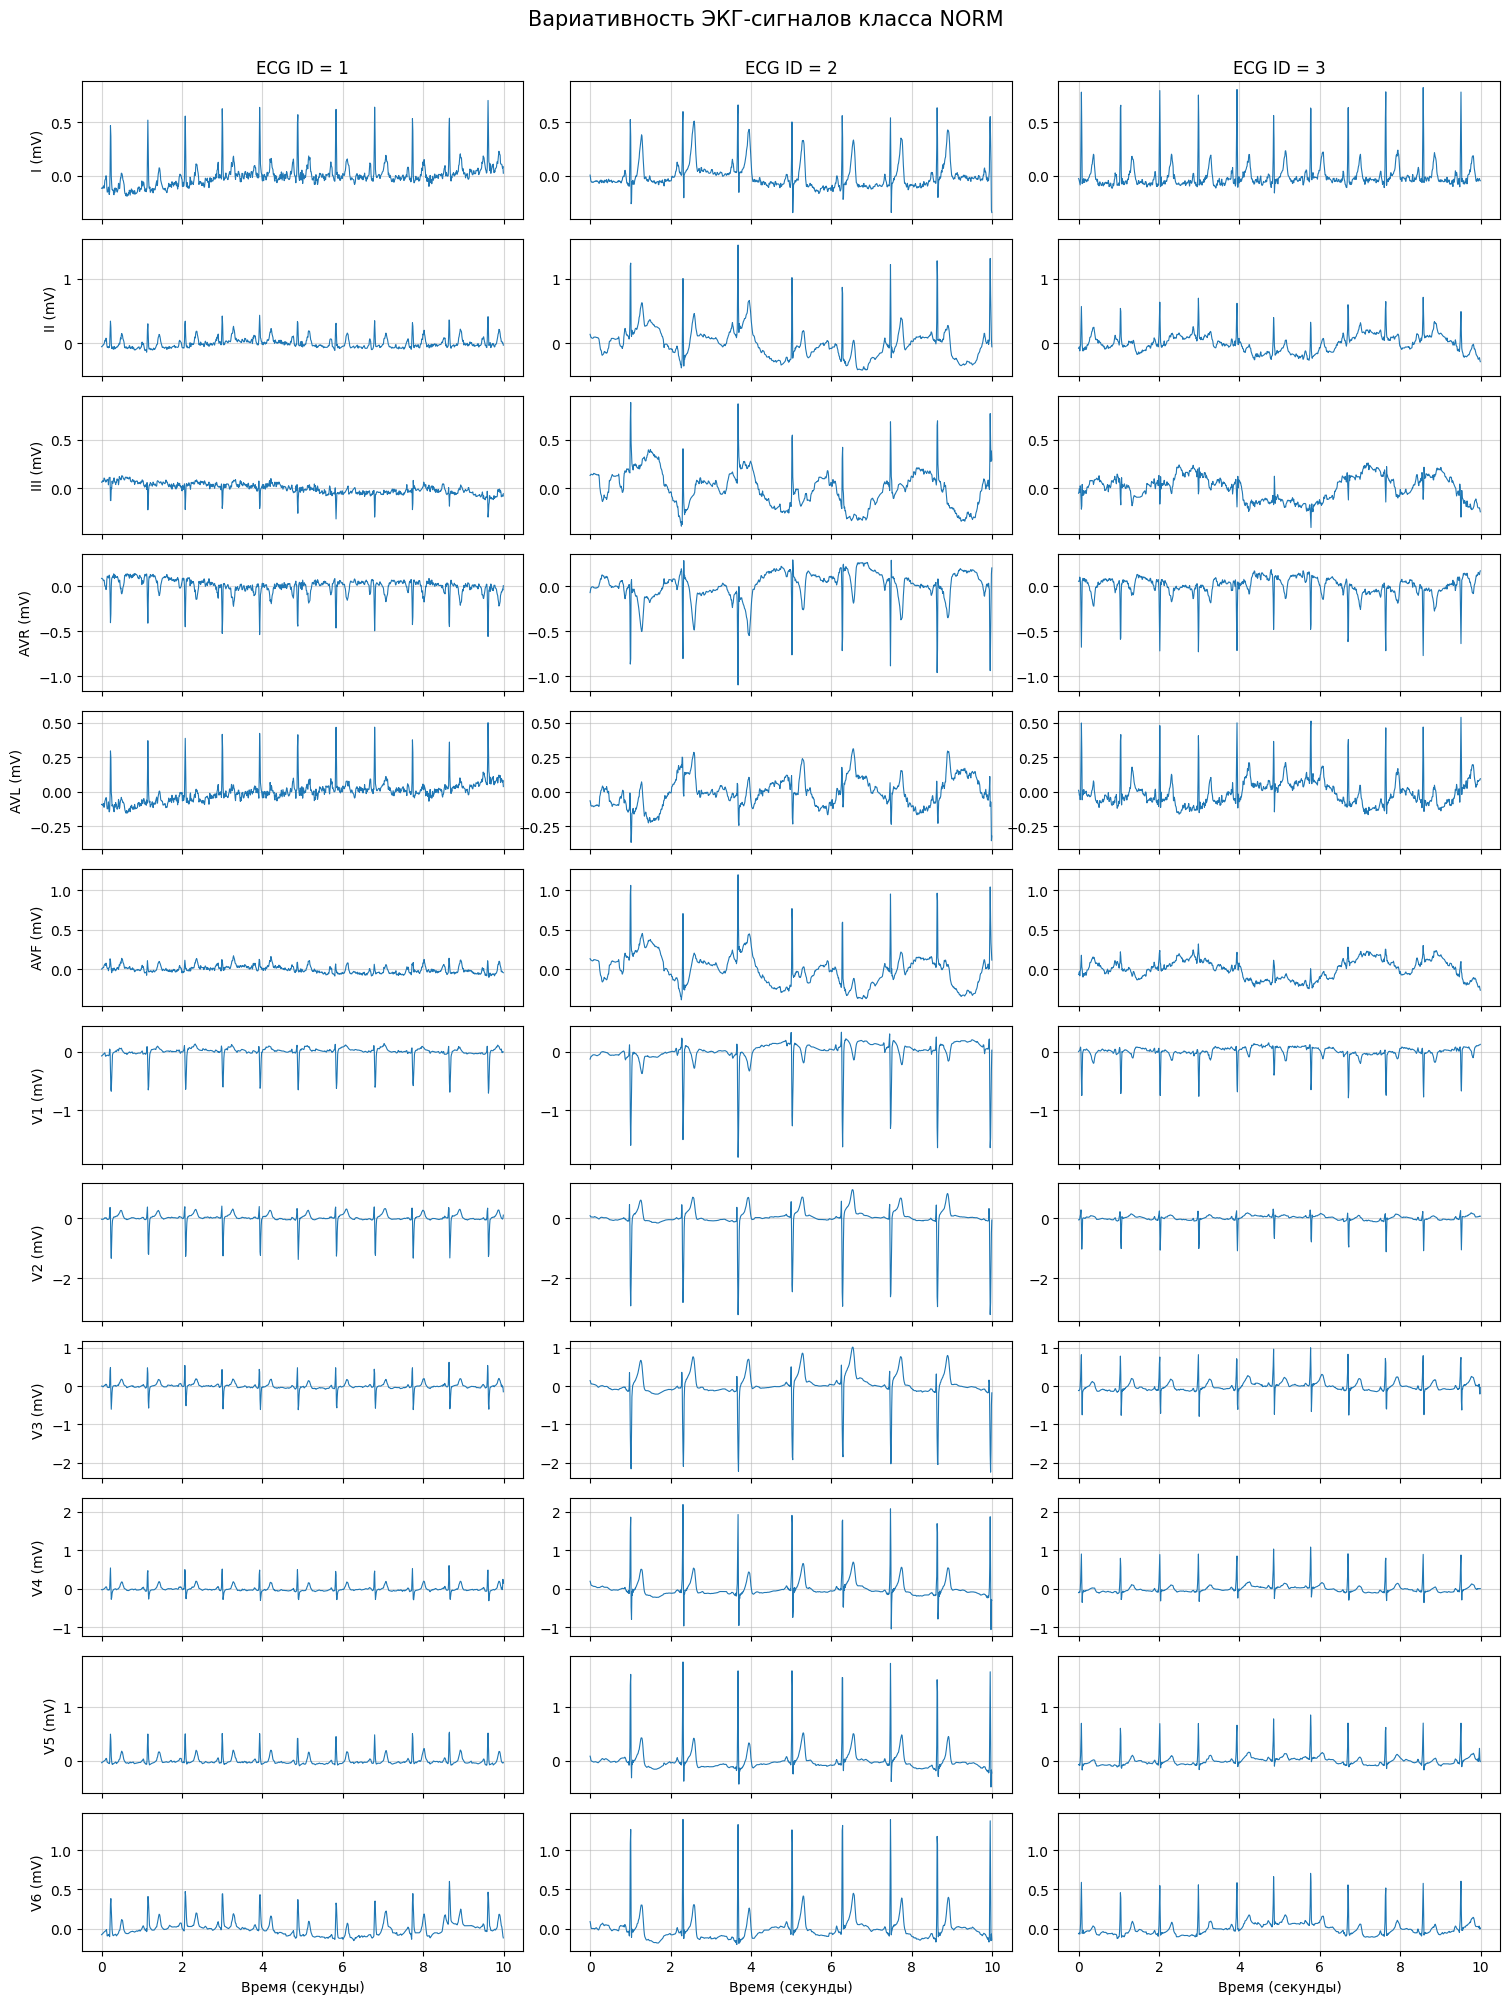

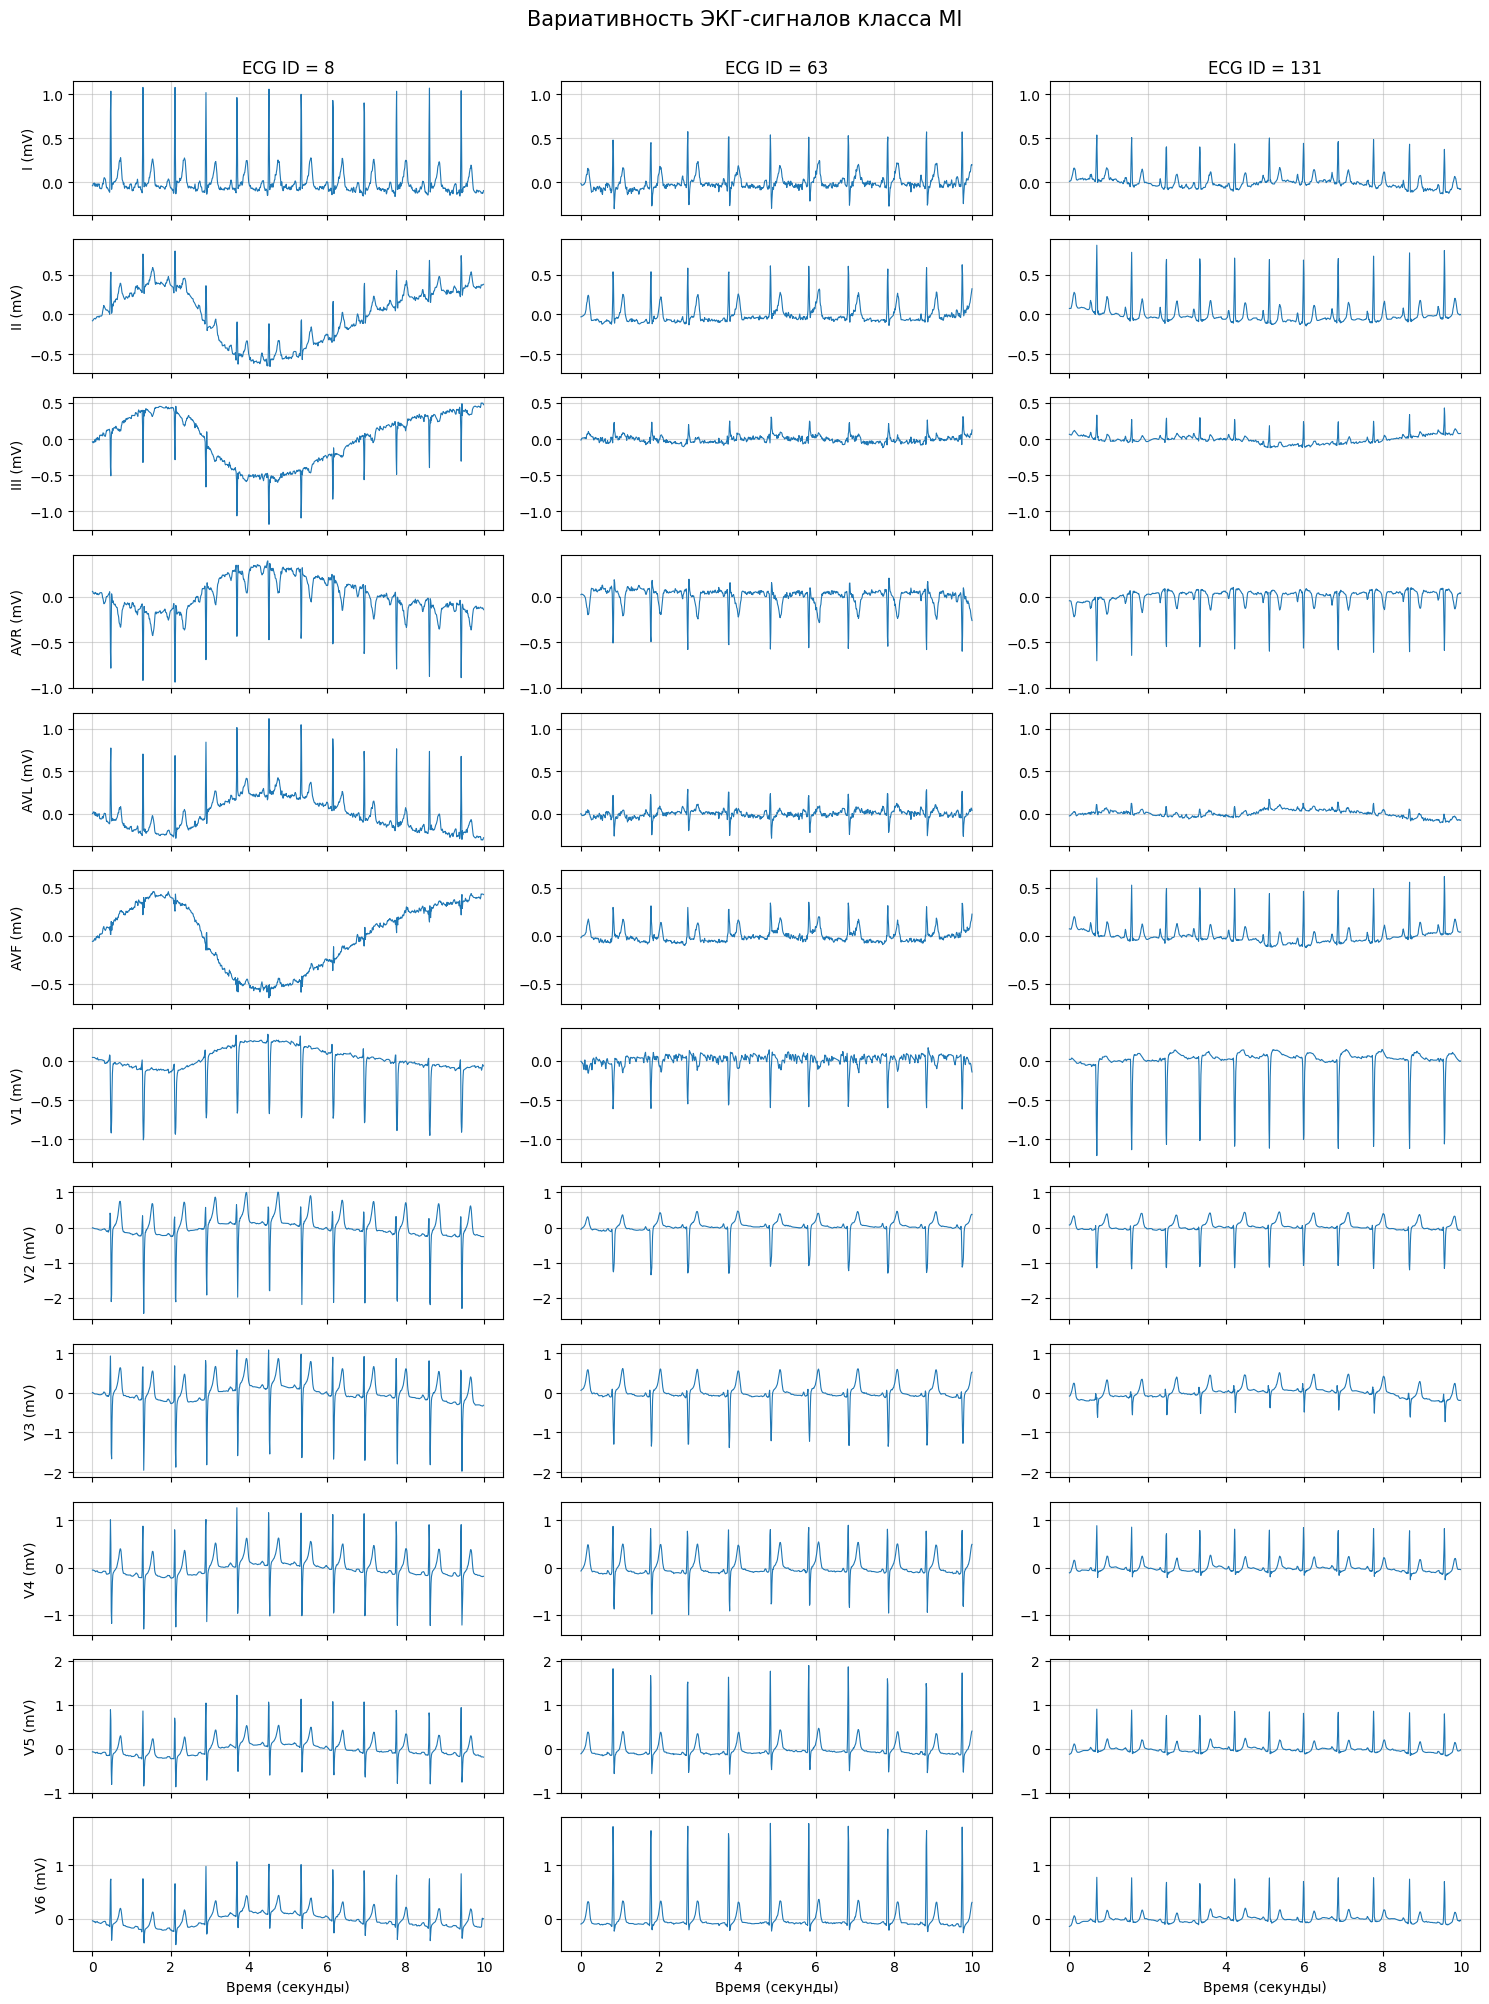

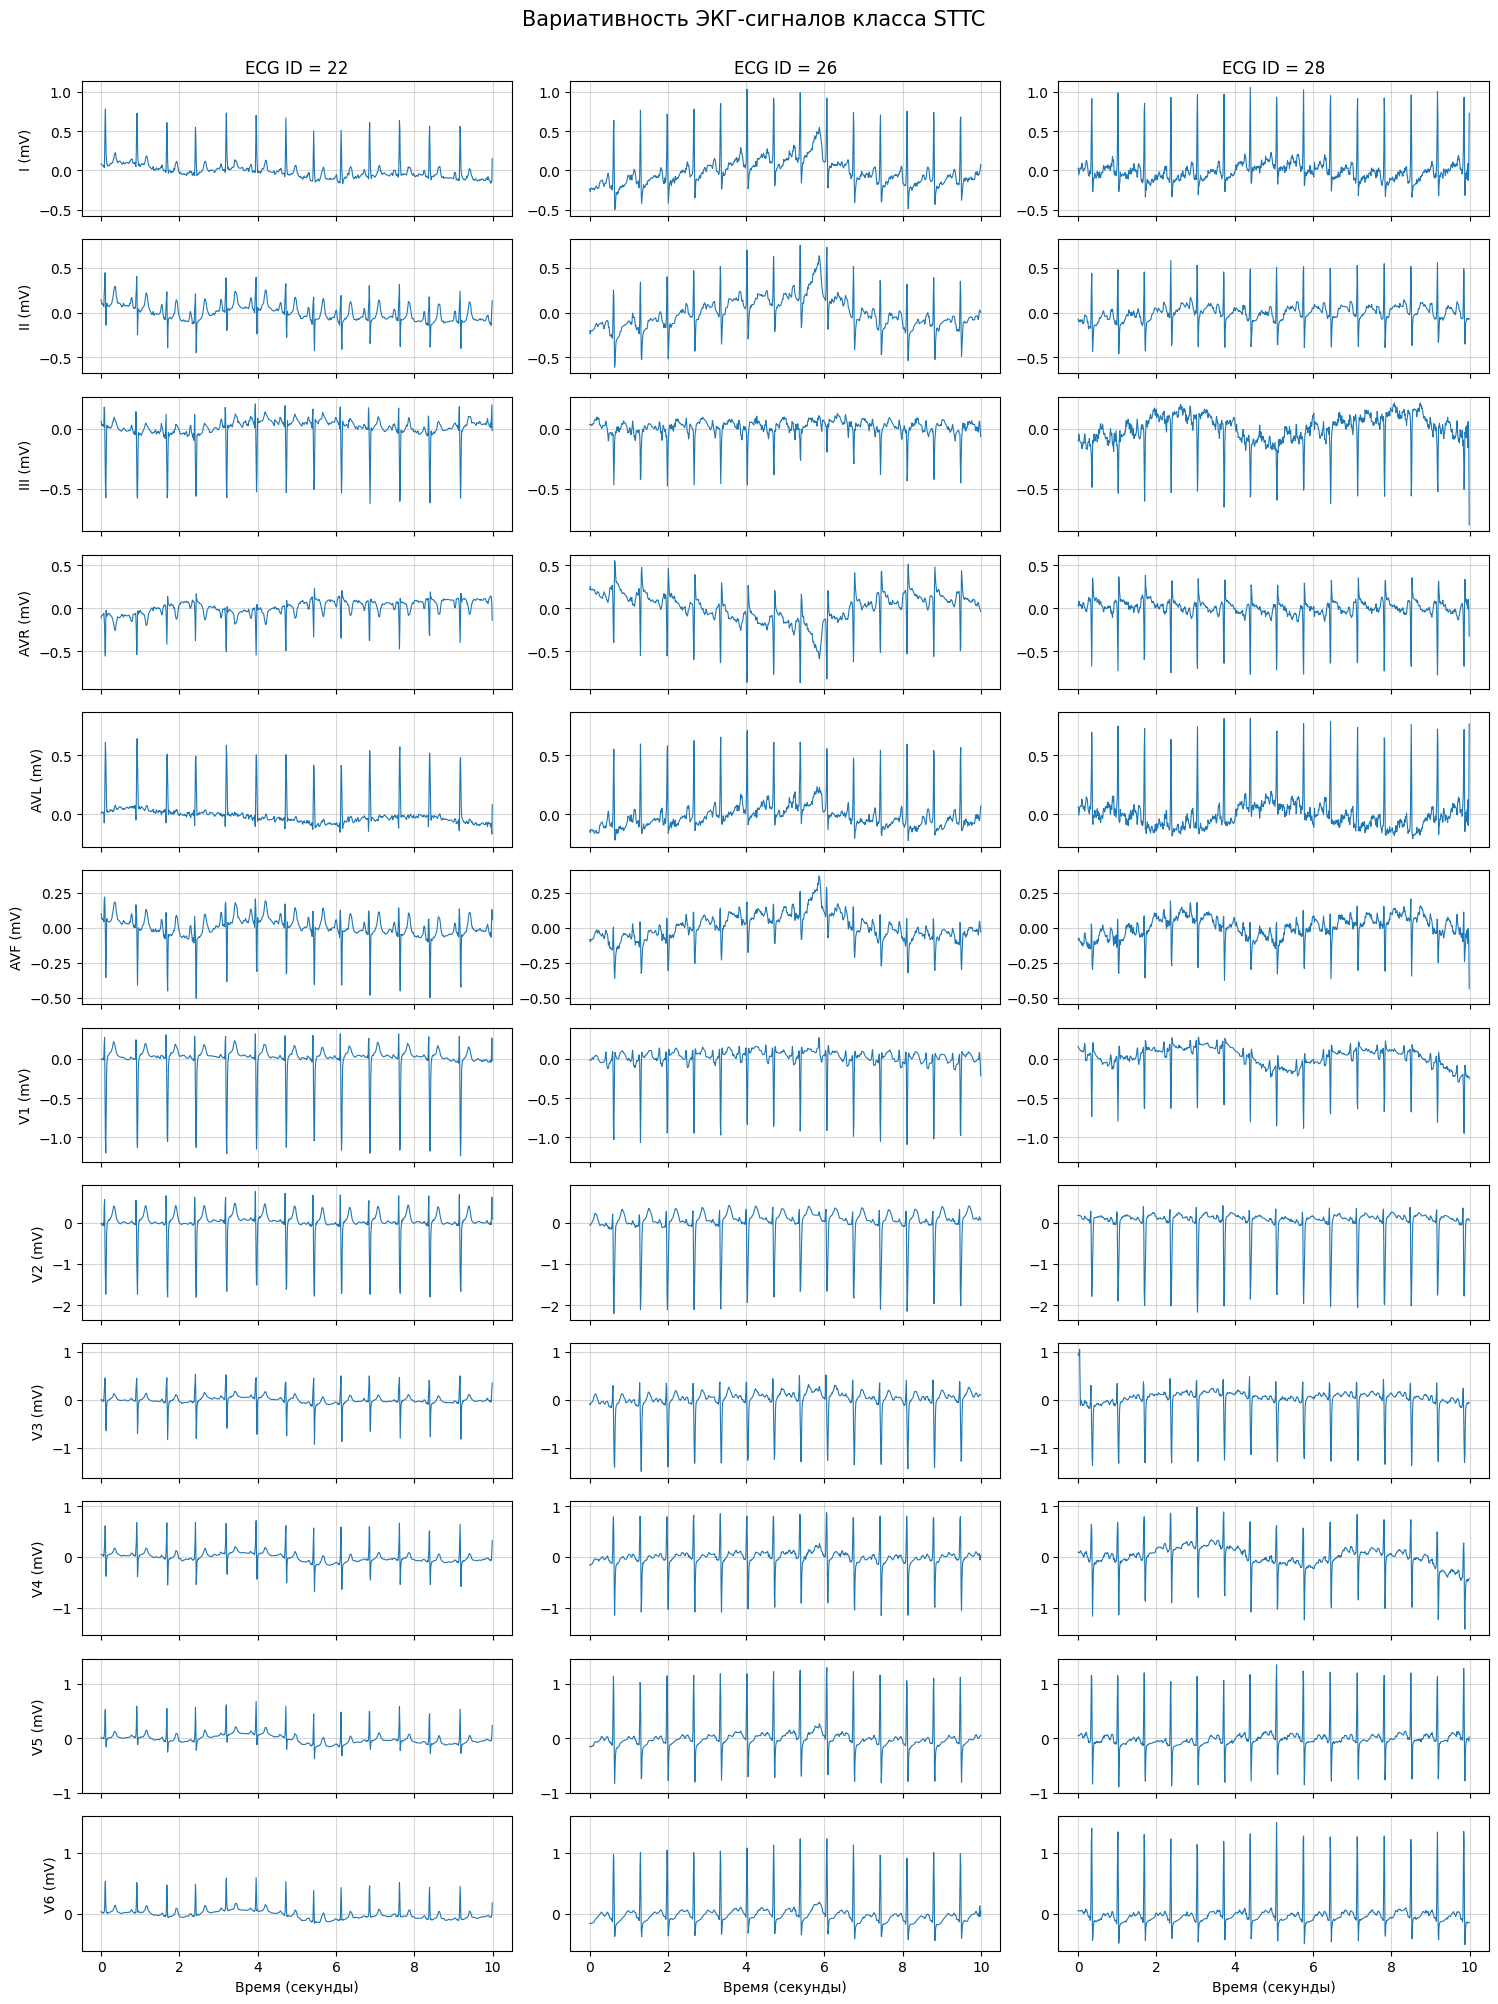

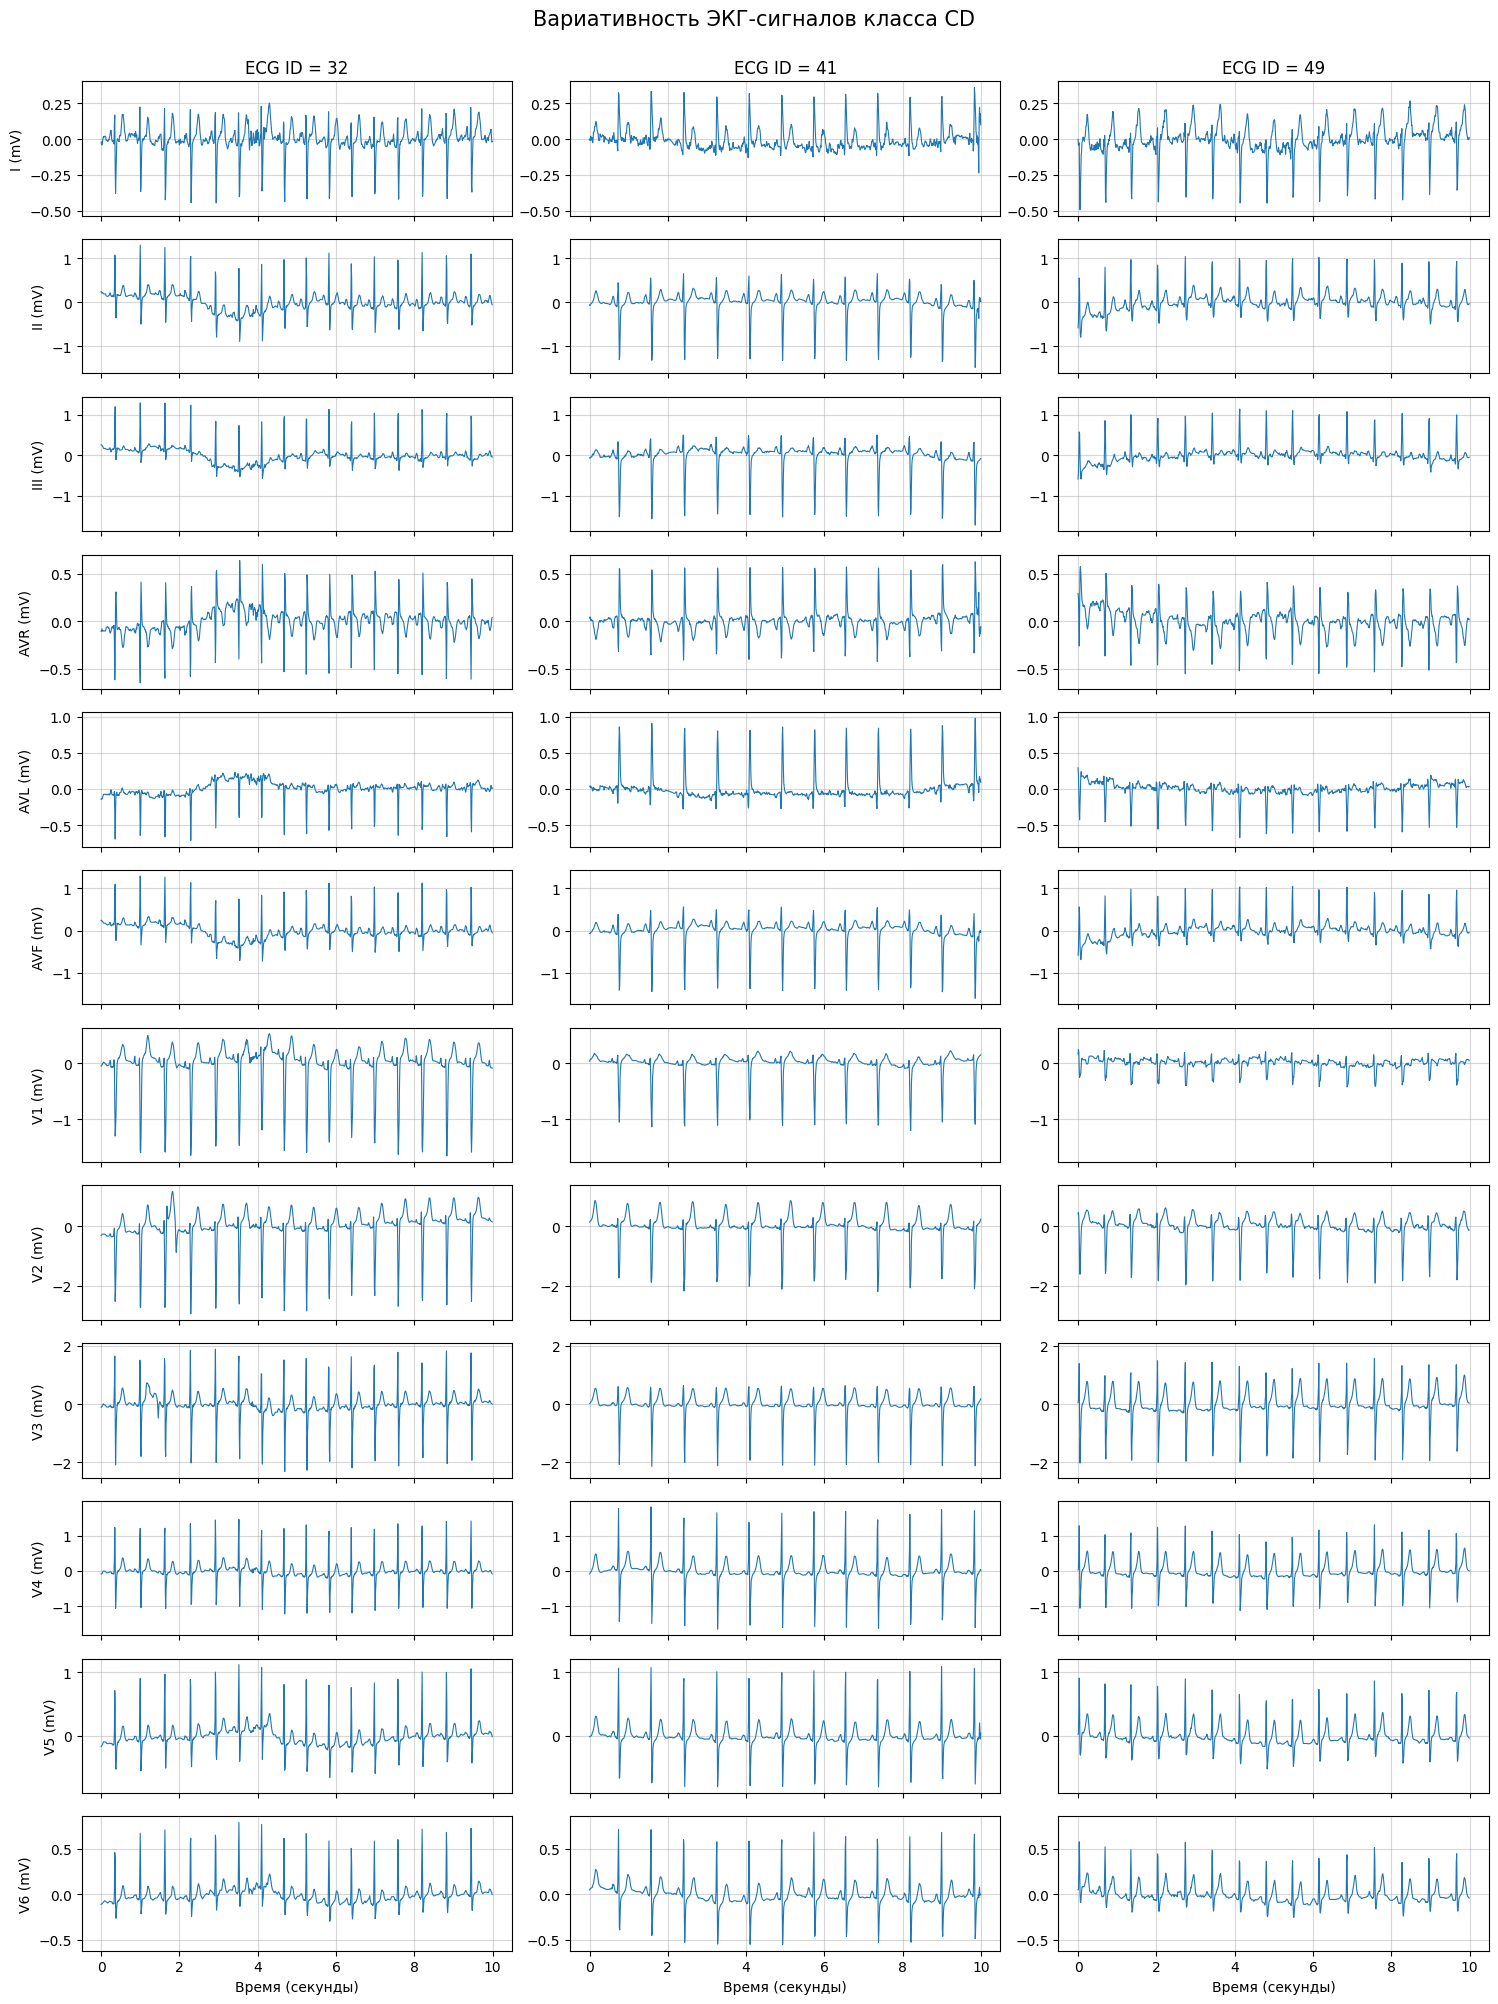

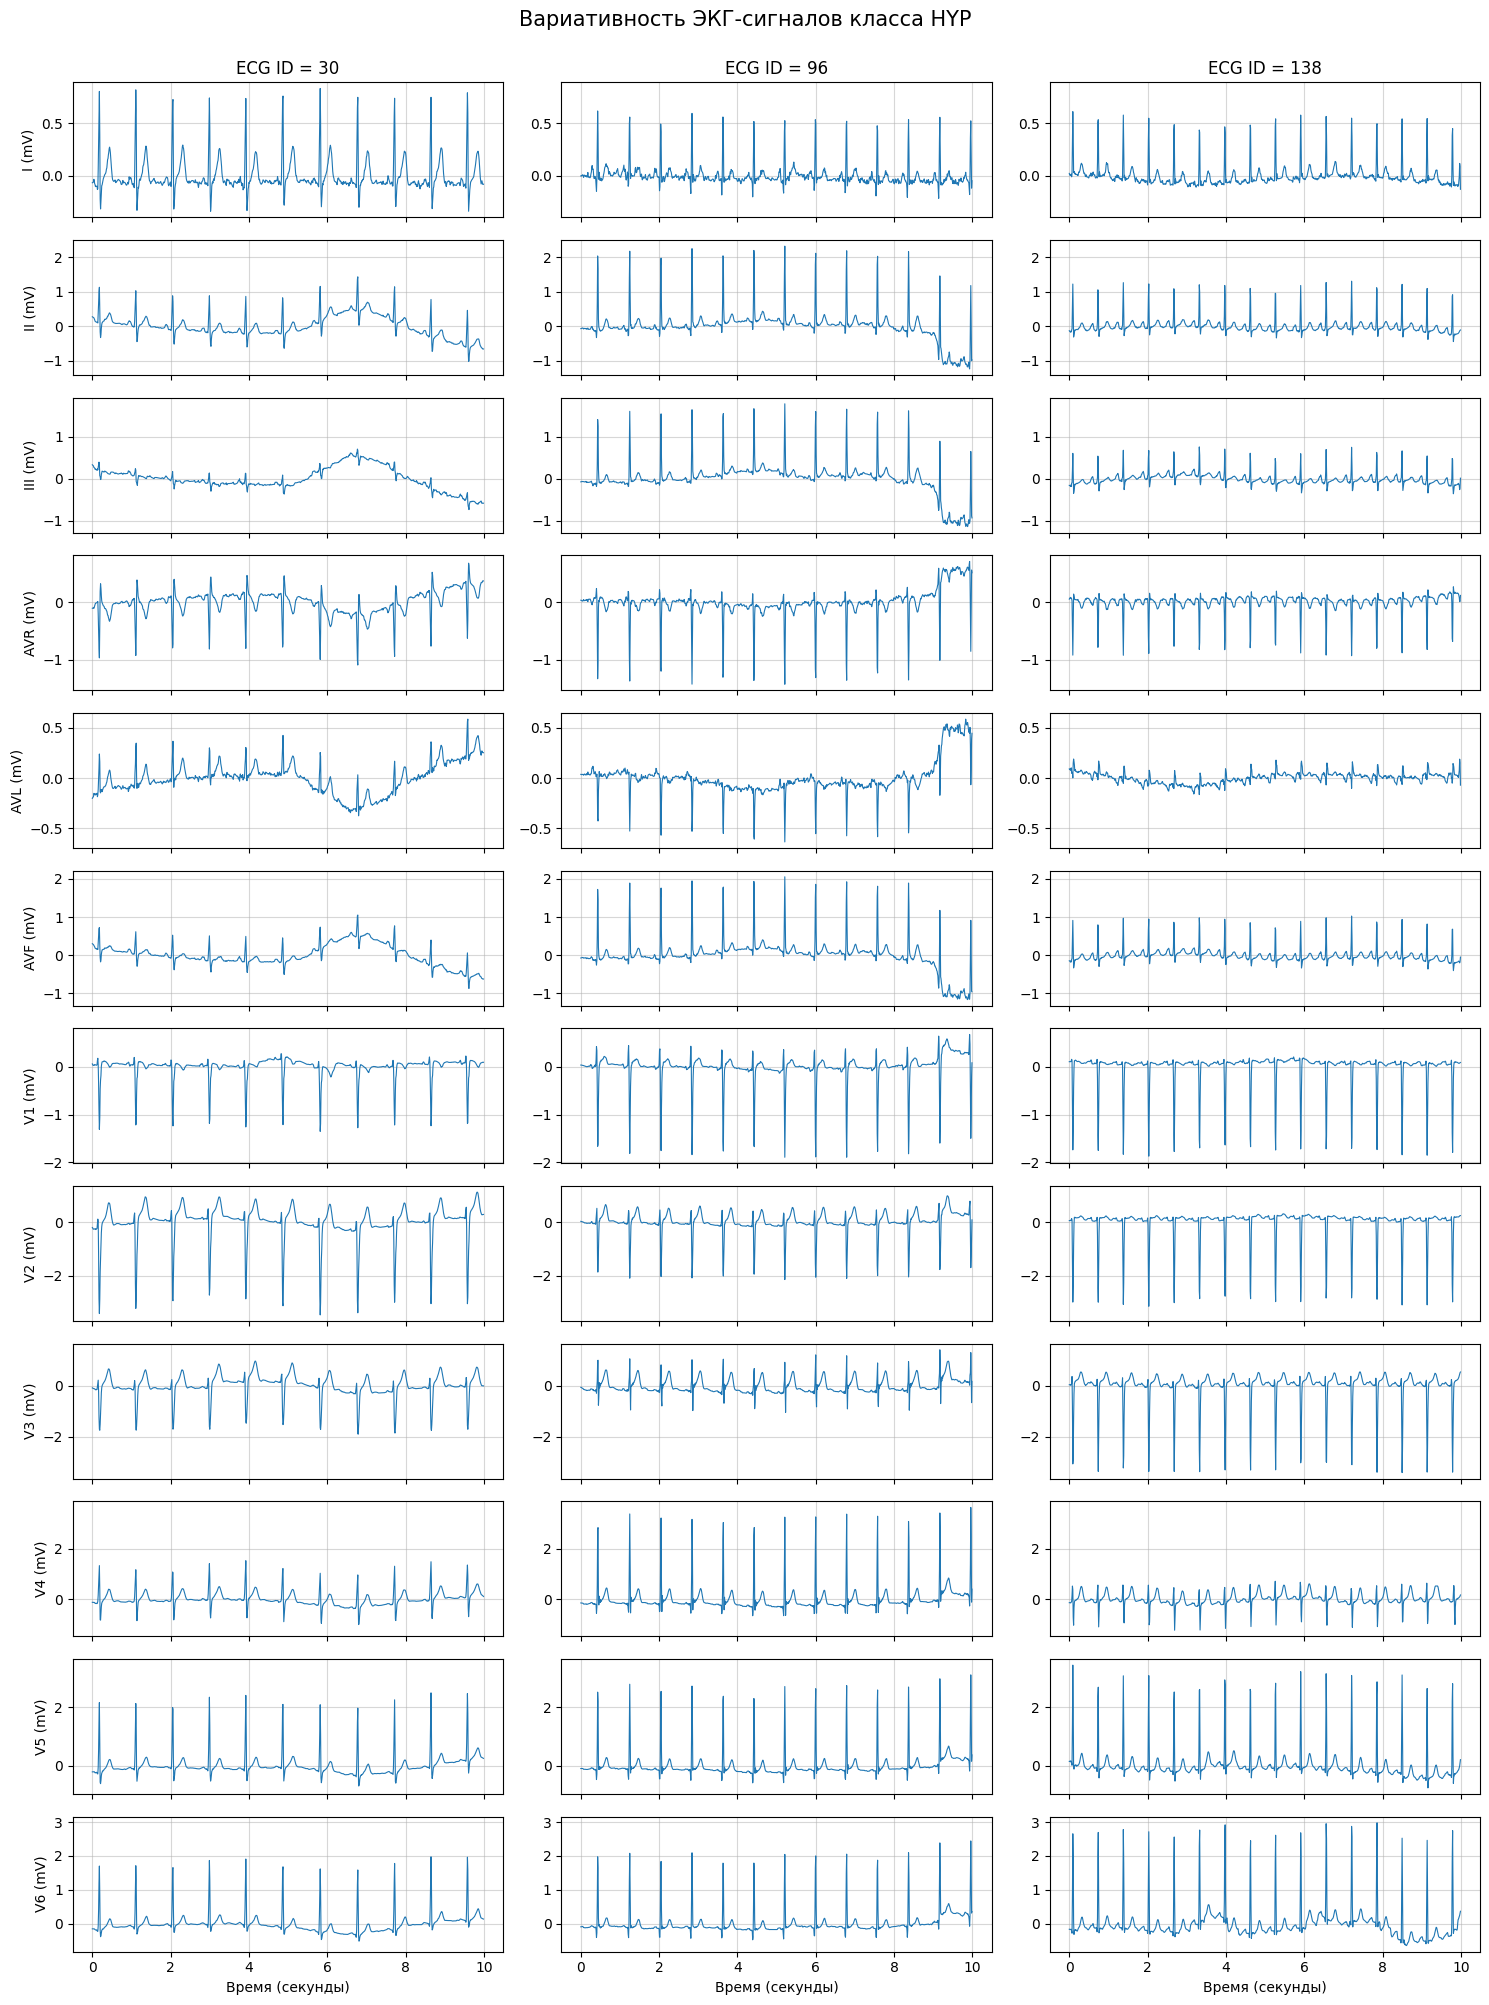

In [28]:
# отдельный график для каждого класса
for class_name, ecg_ids in records_by_class.items():

    fig, axes = plt.subplots(12, 3, figsize=(15, 20), sharex=True)

    signals = []

    for ecg_id in ecg_ids:
        row = metadata.loc[ecg_id]
        record_path = DATA_DIR / row["filename_lr"]
        rec = wfdb.rdrecord(str(record_path))
        signals.append(rec.p_signal)

    time =  np.arange(signals[0].shape[0])/rec.fs
    lead_names = rec.sig_name

    for lead_idx in range(12):
        all_values = np.concatenate([signal[:, lead_idx] for signal in signals])
        y_min = all_values.min()
        y_max = all_values.max()
        margin = (y_max - y_min) * 0.05
        for col, ecg_id in enumerate(ecg_ids):
            ax = axes[lead_idx, col]

            ax.plot(time, signals[col][:, lead_idx], linewidth=0.8)

            ax.set_ylim(y_min - margin, y_max + margin)
            ax.grid(alpha=0.5)

            if col == 0:
                ax.set_ylabel(f"{lead_names[lead_idx]} (mV)")

            if lead_idx == 0:
                ax.set_title(f"ECG ID = {ecg_id}")

            if lead_idx == 11:
                ax.set_xlabel("Время (секунды)")

    fig.suptitle(f"Вариативность ЭКГ-сигналов класса {class_name}", fontsize=15, y=1)

    plt.tight_layout()
    plt.show()

Для оценки разнообразия сигналов визуализированы первые три записи **с одной меткой** для каждого из классов: NORM, MI, STTC, CD и HYP.

Наблюдения:
- Даже внутри одного класса есть видимые различия в форме и амплитуде сигналов -> одна запись не может полностью характеризовать особенности всего класса -> важно учитывать внутриклассовую вариативность и не строить выводы по одному или нескольким представителям класса.

- При подготовке входных данных может потребоваться единый способ масштабирования/нормализации. Но значимые различия между отведениями при этом должны остаться.

### Проверка целостности значений

In [29]:
quality_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    quality_results.append({
        "ecg_id": ecg_id,
        "nan_count": np.isnan(ecg_signal).sum(),
        "inf_count": np.isinf(ecg_signal).sum()})

quality_df = pd.DataFrame(quality_results)

print("Всего записей:", len(quality_df))
print("Записей с NaN:", (quality_df["nan_count"] > 0).sum())
print("Записей с Inf:", (quality_df["inf_count"] > 0).sum())

Всего записей: 21799
Записей с NaN: 0
Записей с Inf: 0


Во всех записях отсутствуют пропуски и бесконечные значения

### Поиск плоских участков

In [30]:
def longest_constant_part(values):
    """Максимальная длина последовательности одинаковых значений"""
    changes = np.concatenate([[True], values[1:] != values[:-1]])
    starts = np.flatnonzero(changes)
    lengths = np.diff(np.concatenate([starts, [len(values)]]))

    max_idx = np.argmax(lengths)
    return lengths[max_idx], values[starts[max_idx]]


constant_parts = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    for lead_idx, lead in enumerate(rec.sig_name):
        part_length, _ = longest_constant_part(ecg_signal[:, lead_idx])

        constant_parts.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "max_constant_samples": part_length,
            "max_constant_seconds": part_length/rec.fs})

constant_parts_df = pd.DataFrame(constant_parts)

# подозрительные участки - нет изменений 0,5 секунды (50 samples) и дольше
suspicious_parts = constant_parts_df[constant_parts_df["max_constant_samples"] >= 50].copy()

print("Проверено отведений:", len(constant_parts_df))
print("Отведений с постоянным участком от 0,5 секунды:", len(suspicious_parts))
print("Записей с такими участками:", suspicious_parts["ecg_id"].nunique())

print("10 самых длинных постоянных участков:")
display(constant_parts_df.sort_values("max_constant_samples", ascending=False).head(10))

Проверено отведений: 261588
Отведений с постоянным участком от 0,5 секунды: 7
Записей с такими участками: 4
10 самых длинных постоянных участков:


,ecg_id,lead,max_constant_samples,max_constant_seconds
152290,12722,V5,1000,10.00
240083,20045,V6,927,9.27
152291,12722,V6,828,8.28
231131,19299,V6,714,7.14
152289,12722,V4,369,3.69
231128,19299,V3,139,1.39
146638,12251,V5,85,0.85
133269,11132,V4,44,0.44
199242,16641,V1,43,0.43
81549,6816,V4,42,0.42


In [31]:
def get_longest_constant_part(values):
    """Координаты и длина самой длинной части"""
    changes = np.concatenate([[True], values[1:] != values[:-1]])
    starts = np.flatnonzero(changes)
    ends = np.concatenate([starts[1:], [len(values)]])
    lengths = ends - starts

    idx = np.argmax(lengths)

    return starts[idx], ends[idx], lengths[idx]


details = []

for _, item in suspicious_parts.iterrows():
    ecg_id = item["ecg_id"]
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = ecg_signal[:, lead_idx]

    start, end, length = get_longest_constant_part(values)

    details.append({
        "ecg_id": ecg_id,
        "lead": lead,
        "start_sec": start / rec.fs,
        "end_sec": end / rec.fs,
        "duration_sec": length / rec.fs,
        "constant_value_mV": values[start],
        "unique_values": len(np.unique(values))
    })

details_df = pd.DataFrame(details)

print("Подозрительные участки:")
display(details_df.sort_values("duration_sec", ascending=False).round(4))

Подозрительные участки:


,ecg_id,lead,start_sec,end_sec,duration_sec,constant_value_mV,unique_values
2,12722,V5,0.00,10.00,10.00,0.000,1
6,20045,V6,0.73,10.00,9.27,-20.022,65
3,12722,V6,1.72,10.00,8.28,0.000,26
5,19299,V6,2.86,10.00,7.14,0.000,204
1,12722,V4,6.31,10.00,3.69,0.000,354
4,19299,V3,8.61,10.00,1.39,-1.279,340
0,12251,V5,7.73,8.58,0.85,0.924,483


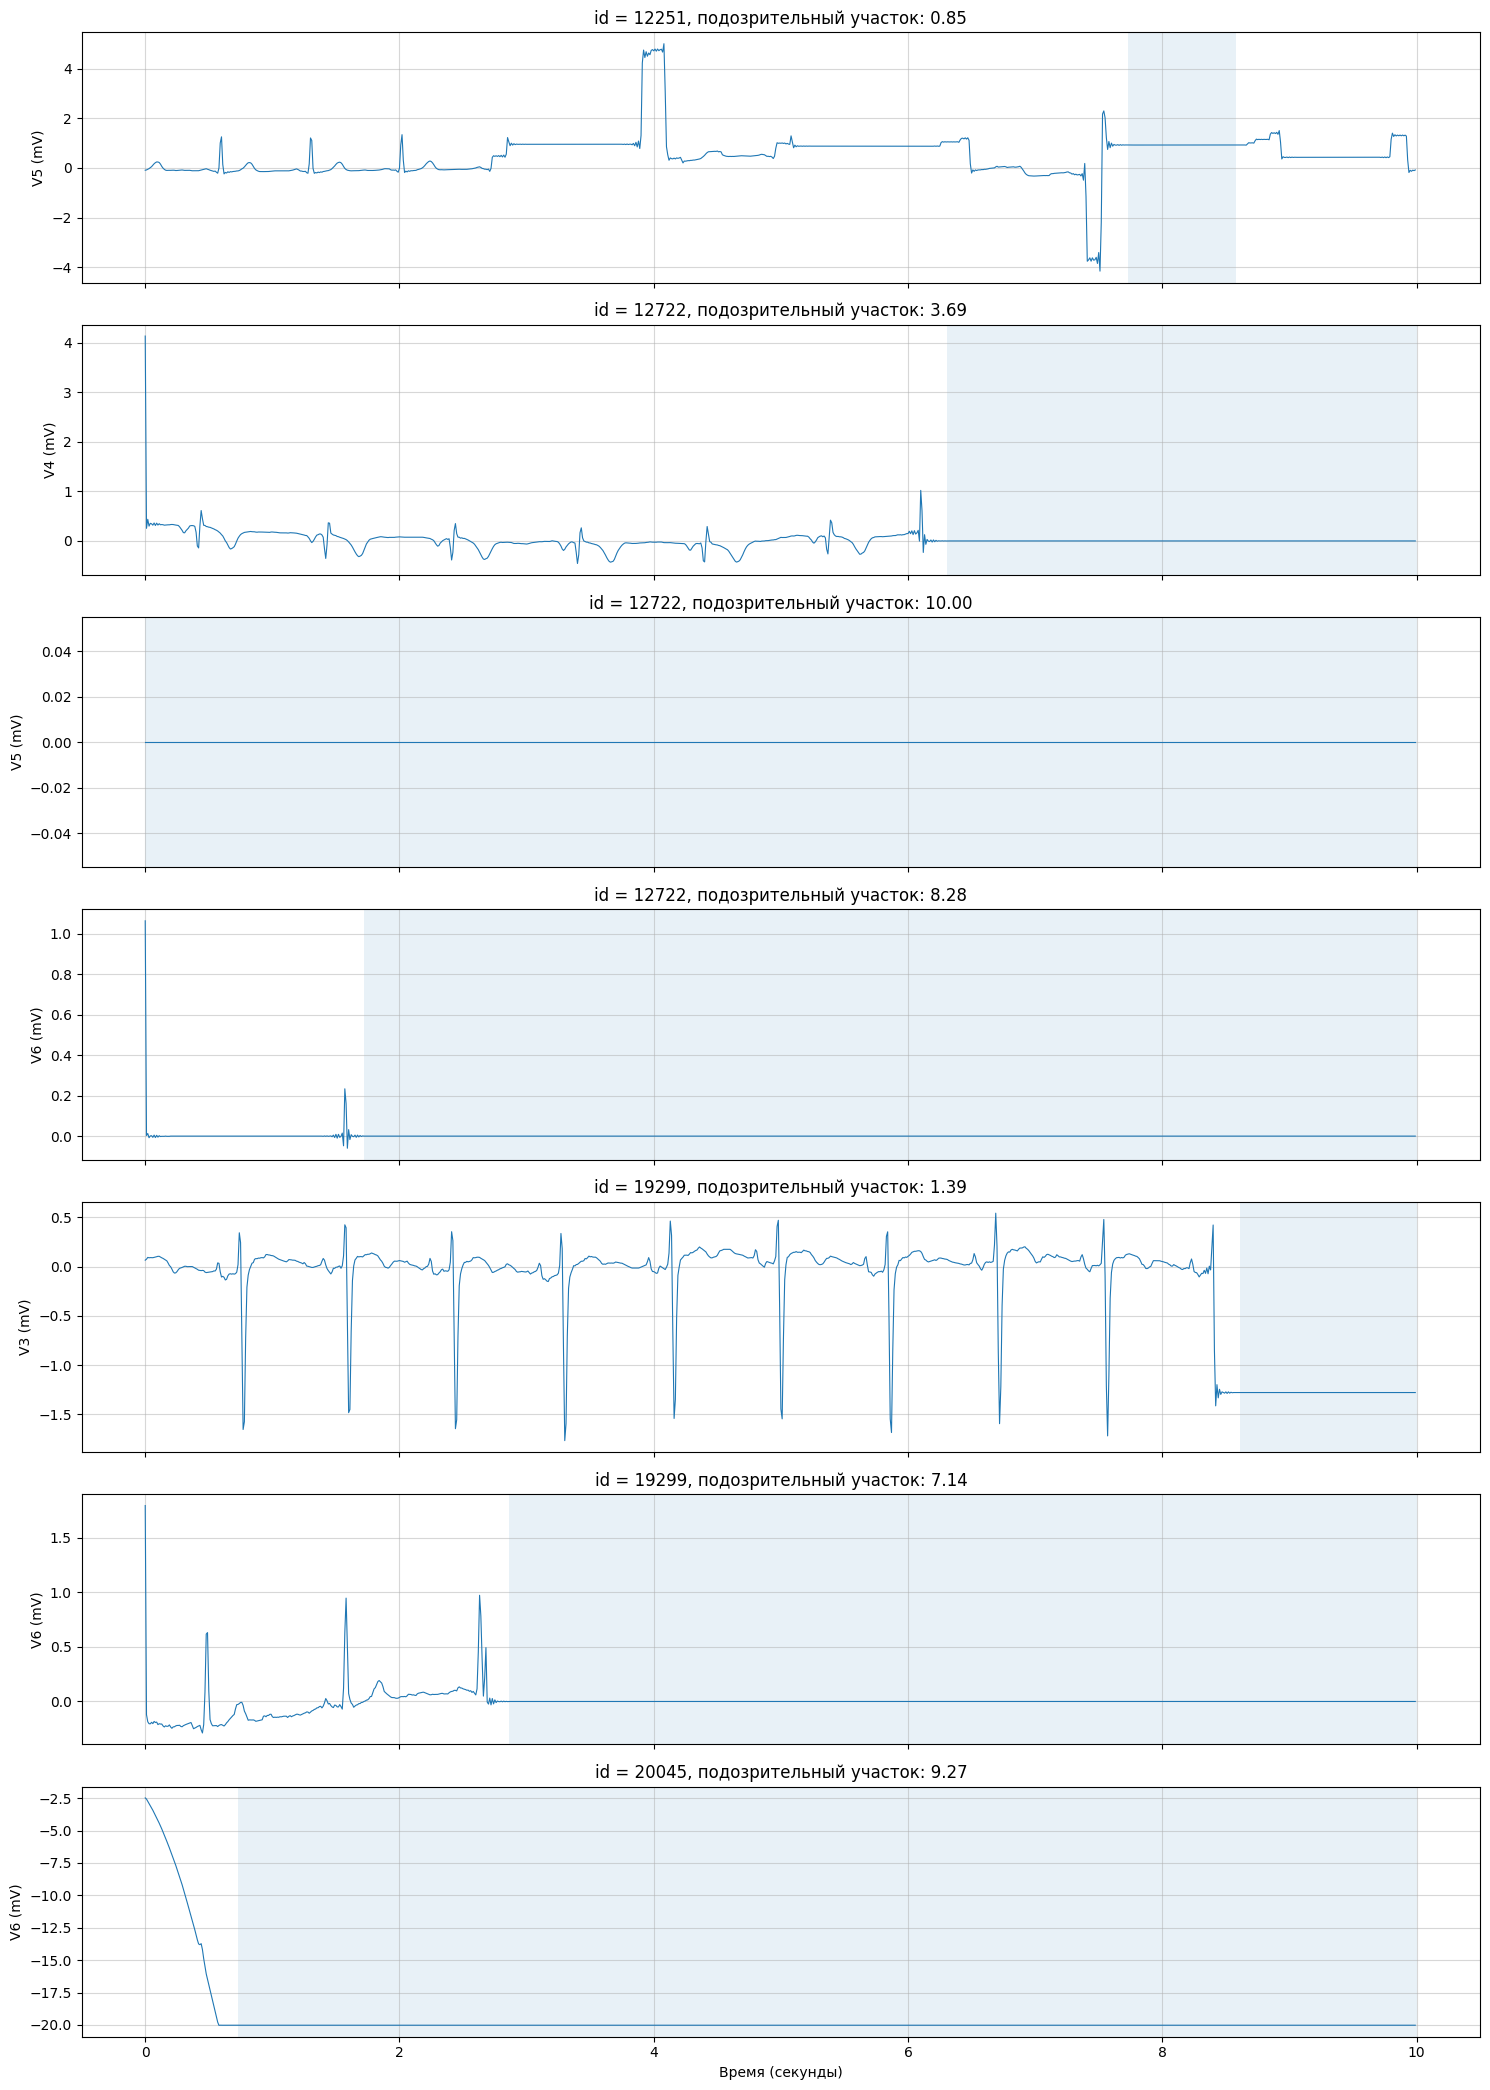

In [32]:
fig, axes = plt.subplots(len(details_df), 1, figsize=(15, 3 * len(details_df)), sharex=True)

for ax, (_, item) in zip(axes, details_df.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    ecg_signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = ecg_signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    ax.plot(time, values, linewidth=0.8)

    # подозрительный участок
    ax.axvspan(item["start_sec"], item["end_sec"], alpha=0.1)

    ax.set_title(f"id = {ecg_id}, подозрительный участок: {item['duration_sec']:.2f}")

    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)

axes[-1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

**Вывод:**

В 4 записях найдено 7 отведений с непрерывными постоянными участками длительностью не менее 0,5 секунды.

Наиболее выраженные случаи в записях 12722, 20045 и 19299.
- В записи 12722 отведение V5 оставалось постоянным на протяжении всего времени. Отведения V4 и V6 этой записи тоже содержат длительный постоянный участок.
- В записи 20045 отведение V6 большую часть времени было неизменным и очень низким.

Это может быть потеря или искажение данных в отдельных каналах -> учесть при подготовке входных данных.

*Примечание:* проверяю только точное равенство соседних значений. Участки с малыми, но ненулевыми изменениями этот способ не проверяет.

### Проверка амплитуд

In [33]:
amplitude_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    for lead_idx, lead in enumerate(rec.sig_name):
        values = signal[:, lead_idx]

        amplitude_results.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "min_mV": np.min(values),
            "max_mV": np.max(values),
            "max_abs_mV": np.max(np.abs(values)),
            "range_mV": np.ptp(values)})

amplitude_df = pd.DataFrame(amplitude_results)
display(amplitude_df.head())

,ecg_id,lead,min_mV,max_mV,max_abs_mV,range_mV
0,1,I,-0.195,0.706,0.706,0.901
1,1,II,-0.140,0.435,0.435,0.575
2,1,III,-0.312,0.130,0.312,0.442
3,1,AVR,-0.559,0.138,0.559,0.697
4,1,AVL,-0.155,0.500,0.500,0.655


Для поиска экстремально больших значений найдем 95-й, 99-й и 99.9-й перцентили отдельно для каждого отведения.

In [34]:
lead_order = rec.sig_name

amplitude_percentiles = amplitude_df.groupby("lead")["max_abs_mV"].quantile([0.95, 0.99, 0.999]).unstack()
amplitude_percentiles.columns = ["p95_mV", "p99_mV", "p99_9_mV"]
amplitude_percentiles = amplitude_percentiles.reindex(lead_order)

display(amplitude_percentiles.round(2))

,p95_mV,p99_mV,p99_9_mV
lead,,,
I,1.46,1.91,2.81
II,1.55,2.11,3.08
III,1.65,2.42,3.41
AVR,1.23,1.61,2.62
AVL,1.35,1.86,2.77
AVF,1.44,2.09,2.93
V1,1.98,2.91,5.70
V2,2.89,4.16,6.75
V3,2.85,4.29,7.04


Видно, что каждое отведение имеет собственное распределение максимальной абсолютной амплитуды -> амплитудные диапазоны различаются между отведениями и каждый из них надо рассматривать отдельно.

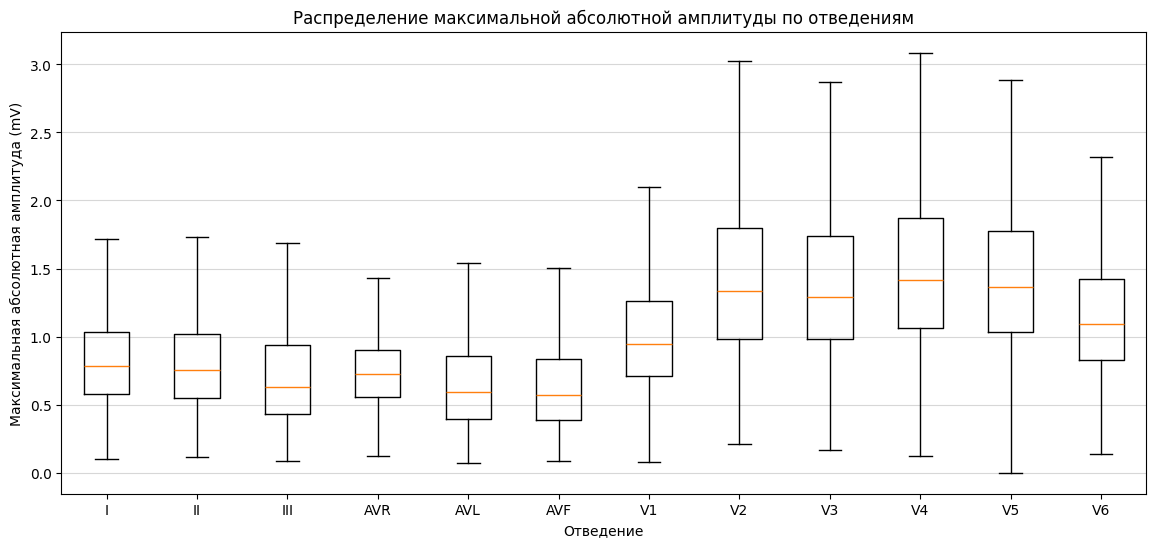

In [35]:
plt.figure(figsize=(14, 6))

amplitude_data = [amplitude_df.loc[amplitude_df["lead"] == lead, "max_abs_mV"] for lead in lead_order]

plt.boxplot(amplitude_data, tick_labels=lead_order, showfliers=False)
plt.title("Распределение максимальной абсолютной амплитуды по отведениям")
plt.xlabel("Отведение")
plt.ylabel("Максимальная абсолютная амплитуда (mV)")
plt.grid(axis="y", alpha=0.5)
plt.show()

У грудных отведений более высокое значение максимальной абсолютной амплитуды и бОльший разброс, чем у конечностных отведений.

-> необычные значения амплитуды будем сравнивать с перцентильным порогом отдельно для каждого отведения

In [36]:
amplitude_check = amplitude_df.join(amplitude_percentiles["p99_9_mV"], on="lead")
extreme_amplitudes = amplitude_check[amplitude_check["max_abs_mV"] > amplitude_check["p99_9_mV"]].copy()

print("Количество отведений с амплитудой выше p99.9:", len(extreme_amplitudes))
print("Количество ЭКГ-записей c такой амплитудой:", extreme_amplitudes["ecg_id"].nunique())

display(extreme_amplitudes.sort_values("max_abs_mV", ascending=False).head(10).round(3))

Количество отведений с амплитудой выше p99.9: 263
Количество ЭКГ-записей c такой амплитудой: 175


,ecg_id,lead,min_mV,max_mV,max_abs_mV,range_mV,p99_9_mV
240083,20045,V6,-20.032,-2.483,20.032,17.549,5.603
108294,9048,V1,-17.825,2.072,17.825,19.897,5.704
132118,11036,V5,2.278,17.212,17.212,14.934,6.295
129308,10802,V3,-16.320,4.539,16.320,20.859,7.045
234018,19540,V1,-16.126,2.846,16.126,18.972,5.704
148050,12369,V1,-15.395,3.966,15.395,19.361,5.704
176156,14716,V3,-14.916,2.306,14.916,17.222,7.045
260144,21717,V3,-14.725,2.910,14.725,17.635,7.045
171910,14362,V5,-13.055,3.319,13.055,16.374,6.295
133175,11124,V6,-5.091,12.966,12.966,18.057,5.603


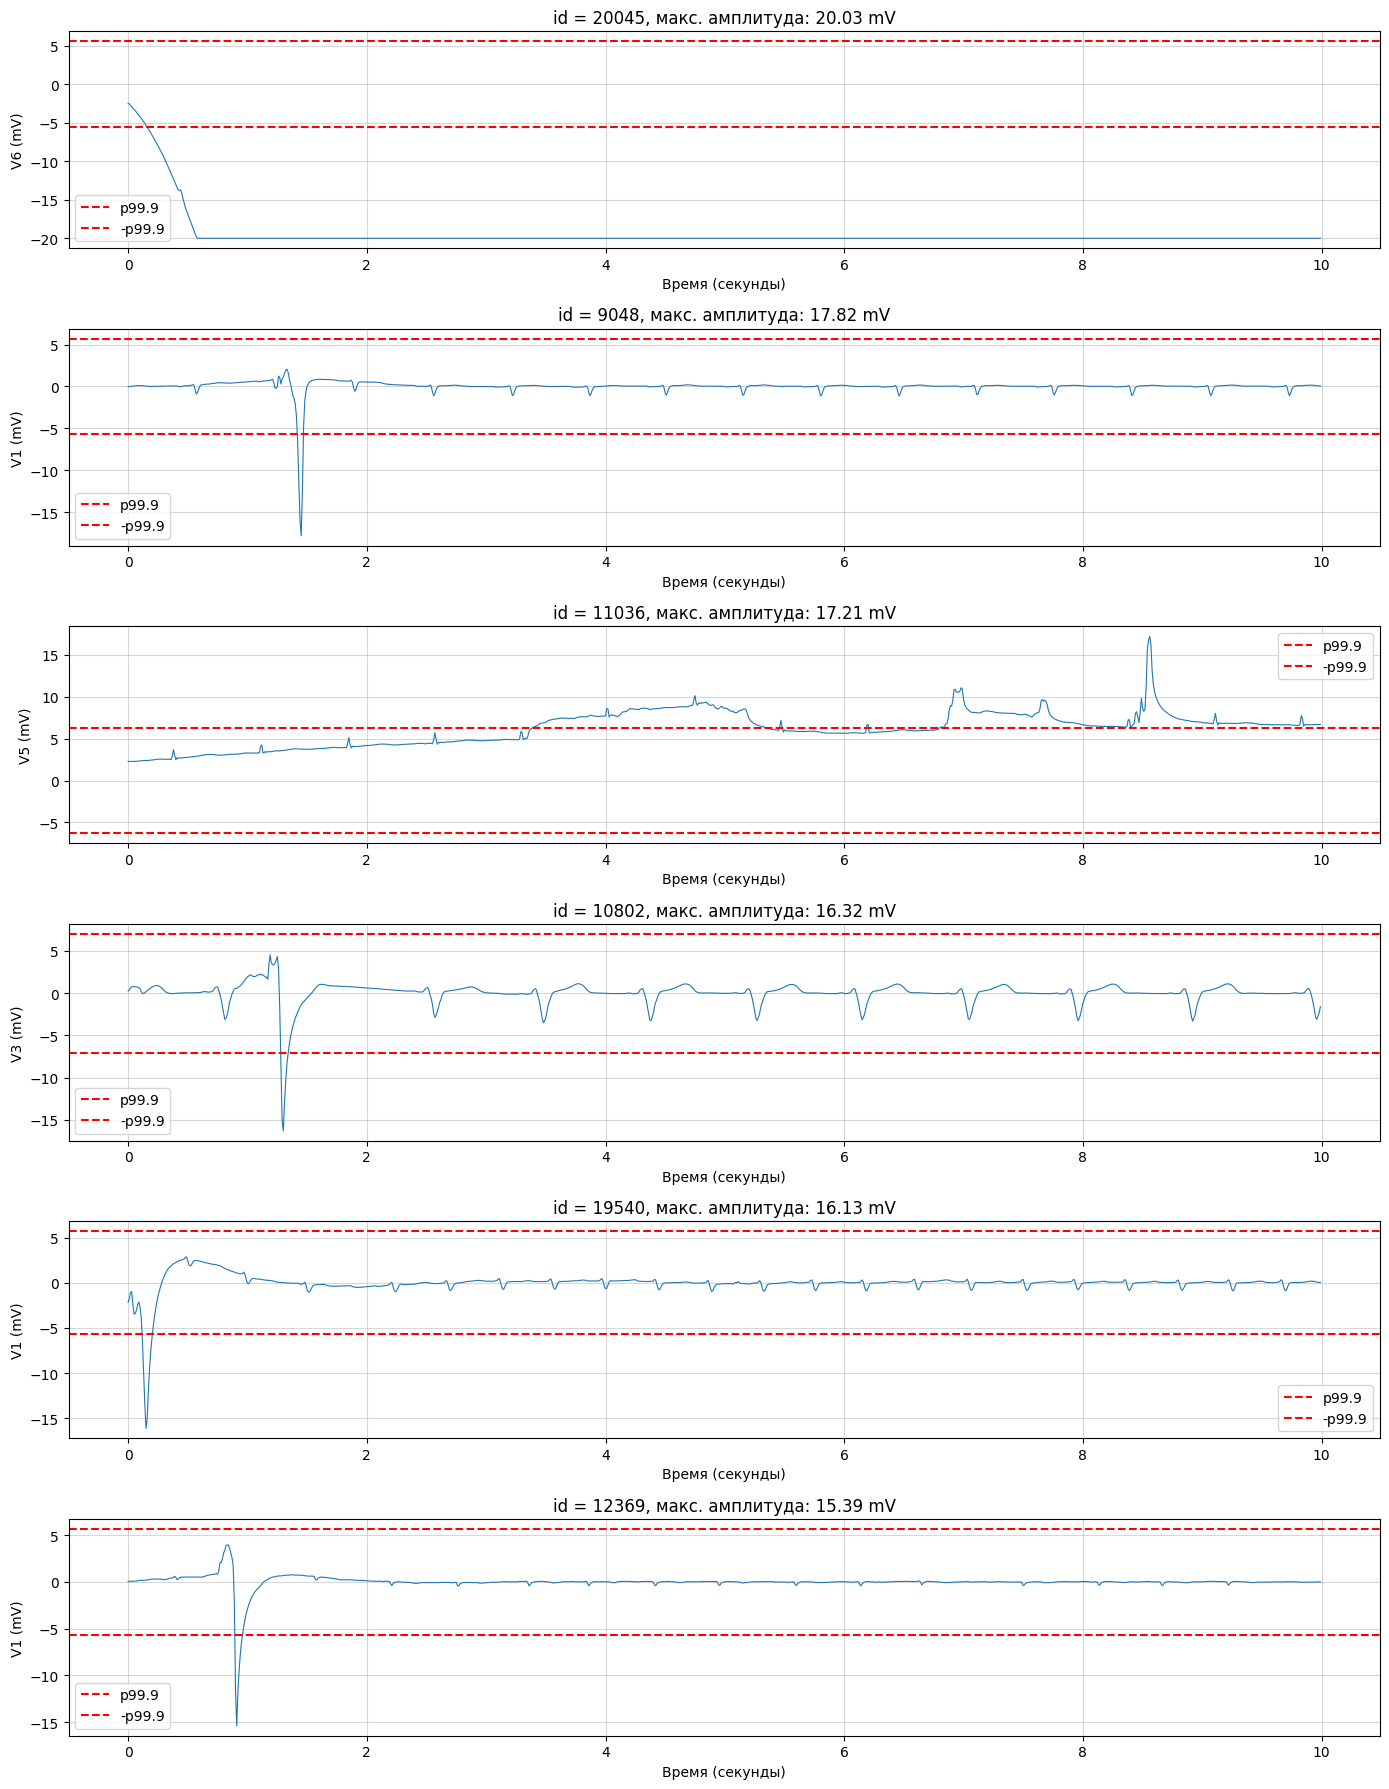

In [37]:
top_cases = extreme_amplitudes.sort_values("max_abs_mV", ascending=False).head(6)

fig, axes = plt.subplots(len(top_cases), 1, figsize=(14, 3*len(top_cases)))

for ax, (_, row) in zip(axes, top_cases.iterrows()):
    ecg_id = row["ecg_id"]
    lead = row["lead"]

    metadata_row = metadata.loc[ecg_id]
    record_path = DATA_DIR / metadata_row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))

    lead_idx = rec.sig_name.index(lead)
    values = rec.p_signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    ax.plot(time, values, linewidth=0.8)

    ax.axhline(row["p99_9_mV"], linestyle="--", color="r", label="p99.9")
    ax.axhline(-row["p99_9_mV"], linestyle="--", color="r", label="-p99.9")

    ax.set_title(f"id = {ecg_id}, макс. амплитуда: {row['max_abs_mV']:.2f} mV")
    ax.set_xlabel("Время (секунды)")
    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

**Вывод:**

В 263 отведениях из 175 записей максимальная абсолютная амплитуда превышает соответствующий 99.9-й перцентиль. Это пока не означает плохие данные. Но надо обратить на них внимание и сравнить с другими проверками.

2 возможных случая (из визуализации):
- резкие отклонения амплитуды
- продолжительное смещение сигнала. Экстремально низкое значение записи 20045 (V6) уже было замечено при поиске постоянных участков.

### Оценка низкочастотной составляющей сигнала

In [38]:
baseline_results = []

for _, row in metadata.iterrows():
    ecg_id = row["ecg_id"]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    baseline = uniform_filter1d(signal, size=201, axis=0) # фильтр скользящего окна

    for lead_idx, lead in enumerate(rec.sig_name):
        values = baseline[:, lead_idx]

        baseline_results.append({
            "ecg_id": ecg_id,
            "lead": lead,
            "baseline_p95_mV": np.percentile(values, 95),
            "baseline_p05_mV": np.percentile(values, 5),
            "baseline_range_mV": np.percentile(values, 95)-np.percentile(values, 5)})

baseline_df = pd.DataFrame(baseline_results)

print("Общая статистика размаха baseline:")
display(baseline_df['baseline_range_mV'].describe())

print("Медианный размах baseline по отведениям:")
display(baseline_df.groupby("lead")['baseline_range_mV'].median().reindex(lead_order))

top_baseline = baseline_df.sort_values("baseline_range_mV", ascending=False).head(10)
print("Отведения с наибольшим размахом baseline:")
display(top_baseline.round(3))

Общая статистика размаха baseline:


,baseline_range_mV
count,261588.000000
mean,0.136438
std,0.230595
min,0.000000
25%,0.036999
50%,0.078008
75%,0.149045
max,10.502996


Медианный размах baseline по отведениям:


,baseline_range_mV
lead,
I,0.058843
II,0.078120
III,0.084827
AVR,0.058620
AVL,0.064463
AVF,0.075803
V1,0.071565
V2,0.090152
V3,0.095049


Отведения с наибольшим размахом baseline:


,ecg_id,lead,baseline_p95_mV,baseline_p05_mV,baseline_range_mV
133175,11124,V6,6.914,-3.589,10.503
198572,16585,V3,3.149,-4.992,8.141
196979,16452,V6,3.121,-4.850,7.971
22727,1906,V6,4.564,-3.224,7.788
209975,17535,V6,4.706,-3.065,7.771
18464,1551,V3,5.222,-2.360,7.582
48417,4054,V4,2.448,-5.020,7.468
56802,4753,V1,9.945,2.618,7.327
56444,4723,V3,4.838,-2.447,7.286
16714,1405,V5,3.595,-3.641,7.236


Есть записи с большими изменениями низкочастотной составляющей

В большинстве отведений размах сглаженной составляющей небольшой. Но есть записи с очень медленными изменениями сигнала.

Посмотрим на 5 отведений с наибольшим размахом между 5-м и 95-м перцентилями сглаженного сигнала.

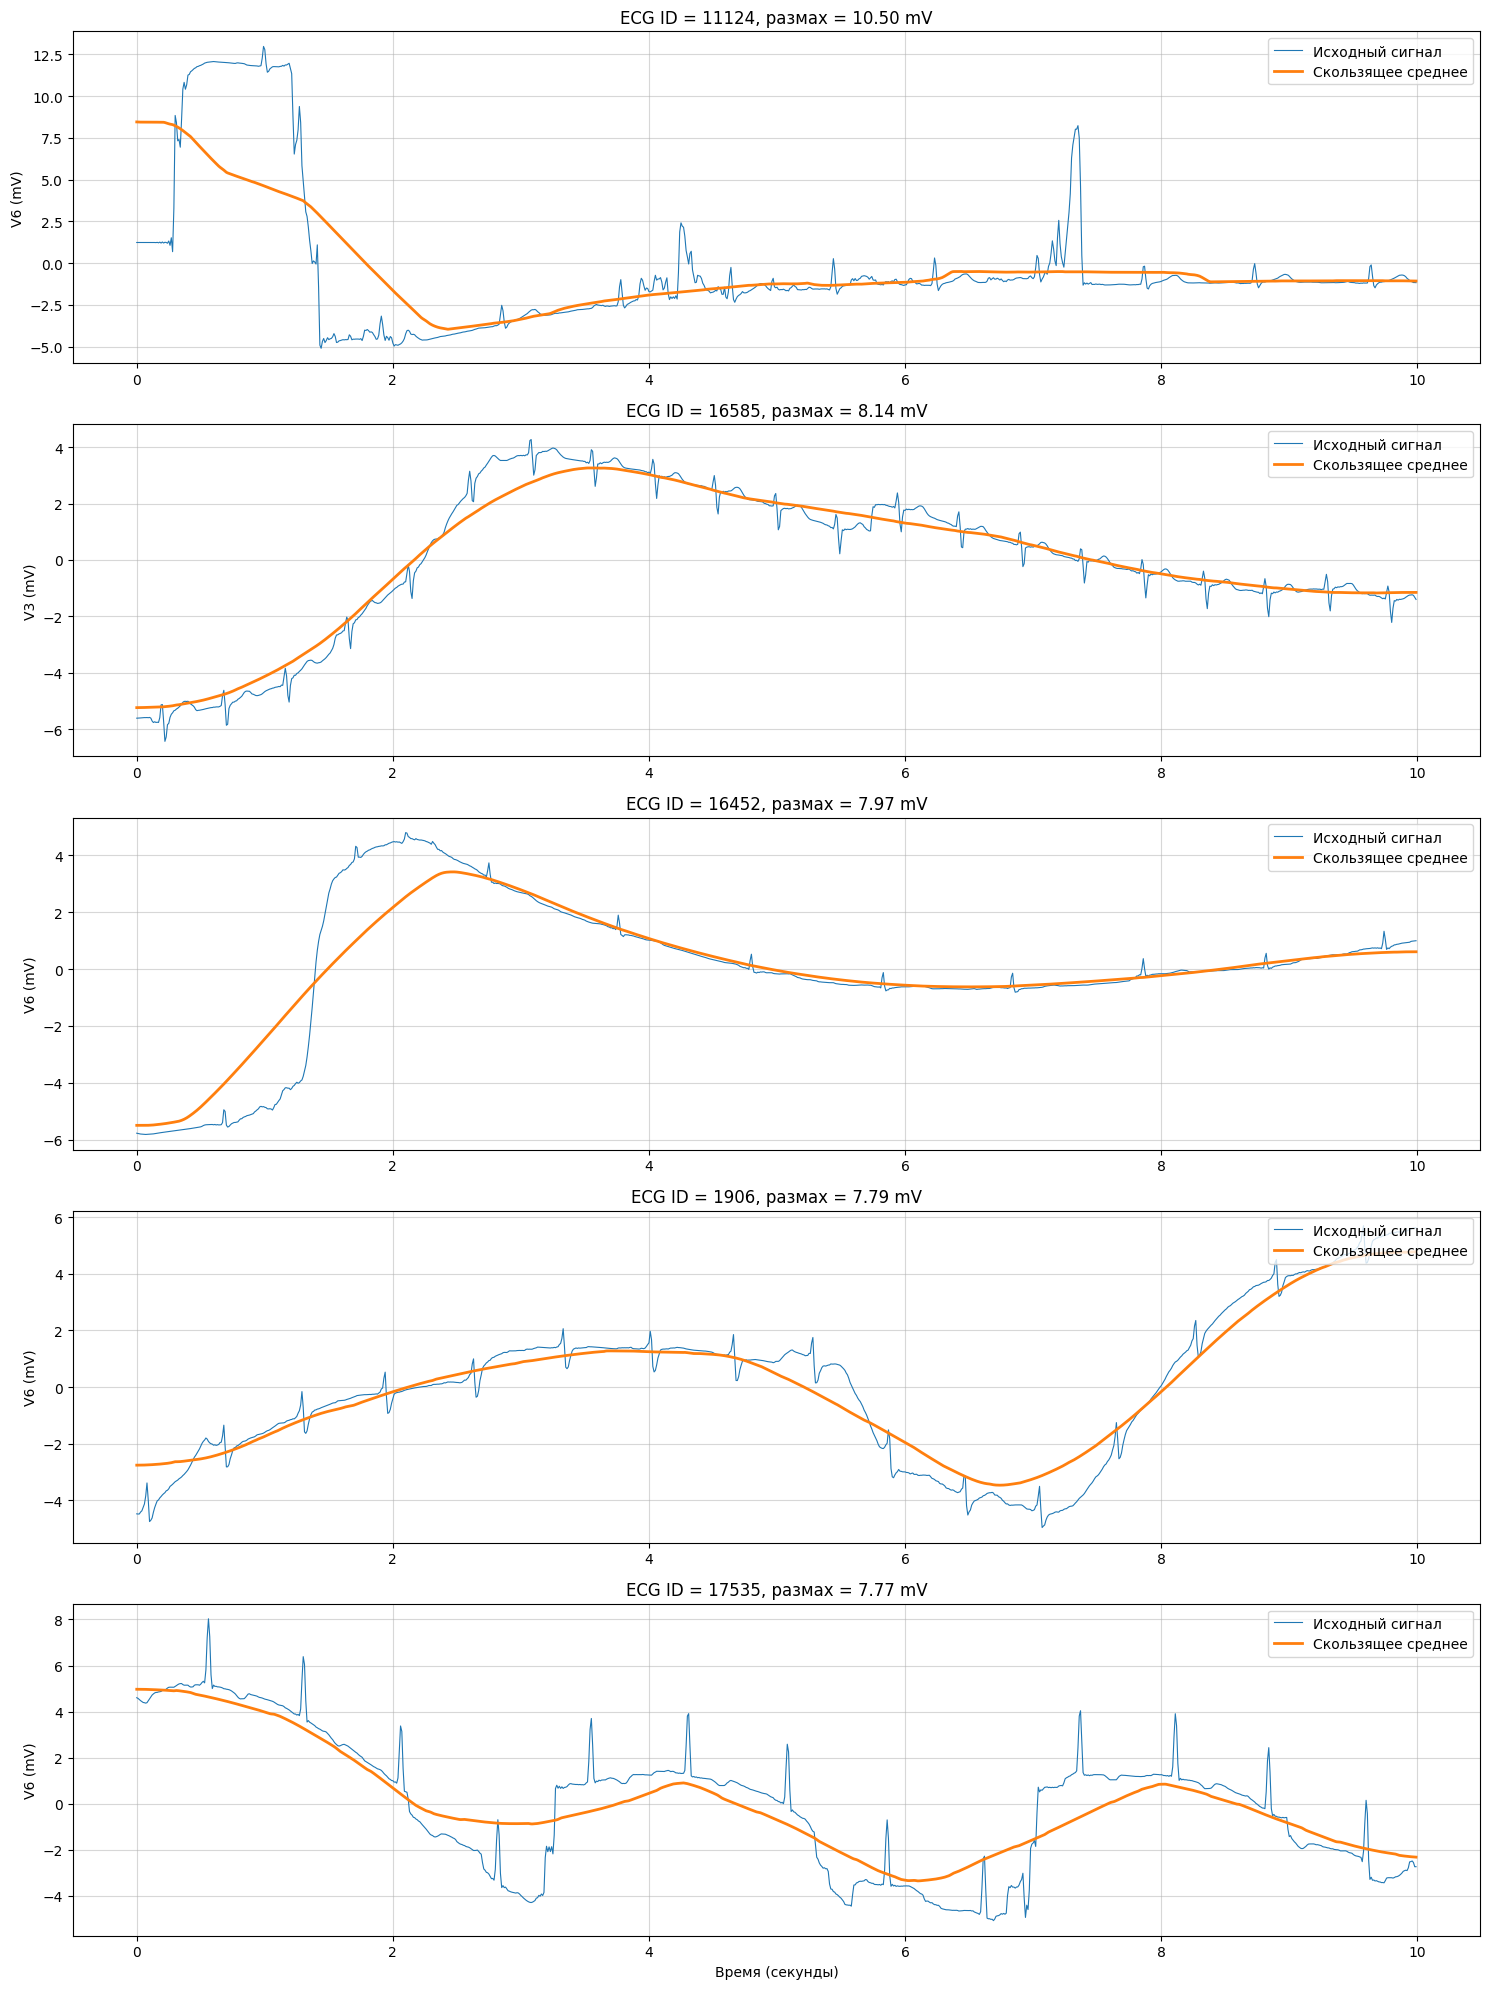

In [39]:
top_baseline = baseline_df.sort_values("baseline_range_mV", ascending=False).head(5)

fig, axes = plt.subplots(len(top_baseline), 1, figsize=(15, 4 * len(top_baseline)))

for ax, (_, item) in zip(axes, top_baseline.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    lead_idx = rec.sig_name.index(lead)
    values = signal[:, lead_idx]
    time = np.arange(len(values))/rec.fs

    baseline = uniform_filter1d(values, size=201)

    ax.plot( time, values, linewidth=0.8, label="Исходный сигнал")
    ax.plot(time, baseline, linewidth=2, label="Скользящее среднее")
    ax.set_title(f"ECG ID = {ecg_id}, размах = {item['baseline_range_mV']:.2f} mV")

    ax.set_ylabel(f"{lead} (mV)")
    ax.grid(alpha=0.5)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

Для приближённой оценки медленных изменений сигнала использовано скользящее среднее с окном в 201 отсчёт (~2 секунды).

Медианный размах по всем отведениям - 0.078 mV. Медианные значения отличаются между отведениями: от 0.059 mV в AVR до 0.095 mV в V3. В большинстве отведений медленные изменения относительно небольшие (как и ожидается).
Но есть отдельные записи с выраженными изменениями уровня сигнала (например максимальный размах - 10.50 mV в записи 11124, отведение V6).

*Примечание:* большой размах не гарантирует наличие шума или плохое качество записи.

На отдельных графиках видны:
- резкие переходы
- плавные смещения
- продолжительные колебания сглаженной составляющей

-> низкочастотная часть сигналов неоднородна -> при подготовке данных нужно учитывать наличие таких изменений и оценить, как их удаление повлияет на данные.

*Примечание:* скользящее среднее не может отделить технический дрейф от других медленных изменений сигнала -> говорить о плохом качестве данных нельзя

### Оценка быстрых составляющих сигнала
*Эта часть практических результатов особенно не дает, но я оставила. Суть - при удалении шума на высоких частотах важно убедиться, что это именно шум, а не характерные для ЭКГ-сигнала пики*

In [40]:
highfreq_results = []

for ecg_id, row in metadata.iterrows():
    record_path = DATA_DIR / row["filename_lr"]
    rec = wfdb.rdrecord(str(record_path))
    signal = rec.p_signal

    smooth_signal = uniform_filter1d(signal, size=5, axis=0)
    highfreq_signal = signal - smooth_signal

    # RMS для каждого отведения
    for lead_idx, lead in enumerate(rec.sig_name):
        values = highfreq_signal[:, lead_idx]

        highfreq_rms = np.sqrt(np.mean(values ** 2))

        highfreq_results.append({
            "ecg_id": int(ecg_id),
            "lead": lead,
            "highfreq_rms_mV": highfreq_rms})

highfreq_df = pd.DataFrame(highfreq_results)

print("Распределение RMS для высокочастотных колебаний:")
display(highfreq_df["highfreq_rms_mV"].describe().round(4))

print("10 отведений с наибольшим RMS:")
display(highfreq_df.sort_values("highfreq_rms_mV", ascending=False).head(10))

Распределение RMS для высокочастотных колебаний:


,highfreq_rms_mV
count,261588.0000
mean,0.0814
std,0.0499
min,0.0000
25%,0.0463
50%,0.0692
75%,0.1037
max,0.6829


10 отведений с наибольшим RMS:


,ecg_id,lead,highfreq_rms_mV
201765,16851,V4,0.682902
202665,16926,V4,0.651676
199917,16697,V4,0.630027
79245,6624,V4,0.596788
138249,11547,V4,0.586600
23491,1970,V2,0.584770
106678,8913,V5,0.583823
23492,1970,V3,0.578121
106677,8913,V4,0.571046
211653,17675,V4,0.553695


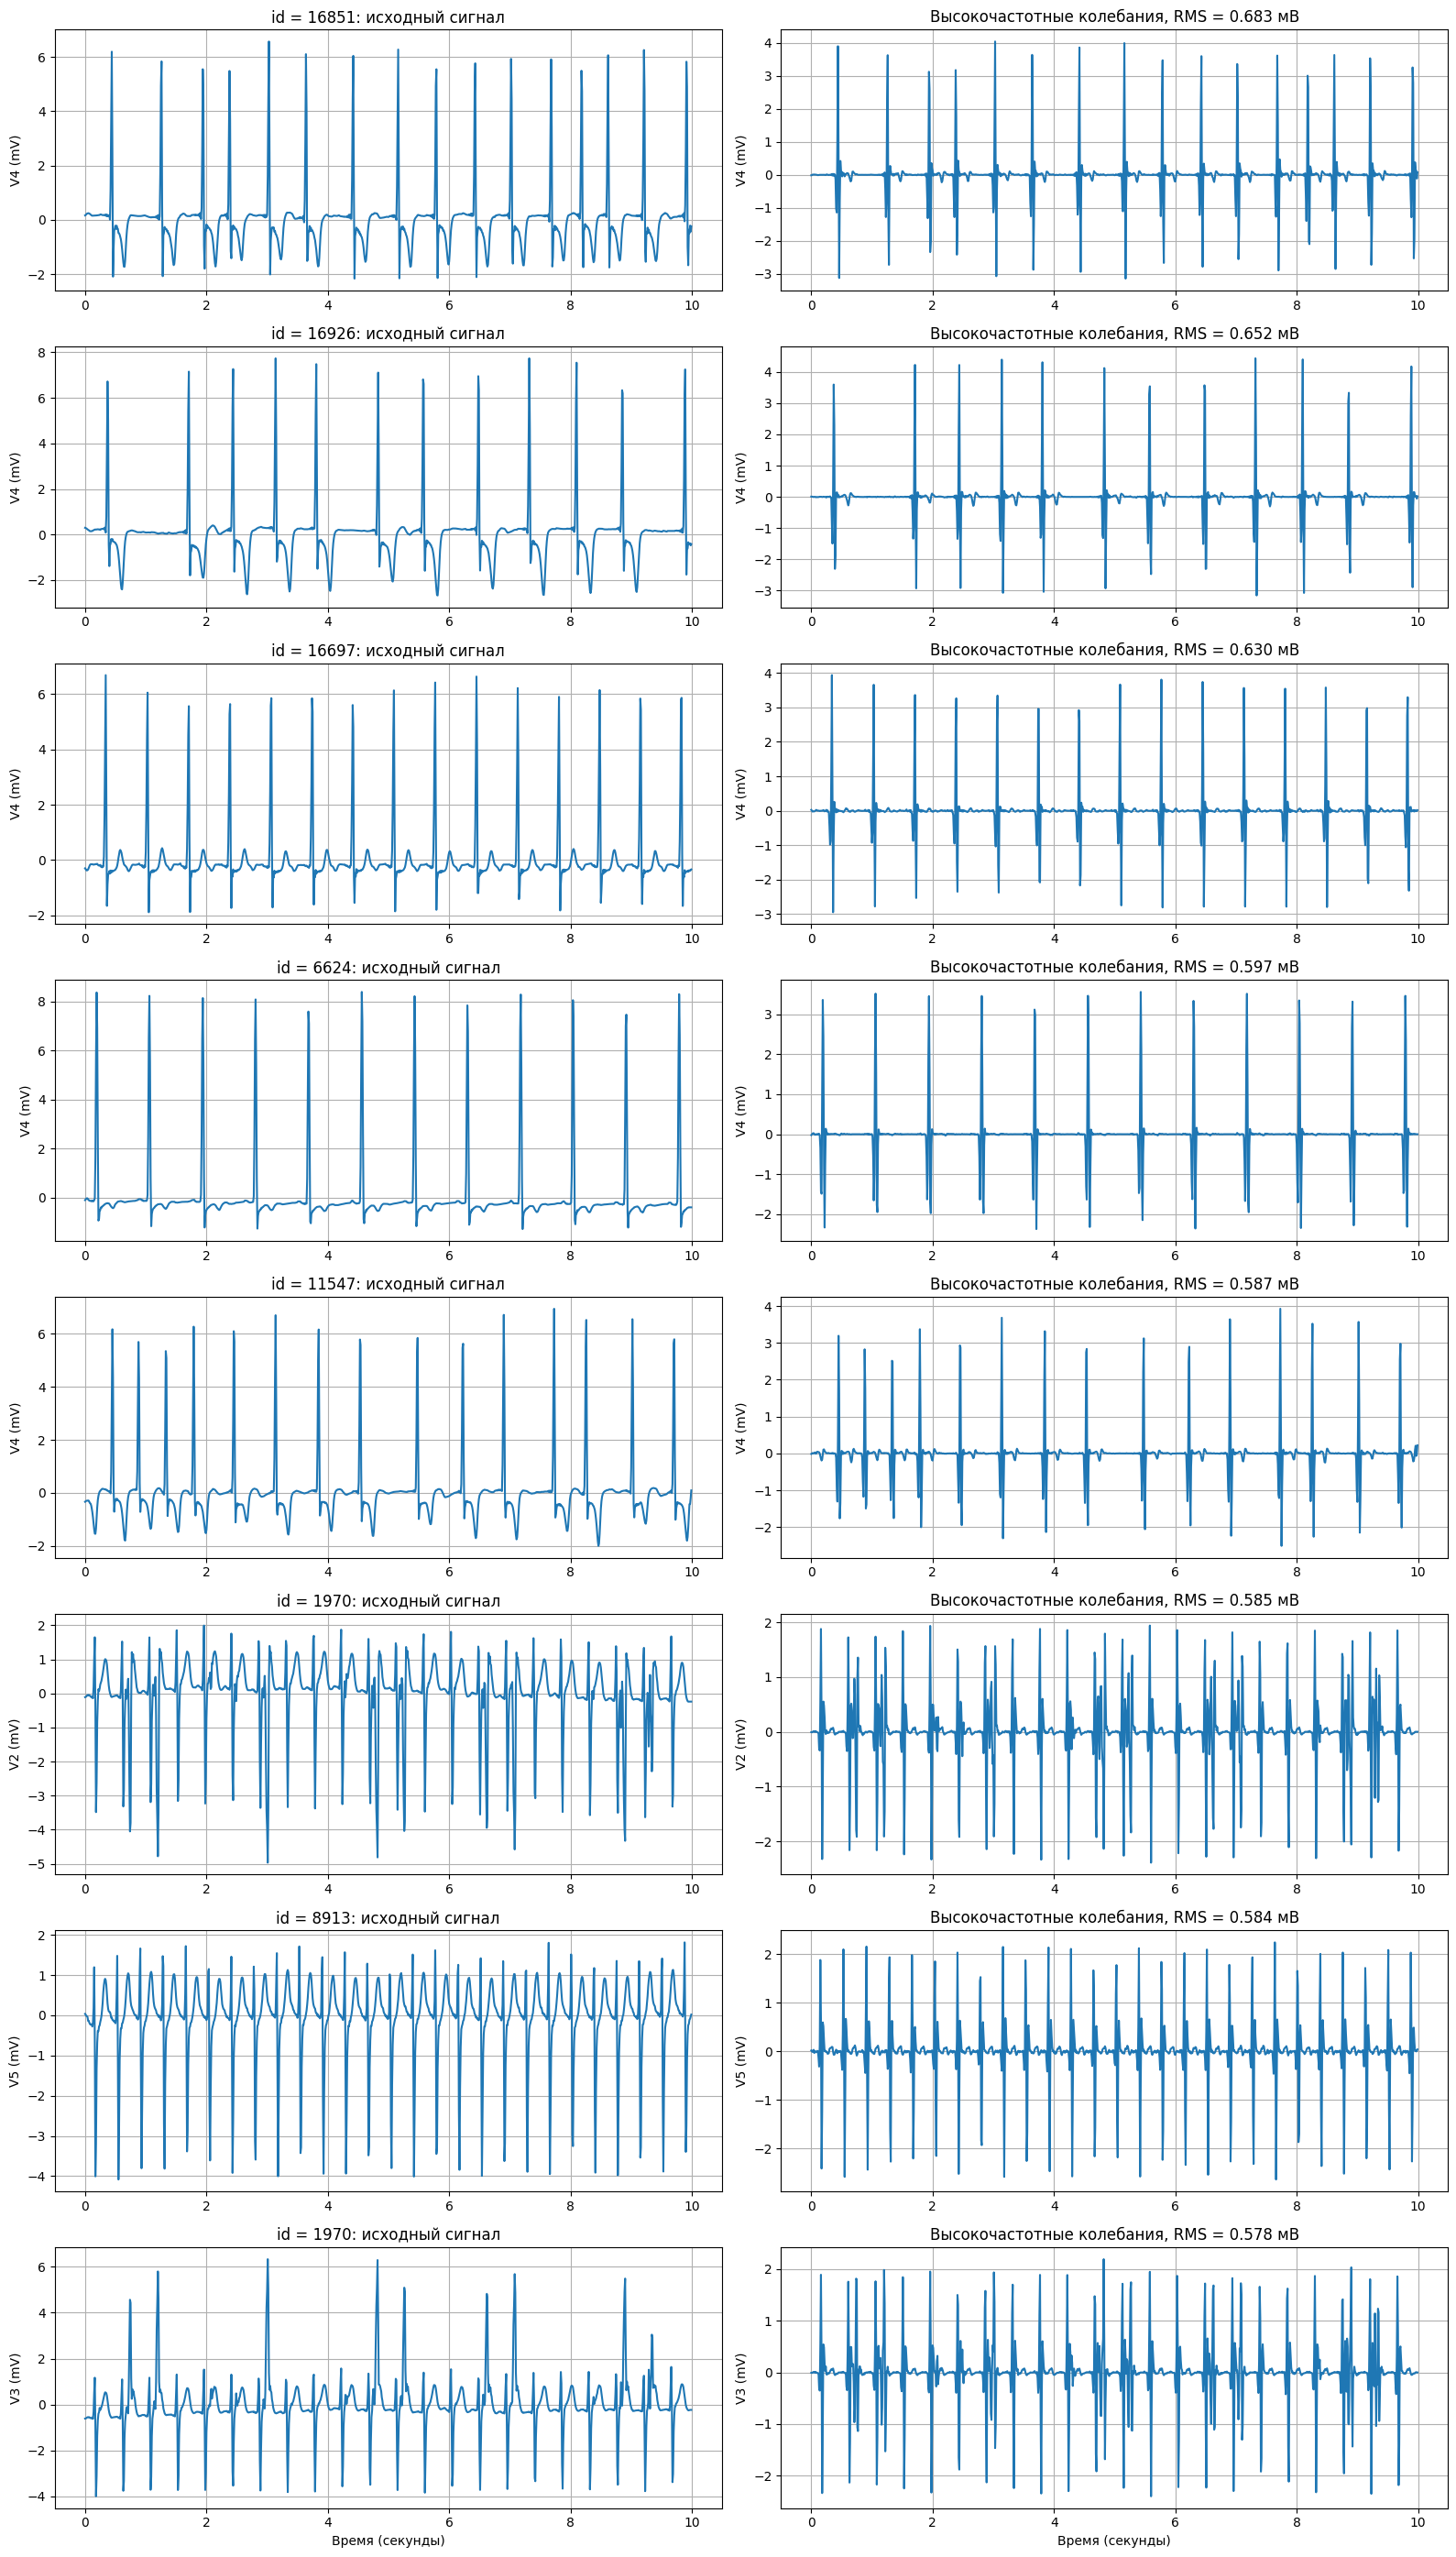

In [41]:
top_highfreq = highfreq_df.sort_values("highfreq_rms_mV", ascending=False).head(8)

fig, axes = plt.subplots(len(top_highfreq), 2, figsize=(16, 3.5 * len(top_highfreq)))

for i, (_, item) in enumerate(top_highfreq.iterrows()):
    ecg_id = int(item["ecg_id"])
    lead = item["lead"]

    row = metadata.loc[ecg_id]
    record_path = DATA_DIR / row["filename_lr"]

    rec = wfdb.rdrecord(str(record_path))
    lead_idx = rec.sig_name.index(lead)
    values = rec.p_signal[:, lead_idx]

    time = np.arange(len(values))/rec.fs

    smooth_signal = uniform_filter1d(values, size=5)
    highfreq_signal = values - smooth_signal

    axes[i, 0].plot(time, values)
    axes[i, 0].set_title(f"id = {ecg_id}: исходный сигнал")
    axes[i, 0].set_ylabel(f"{lead} (mV)")
    axes[i, 0].grid(True)

    axes[i, 1].plot(time, highfreq_signal)
    axes[i, 1].set_title(f"Высокочастотные колебания, RMS = {item['highfreq_rms_mV']:.3f} мВ")
    axes[i, 1].set_ylabel(f"{lead} (mV)")
    axes[i, 1].grid(True)

axes[-1, 0].set_xlabel("Время (секунды)")
axes[-1, 1].set_xlabel("Время (секунды)")

plt.tight_layout()
plt.show()

Для оценки быстрых изменений сигнала использовано скользящее среднее с окном 5 отсчётов. Из исходного сигнала вычиталась сглаженная составляющая. RMS рассчитывалось для полученной разности отдельно для каждого отведения.

На графиках с наибольшим RMS быстрые пики повторяются и совпадают по времени с резкими скачками исходного сигнала -> данный метод также выделяет изменения самой формы ЭКГ, а не только возможный шум

### Итог по анализу ЭКГ-сигналов
Все 21799 записей имеют одинаковый формат: 10 секунд, 12 отведений, частота дискретизации 100 Гц, единицы измерения mV -> единый формат входных данных для дальнейшей работы модели.

В данных нет NaN и Inf.

Особенности, которые важно учитывать при подготовке сигналов:

- в 4 записях найдены 7 отведений с непрерывными постоянными участками длительностью не менее 0,5 секунды. В некоторых отведениях постоянный участок занимает всю запись или большую ее часть.
- распределение амплитуд различается между отведениями. В 175 записях найдены отведения, максимальная абсолютная амплитуда которых больше соответствующего 99.9-й перцентиля.
- В большинстве отведений размах медленной составляющей относительно небольшой, но есть записи с заметными изменениями сигнала (например, 11124 (V6), 16585 (V3), 16452 (V6)).
- анализ быстрых составляющих показал не только шуум, но и пики, характерные для ЭКГ.
- визуальное сравнение примеров из разных классов показало, что сигналы могут заметно отличаться по форме и амплитуде внутри одного класса и между отведениями разных классов -> отдельная запись не может отображать тенденцию для всего класса

**Что следует учесть при подготовке входных данных для модели:**
1. **Формат входных данных.** Сохранять единый формат записей: одинаковое число отсчётов, все 12 отведений и частоту дискретизации.
2. **Контроль качества каналов.** Предусмотреть проверку постоянных участков, т.к. отдельные отведения могут содержать длительные участки без изменений. Эти данные следует дополнительно проверять, а не сразу удалять запись.
3. **Контроль амплитуд.** Учитывать различия амплитудных распределений между отведениями. При выборе способа масштабирования и нормализации проверить, не приведет ли он к потере значимых амплитудных данных.
4. **Обработка медленных изменений.** Не применять удаление низкочастотной составляющей без проверки того, как это изменит исходную форму сигнала.
5. **Сохранение данных.** При обучении лучше использовать все доступные записи и все 12 отведений, а не на несколько отобранных примеров.

## 4. Baseline-модель для PTB-XL

**Второй чекпоинт · DL-трек**

В этом ноутбуке я обучаю простую модель, которая по сигналу ЭКГ предсказывает пять диагностических категорий: `NORM`, `MI`, `STTC`, `CD` и `HYP`.

На этом этапе важно не получить максимально возможное качество, а построить **понятный baseline**, с которым затем можно сравнивать более сложные модели. Для этого использую логистическую регрессию и простые характеристики 12 отведений ЭКГ.

**Данные:** [PTB-XL, версия 1.0.3](https://physionet.org/content/ptb-xl/1.0.3/). Подготовка по логике `labels.py` и EDA (Ульяны)

Часть Марии Павленко. Обучение без аугментаций.

### 4.1. Подготовка файлов

Нужны **три части датасета**:

- `ptbxl_database.csv` - метаданные ЭКГ, включая пути к сигналам и исходные SCP-коды;
- `scp_statements.csv` - справочник для перевода SCP-кодов в пять диагностических классов;
- папка `records100` - сами сигналы ЭКГ с частотой 100 Гц. Каждая запись состоит из пары `.hea` и `.dat`.

 `records500` нам сейчас пока не нужны.


In [42]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

### 4.2. Загружаем метаданные и готовим метки

Здесь используем общую функцию `prepare_labels` из `labels.py`. В исходном `scp_codes` хранится словарь диагностических кодов. По справочнику `scp_statements.csv` мы определяем, к каким крупным категориям относится запись.

**Важный момент:** одна ЭКГ может иметь сразу несколько диагнозов. Поэтому это **multi-label классификация**: для каждого из пяти классов модель отдельно решает, есть он или нет.

In [43]:
data_path = PTBXL_DIR
labels_df = prepare_labels(database_path, statements_path)
df = pd.read_csv(database_path)
df = df.merge(labels_df[['ecg_id', *CLASSES]], on='ecg_id', validate='one_to_one')
scp = pd.read_csv(statements_path, index_col=0)

print('Размер базы:', df.shape)
print('Размер справочника:', scp.shape)
df[['ecg_id', 'patient_id', 'strat_fold', 'filename_lr', 'scp_codes']].head()

Размер базы: (21799, 33)
Размер справочника: (71, 12)


,ecg_id,patient_id,strat_fold,filename_lr,scp_codes
0,1,15709.0,3,records100/00000/00001_lr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243.0,2,records100/00000/00002_lr,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372.0,5,records100/00000/00003_lr,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,3,records100/00000/00004_lr,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448.0,4,records100/00000/00005_lr,"{'NORM': 100.0, 'SR': 0.0}"


In [44]:
df[['ecg_id'] + CLASSES].head()

,ecg_id,NORM,MI,STTC,CD,HYP
0,1,1,0,0,0,0
1,2,1,0,0,0,0
2,3,1,0,0,0,0
3,4,1,0,0,0,0
4,5,1,0,0,0,0


In [45]:
print('Распределение классов:')
print(df[CLASSES].sum().sort_values(ascending=False))

print()
print('Количество диагностических меток на одну ЭКГ:')
print(df[CLASSES].sum(axis=1).value_counts().sort_index())

Распределение классов:
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64

Количество диагностических меток на одну ЭКГ:
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64


### Что делаем с записями без целевых меток?

Некоторые ЭКГ не получают ни одной метки из выбранных пяти классов. Это не обязательно «здоровые» записи: в исходной разметке могут быть, например, только ритмические или другие недиагностические коды.

Для первичного baseline я **исключаю записи без выбранных диагностических меток**, чтобы не считать их заведомо отрицательными примерами всех пяти диагнозов. Это решение применяю одинаково к обучению, валидации и тесту. В дальнейшем его можно проверить отдельно.

In [46]:
df_model = df[df[CLASSES].sum(axis=1) > 0].copy()

print('Всего записей:', len(df))
print('Оставили для baseline:', len(df_model))
print('Исключили:', len(df) - len(df_model))

Всего записей: 21799
Оставили для baseline: 21388
Исключили: 411


### 4.3. Разделяем данные на train, validation и test

В PTB-XL уже есть готовый столбец `strat_fold`. Как говорилось в EDA, авторы рекомендуют использовать **фолды 1-8 для обучения, 9 для валидации и 10 для тестирования**. Это важно ещё и потому, что все записи одного пациента находятся в одном фолде: так модель не увидит ЭКГ одного и того же человека одновременно при обучении и тестировании.


In [47]:
train_df = df_model[df_model['strat_fold'] <= 8].copy()
val_df = df_model[df_model['strat_fold'] == 9].copy()
test_df = df_model[df_model['strat_fold'] == 10].copy()

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))

Train: 17084
Validation: 2146
Test: 2158


### 4.4. Считываем ЭКГ и получаем признаки

До этого у нас были только **метки** диагнозов. Теперь начинаем работать с самим сигналом.

В `records100` каждая запись - это 10 секунд ЭКГ, 12 отведений и частота 100 Гц. То есть, обычно мы получаем массив размером **1000 × 12**. Библиотека `wfdb` умеет прочитать его по пути из столбца `filename_lr`.

Вот так это выглядит для одной записи

In [48]:
first_record = data_path / df_model['filename_lr'].iloc[0]
signal, info = wfdb.rdsamp(str(first_record))

print('Размер сигнала:', signal.shape)
print('Частота:', info['fs'], 'Гц')
print('Отведения:', info['sig_name'])
print('Единицы измерения:', info['units'])

Размер сигнала: (1000, 12)
Частота: 100 Гц
Отведения: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Единицы измерения: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']


### Какие признаки берем

Чтобы не обучать пока сложную модель на всех 12 000 значениях сигнала, для **каждого отведения** рассчитаем четыре простые характеристики:

- `mean` - среднее значение сигнала;
- `std` - стандартное отклонение, то есть насколько сильно меняется амплитуда;
- `range` - разница между максимальным и минимальным значением;
- `diff` - средняя абсолютная разница между соседними точками; грубая характеристика того, как быстро изменяется сигнал.

Итого **12 × 4 = 48 признаков** на одну ЭКГ. Это заведомо упрощённое описание: форма комплексов QRS и зубцов P/T, а также временные интервалы здесь напрямую не учитываются. Но для первого интерпретируемого baseline этого достаточно.

**Не используем возраст, пол и остальные метаданные** тк наша основная задача сейчас распознавать диагностические классы **по ЭКГ**, поэтому на первом этапе берём признаки только из сигналов. Метки `scp_codes` и готовые диагнозы во вход модели не попадают.

### Рассчитываем характеристики для всех записей

Проходим по файлам `records100`, считываем сигнал и считаем статистики для 12 отведений.


In [49]:
features_path = ROOT / 'data/processed/ecg_features_100hz.csv'
features_path.parent.mkdir(parents=True, exist_ok=True)

if features_path.exists():
    features_df = pd.read_csv(features_path)
else:
    feature_rows = []

    for row in tqdm(df_model.itertuples(), total=len(df_model)):
        signal, info = wfdb.rdsamp(str(data_path / row.filename_lr))
        features = {'ecg_id': row.ecg_id}

        for i, lead in enumerate(info['sig_name']):
            values = signal[:, i]
            features[f'{lead}_mean'] = np.mean(values)
            features[f'{lead}_std'] = np.std(values)
            features[f'{lead}_range'] = np.ptp(values)
            features[f'{lead}_diff'] = np.mean(np.abs(np.diff(values)))

        feature_rows.append(features)

    features_df = pd.DataFrame(feature_rows)
    features_df.to_csv(features_path, index=False)

expected_feature_cols = [
    f'{lead}_{stat}'
    for lead in ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    for stat in ['mean', 'std', 'range', 'diff']
]
assert features_df.columns.tolist() == ['ecg_id', *expected_feature_cols], 'Неверные столбцы кэша признаков. Удалите кэш и запустите ячейку заново.'
assert features_df['ecg_id'].is_unique and set(features_df['ecg_id']) == set(df_model['ecg_id']), 'Кэш признаков не соответствует набору ЭКГ. Удалите кэш и запустите ячейку заново.'
assert all(pd.api.types.is_numeric_dtype(features_df[col]) for col in expected_feature_cols) and np.isfinite(features_df[expected_feature_cols].to_numpy()).all(), 'Кэш признаков содержит нечисловые значения, NaN или inf. Удалите кэш и запустите ячейку заново.'

print('Размер таблицы признаков:', features_df.shape)
features_df.head()

  0%|          | 0/21388 [00:00<?, ?it/s]

Размер таблицы признаков: (21388, 49)


,ecg_id,I_mean,I_std,I_range,I_diff,II_mean,II_std,II_range,II_diff,III_mean,...,V4_range,V4_diff,V5_mean,V5_std,V5_range,V5_diff,V6_mean,V6_std,V6_range,V6_diff
0,1,0.001508,0.109022,0.901,0.033637,0.000723,0.083223,0.575,0.025407,-0.000778,...,0.914,0.026614,-0.000557,0.089204,0.627,0.021435,0.000832,0.101939,0.757,0.018738
1,2,-0.002181,0.133428,1.013,0.027497,-0.000165,0.249745,1.948,0.037291,0.002037,...,3.253,0.060535,0.006375,0.228674,2.331,0.045091,0.003389,0.186626,1.598,0.033853
2,3,-0.002770,0.121200,0.991,0.035177,0.005145,0.144389,1.003,0.028187,0.007927,...,1.445,0.034444,0.005362,0.110647,1.026,0.025862,0.004239,0.100842,0.833,0.020466
3,4,-0.003264,0.137803,1.079,0.040861,0.003502,0.438161,3.036,0.070125,0.006750,...,5.189,0.142956,-0.007380,0.394695,3.490,0.098566,-0.004061,0.297912,2.435,0.069600
4,5,-0.003769,0.082706,0.707,0.025714,-0.003054,0.236781,1.912,0.045273,0.000704,...,2.026,0.051336,0.000208,0.210904,1.680,0.043241,-0.000053,0.180209,1.418,0.037127


### Проверим получившуюся таблицу

Теперь **одна строка - одна ЭКГ**, а столбцы - это её характеристики. Проверяем, нет ли пропусков, и соединяем таблицу с метками по `ecg_id`.

In [50]:
print('Пропусков в таблице признаков:', features_df.isna().sum().sum())
print('Полных дублей по ecg_id:', features_df['ecg_id'].duplicated().sum())

data = df_model.merge(features_df, on='ecg_id', how='inner', validate='one_to_one')

feature_cols = features_df.columns.drop('ecg_id').tolist()
print('Число признаков:', len(feature_cols))

Пропусков в таблице признаков: 0
Полных дублей по ecg_id: 0
Число признаков: 48


### 4.5. Обучаем логистическую регрессию

Так как у нас многометочная классификация, то для каждого из пяти классов будем обучать отдельную бинарную модель - такой подход называется **One-vs-Rest**. Он подходит для нашей задачи, поскольку одна ЭКГ может одновременно иметь несколько меток.

Перед обучением:

- заменяем пропущенные числовые значения медианой, рассчитанной **только на train**;
- стандартизируем признаки, чтобы их масштаб не влиял на величину коэффициентов;
- учитываем дисбаланс с помощью `class_weight='balanced'`.

Эти преобразования объединены с моделью в `Pipeline`, поэтому данные из validation и test не влияют на параметры предобработки.

In [51]:
train = data[data['strat_fold'] <= 8]
val = data[data['strat_fold'] == 9]
test = data[data['strat_fold'] == 10]

X_train, y_train = train[feature_cols], train[CLASSES]
X_val, y_val = val[feature_cols], val[CLASSES]
X_test, y_test = test[feature_cols], test[CLASSES]

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_val:', X_val.shape, '| y_val:', y_val.shape)
print('X_test:', X_test.shape, '| y_test:', y_test.shape)

X_train: (17084, 48) | y_train: (17084, 5)
X_val: (2146, 48) | y_val: (2146, 5)
X_test: (2158, 48) | y_test: (2158, 5)


In [52]:
model = OneVsRestClassifier(
    Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
    ])
)

model.fit(X_train, y_train)

OneVsRestClassifier(estimator=Pipeline(steps=[('imputer',
                                               SimpleImputer(strategy='median')),
                                              ('scaler', StandardScaler()),
                                              ('lr',
                                               LogisticRegression(class_weight='balanced',
                                                                  max_iter=2000,
                                                                  random_state=42))]))

### 4.6. Смотрим качество модели

Сначала получаем вероятности каждого класса, затем для простоты считаем метку положительной при вероятности от `0.5`. Порог пока **не подбираем** (для простоты baseline).

Оцениваем F1 и:

- **ROC-AUC** - насколько хорошо модель разделяет положительные и отрицательные примеры независимо от порога;
- **Average Precision (AP)** - качество ранжирования положительных примеров; особенно полезно для редких классов;
- **Precision** - какая доля положительных предсказаний действительно правильная;
- **Recall** - какую долю реальных положительных записей модель нашла.

В таблице также будет доля класса (`prevalence`). Для AP это полезный ориентир: у случайного ранжирования AP примерно равен частоте класса. Accuracy здесь менее информативна из-за дисбаланса.

In [53]:
val_proba = model.predict_proba(X_val)
test_proba = model.predict_proba(X_test)

print('Вероятности для первых трёх ЭКГ:')
display(pd.DataFrame(test_proba[:3], columns=CLASSES).round(3))

Вероятности для первых трёх ЭКГ:


,NORM,MI,STTC,CD,HYP
0,0.563,0.451,0.522,0.228,0.171
1,0.570,0.460,0.336,0.427,0.094
2,0.288,0.674,0.436,0.410,0.472


In [54]:
def calculate_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    results = []

    for i, class_name in enumerate(CLASSES):
        true_labels = y_true[class_name]
        pred_labels = predictions[:, i]

        results.append({
            'class': class_name,
            'prevalence': true_labels.mean(),
            'ROC-AUC': roc_auc_score(true_labels, probabilities[:, i]),
            'AP': average_precision_score(true_labels, probabilities[:, i]),
            'precision': precision_score(true_labels, pred_labels, zero_division=0),
            'recall': recall_score(true_labels, pred_labels, zero_division=0),
            'F1': f1_score(true_labels, pred_labels, zero_division=0)
        })

    return pd.DataFrame(results).set_index('class')

In [55]:
val_metrics = calculate_metrics(y_val, val_proba)
test_metrics = calculate_metrics(y_test, test_proba)

print('VALIDATION')
display(val_metrics.round(3))

print('TEST')
display(test_metrics.round(3))

VALIDATION


,prevalence,ROC-AUC,AP,precision,recall,F1
class,,,,,,
NORM,0.445,0.800,0.710,0.649,0.812,0.721
MI,0.252,0.756,0.477,0.446,0.719,0.551
STTC,0.246,0.724,0.450,0.420,0.593,0.491
CD,0.231,0.790,0.587,0.490,0.665,0.564
HYP,0.125,0.857,0.473,0.380,0.743,0.503


TEST


,prevalence,ROC-AUC,AP,precision,recall,F1
class,,,,,,
NORM,0.446,0.788,0.691,0.646,0.789,0.710
MI,0.255,0.743,0.494,0.421,0.671,0.518
STTC,0.241,0.708,0.442,0.405,0.591,0.481
CD,0.230,0.757,0.561,0.450,0.611,0.518
HYP,0.121,0.838,0.459,0.345,0.706,0.463


In [56]:
print('Средние значения на test:')
print('ROC-AUC (macro):', round(test_metrics['ROC-AUC'].mean(), 3))
print('AP (macro):', round(test_metrics['AP'].mean(), 3))
print('F1 (macro):', round(test_metrics['F1'].mean(), 3))

Средние значения на test:
ROC-AUC (macro): 0.767
AP (macro): 0.53
F1 (macro): 0.538


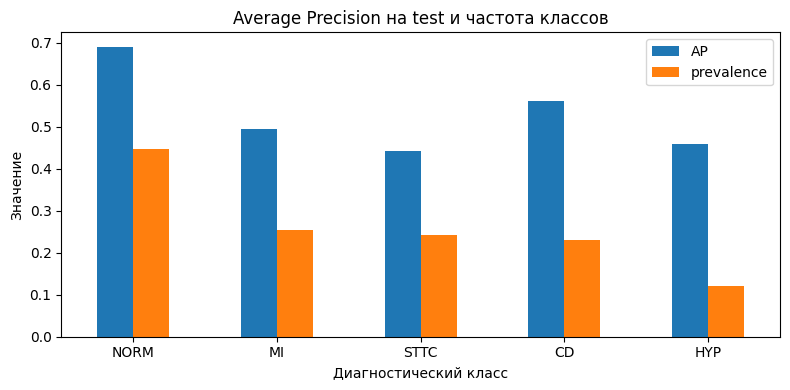

In [57]:
# Сравним качество AP с частотой каждого класса в тестовой выборке
ax = test_metrics[['AP', 'prevalence']].plot(kind='bar', figsize=(8, 4))
ax.set_title('Average Precision на test и частота классов')
ax.set_ylabel('Значение')
ax.set_xlabel('Диагностический класс')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Наблюдения по качеству


На тестовой выборке модель показала **ROC-AUC macro = 0.767, AP macro = 0.530 и F1 macro = 0.538**. Для первого baseline, построенного всего на 48 статистических признаках ЭКГ, модель уже способна различать диагностические категории, хотя качество заметно отличается в зависимости от класса.

Лучше всего по F1 модель распознаёт **NORM** (0.710). Для этого класса также получено самое высокое значение AP (0.691). При этом максимальный ROC-AUC оказался у **HYP** (0.838), несмотря на то что этот класс встречается реже остальных - примерно в 12% тестовых записей.

Интересно, что высокий ROC-AUC для HYP не означает столь же хорошего качества бинарных предсказаний. У этого класса самый низкий F1 (0.466): модель находит около 71% положительных примеров (Recall = 0.710), но Precision составляет всего 0.346. То есть достаточно часто она ошибочно относит записи к HYP. Вероятно, здесь сказывается и дисбаланс классов, и использование единого порога 0.5 без дополнительной настройки.

Наиболее сложным классом с точки зрения разделения положительных и отрицательных записей оказался **STTC**: ROC-AUC = 0.708, AP = 0.442. Возможно, для распознавания изменений ST-T недостаточно общих статистик амплитуды сигнала, поскольку они не сохраняют информацию о форме отдельных участков ЭКГ.

По сравнению с валидационной выборкой качество на тестовой немного снизилось практически по всем метрикам и классам. Например, ROC-AUC для MI изменился с 0.756 до 0.743, а для HYP - с 0.857 до 0.838. При этом резкого падения качества нет, поэтому результаты выглядят достаточно устойчивыми на отложенной выборке.

В целом baseline показывает, что даже простые характеристики ЭКГ содержат полезную информацию для классификации. Однако для некоторых диагнозов текущего представления сигнала явно недостаточно.

### 4.7. Интерпретация признаков


In [58]:
coef_df = pd.DataFrame({
    class_name: model.estimators_[i].named_steps['lr'].coef_[0]
    for i, class_name in enumerate(CLASSES)
}, index=feature_cols)

for class_name in CLASSES:
    important = coef_df[class_name].abs().nlargest(5).index
    print()
    print(f'{class_name}: пять признаков с наибольшими |коэффициентами|')
    print(coef_df.loc[important, class_name].round(3))


NORM: пять признаков с наибольшими |коэффициентами|
AVR_diff    2.035
AVR_std     1.527
V1_diff    -1.450
AVL_diff   -1.187
V1_range    1.079
Name: NORM, dtype: float64

MI: пять признаков с наибольшими |коэффициентами|
AVL_std     1.289
AVL_diff    1.227
I_std      -1.122
AVF_std    -0.888
I_diff     -0.771
Name: MI, dtype: float64

STTC: пять признаков с наибольшими |коэффициентами|
V1_mean    -0.960
V1_diff     0.686
AVL_diff    0.622
V1_range   -0.619
V3_range    0.592
Name: STTC, dtype: float64

CD: пять признаков с наибольшими |коэффициентами|
AVR_std    -2.408
I_std       1.929
II_std      1.654
AVL_diff    0.893
V1_range   -0.842
Name: CD, dtype: float64

HYP: пять признаков с наибольшими |коэффициентами|
AVF_diff    1.321
AVL_diff    1.222
I_diff     -1.214
V6_mean     1.079
V5_mean    -1.073
Name: HYP, dtype: float64


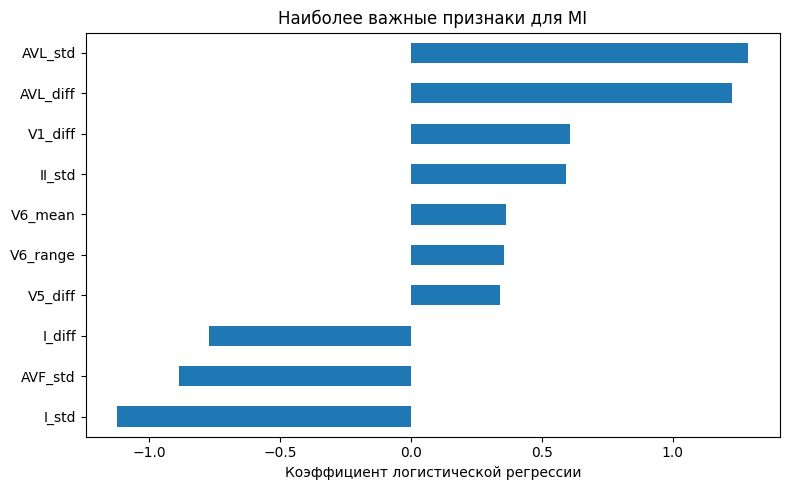

In [59]:
class_name = 'MI'
important = coef_df[class_name].abs().nlargest(10).index

ax = coef_df.loc[important, class_name].sort_values().plot.barh(figsize=(8, 5))
ax.set_title(f'Наиболее важные признаки для {class_name}')
ax.set_xlabel('Коэффициент логистической регрессии')
plt.tight_layout()
plt.show()

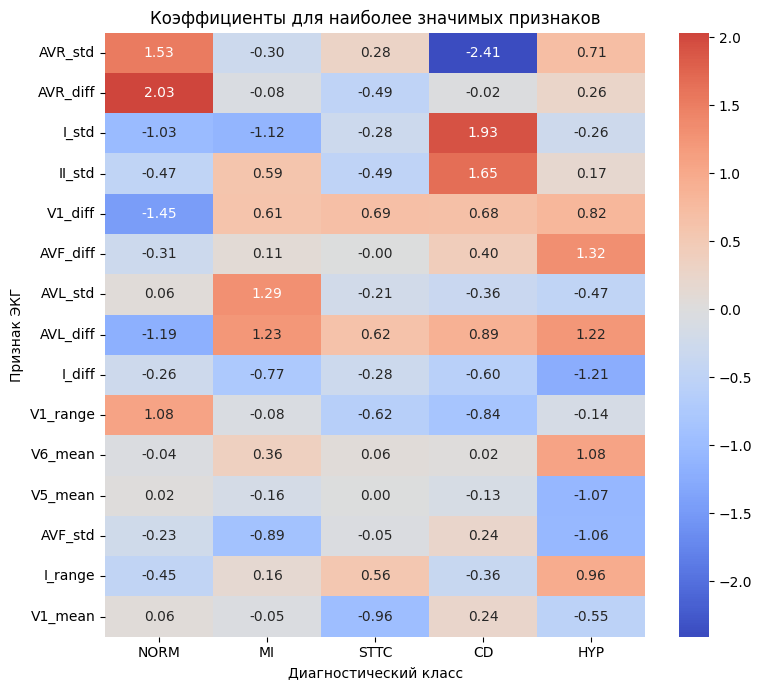

In [60]:
# Сравниваем важные характеристики сразу для всех пяти классов
important = coef_df.abs().max(axis=1).nlargest(15).index

plt.figure(figsize=(8, 7))
sns.heatmap(coef_df.loc[important], cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Коэффициенты для наиболее значимых признаков')
plt.xlabel('Диагностический класс')
plt.ylabel('Признак ЭКГ')
plt.tight_layout()
plt.show()

### Наблюдения по признакам

По коэффициентам логистической регрессии видно, что модель использует разные характеристики ЭКГ для предсказания разных классов.

Например, для **MI** наиболее заметными оказались `AVL_std` (1.289), `AVL_diff` (1.227) и `I_std` (-1.122). Получается, что при предсказании этого класса модель особенно учитывает вариативность амплитуды и изменения сигнала между соседними точками в отведениях aVL и I.

Для **CD** выделяются `AVR_std` (-2.408), `I_std` (1.928) и `II_std` (1.654). Здесь существенную роль играет стандартное отклонение сигнала, причём коэффициенты имеют разные знаки в зависимости от отведения.

Для **STTC** наиболее выраженный коэффициент имеет `V1_mean` (-0.960), а для **HYP** - `AVF_diff` (1.320), `AVL_diff` (1.219) и `I_diff` (-1.222). Таким образом, разные диагностические категории связаны с разными сочетаниями характеристик сигнала.

Интересно, что среди наиболее значимых признаков часто встречаются `std` и `diff`, то есть характеристики изменчивости сигнала. Это говорит о том, что даже без анализа отдельных зубцов и интервалов ЭКГ модель может находить определённые закономерности.

Но стоит учитывать, что отведения ЭКГ взаимосвязаны, поэтому большие положительные и отрицательные коэффициенты могут частично объясняться корреляциями между признаками. Кроме того, мы используем достаточно грубое описание сигнала, которое не позволяет определить, какие конкретно участки ЭКГ повлияли на предсказание.

Тем не менее такой анализ полезен для baseline: он показывает, что модель действительно использует информацию из разных отведений, а не просто предсказывает наиболее распространённые классы.

### 4.8. Итоговые выводы

В рамках второго чекпоинта мы обучили простую baseline-модель для многометочной классификации ЭКГ на датасете PTB-XL.

Для обучения использовали записи `records100` с частотой дискретизации 100 Гц. Из каждого из 12 отведений извлекли четыре статистических признака: среднее значение, стандартное отклонение, размах и среднее абсолютное изменение между соседними точками. В результате каждая ЭКГ была представлена 48 числовыми признаками.

После исключения 411 записей без целевых диагностических меток осталось **21 388 ЭКГ**. Данные разделили на обучающую, валидационную и тестовую выборки по предложенным авторами PTB-XL фолдам, чтобы избежать пересечения пациентов между выборками.

В качестве baseline выбрали логистическую регрессию в схеме One-vs-Rest. На тестовой выборке получили следующие результаты:

- **ROC-AUC macro: 0.767**
- **Average Precision macro: 0.530**
- **F1 macro: 0.538**

Наиболее высокое качество по F1 модель показала для NORM (0.710), а по ROC-AUC - для HYP (0.838). При этом именно у HYP оказался самый низкий F1 (0.466), что показывает, насколько важно оценивать качество сразу по нескольким метрикам, особенно при дисбалансе классов.

Анализ коэффициентов показал, что модель использует разные характеристики сигнала для разных диагнозов. Чаще всего среди наиболее значимых признаков встречались стандартное отклонение и среднее абсолютное изменение сигнала, однако их нельзя напрямую интерпретировать как клинические признаки заболеваний.

**Главное ограничение текущего подхода** заключается в том, что мы сводим каждую 10-секундную запись ЭКГ к небольшому набору статистик. При этом теряется информация о последовательности сигнала, форме отдельных зубцов, комплексах QRS и временных интервалах, которая может быть важна для диагностики.

В дальнейшем планируем перейти к моделям глубокого обучения, например 1D-CNN, которые смогут работать непосредственно с временными рядами ЭКГ. Это позволит проверить, насколько использование полной формы сигнала улучшит классификацию по сравнению с простыми статистическими признаками.

Полученные метрики будем использовать как отправную точку для сравнения следующих моделей. При этом важно сохранить одинаковое разделение данных, набор диагностических классов и правила оценки, чтобы сравнение было корректным.

## 5. Аугментации 12-канальной ЭКГ

Команда 146 · Алексей Воронов · Чекпоинт 2

Сравниваем четыре преобразования: добавление шума, изменение амплитуды,
дрейф изолинии и временной сдвиг. У каждого метода три уровня силы.
Проверяем, как они меняют форму ЭКГ и статистические характеристики,
чтобы выбрать параметры для экспериментов с обучением.

### 5.1. Данные и подготовка

Используем PTB-XL 1.0.3, записи `records100`: 100 Гц, 10 секунд,
12 отведений. В выборке 175 ЭКГ от разных пациентов: по 25 записей
с единственной меткой каждого из пяти суперклассов и 50 мультиметочных.
Записи отобраны из фолдов 1-8 с seed 146. Фолды 9 и 10 оставлены
для валидации и тестирования моделей.

Подготовка из корня репозитория:

```bash
uv sync --locked
uv run python scripts/download_augmentation_subset.py
uv run jupyter lab
```

Загрузчик скачивает метаданные и выбранные сигналы в `data/`.
Ноутбук можно запускать из корня репозитория или из `notebooks/`.
Для запуска нужен `notebooks/labels.py` из ветки Ульяны `UlyShel/eda-analysis`.

Метки готовит `notebooks/labels.py` Ульяны из `ptbxl_database.csv`
и `scp_statements.csv`. Наш модуль присоединяет пути к сигналам по `ecg_id`
и отбирает выборку. Диагностические SCP-коды
сводятся к NORM, MI, STTC, CD, HYP. Учитывается наличие кода,
включая коды с likelihood 0. Записи без этих пяти меток в выборку
не входят, хотя у них могут быть другие SCP-утверждения.

In [61]:
import hashlib
import importlib.metadata
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/ecg_ptbxl/augmentation_data.py").is_file() and (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
from ecg_ptbxl.augmentation_data import CLASSES, build_manifest
from ecg_ptbxl.augmentations import (
    add_baseline_wander, add_gaussian_noise, robust_reference_scale,
    scale_amplitude, shift_signal,
)

DATA_DIR = Path(os.environ.get("PTBXL_AUG_DATA", ROOT / "data/augmentation_ptbxl_1.0.3"))
REPORT_DIR = ROOT / "reports/augmentation"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / "manifest.csv").is_file():
    raise FileNotFoundError("Сначала запустите: uv run python scripts/download_augmentation_subset.py")

SEED = 146
FS = 100
LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})

manifest = pd.read_csv(DATA_DIR / "manifest.csv")
expected = build_manifest(DATA_DIR, per_class=25, multilabel_count=50, seed=SEED)
pd.testing.assert_frame_equal(manifest, expected, check_dtype=False)
assert len(manifest) == manifest.patient_id.nunique() == 175
assert manifest.ecg_id.is_unique and manifest.strat_fold.between(1, 8).all()
assert manifest.has_target_label.all()
info = json.loads((DATA_DIR / "dataset_info.json").read_text(encoding="utf-8"))
for name, expected_hash in info["metadata_sha256"].items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == expected_hash
versions = {name: importlib.metadata.version(name)
            for name in ["numpy", "pandas", "scipy", "wfdb", "matplotlib", "nbformat"]}
manifest.to_csv(REPORT_DIR / "sample_manifest.csv", index=False)
(REPORT_DIR / "environment.json").write_text(
    json.dumps({"python": sys.version.split()[0], "packages": versions,
                "dataset": info}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series({"Записей": len(manifest), "Пациентов": manifest.patient_id.nunique(),
                   "Частота, Гц": FS, "Длительность, с": 10, "Отведений": 12}))
display(manifest.groupby("sampling_group").agg(records=("ecg_id", "size"),
                                               patients=("patient_id", "nunique")))
display(manifest[CLASSES].sum().rename("Положительных меток в выборке").to_frame())

,0
Записей,175
Пациентов,175
"Частота, Гц",100
"Длительность, с",10
Отведений,12


,records,patients
sampling_group,,
multilabel,50,50
single_CD,25,25
single_HYP,25,25
single_MI,25,25
single_NORM,25,25
single_STTC,25,25


,Положительных меток в выборке
NORM,29
MI,54
STTC,54
CD,57
HYP,49


In [62]:
signals = {}
for row in manifest.itertuples(index=False):
    record = wfdb.rdrecord(str(DATA_DIR / row.filename_lr), physical=True)
    signal = record.p_signal
    assert signal.shape == (1000, 12) and record.fs == FS
    assert record.sig_name == LEADS and record.units == ["mV"] * 12
    assert np.isfinite(signal).all()
    assert robust_reference_scale(signal) > 0
    signals[row.ecg_id] = signal

flat_leads = sum(np.count_nonzero(np.ptp(x, axis=0) == 0) for x in signals.values())
display(Markdown(f"Прочитаны **{len(signals)}** ЭКГ; NaN/Inf нет. "
                 f"Полностью постоянных отведений в этой выборке: **{flat_leads}**. "
                 "Физические значения - **mV**, порядок отведений проверен по WFDB-заголовкам."))

Прочитаны **175** ЭКГ; NaN/Inf нет. Полностью постоянных отведений в этой выборке: **0**. Физические значения - **mV**, порядок отведений проверен по WFDB-заголовкам.

### 5.2. Преобразования

Каждый метод применяется отдельно. Для одной ЭКГ на всех трёх уровнях
используем тот же шум, направление изменения амплитуды и сдвига,
фазу и веса дрейфа. Так можно сравнить именно силу воздействия.

Опорный масштаб - медиана RMS по отведениям после вычитания среднего.
Постоянные каналы исключаются из расчёта. Медиана уменьшает влияние
одного отведения с большой амплитудой. На графиках сохраняются физические
единицы, без отдельной нормализации каждого сигнала.

| Метод | Три уровня силы | Как применяется |
|---|---|---|
| Шум | опорный SNR 30 / 20 / 10 dB | гауссовы возмущения |
| Изменение амплитуды | ±5 / ±15 / ±30% | общий положительный коэффициент для всех отведений |
| Дрейф изолинии | 0,1 / 0,3 / 0,6 опорного RMS | синусоида 0,3 Гц со случайной фазой и весами отведений |
| Временной сдвиг | ±0,10 / ±0,25 / ±0,50 с | перенос всех отведений; свободный край заполняется крайним значением |

Эти диапазоны выбраны для сравнения. Заданный SNR относится к опорному
масштабу; фактический SNR считаем отдельно. Для дрейфа указана медиана
абсолютных пиковых амплитуд по отведениям. В отдельном канале амплитуда
добавленной синусоиды может быть выше.

Возмущения III, aVR, aVL, aVF выводим из возмущений I и II:
`III = II-I`, `aVR = -(I+II)/2`, `aVL = I-II/2`, `aVF = II-I/2`.
Поэтому добавление шума и дрейфа не меняет исходную погрешность этих
соотношений. Это упрощённая модель помех, без моделирования электродов.

In [63]:
METHODS = ["noise", "gain", "wander", "shift"]
NAMES = {"noise": "Шум", "gain": "Амплитуда", "wander": "Дрейф", "shift": "Сдвиг"}
COLORS = {"noise": "#2676b8", "gain": "#d17b13", "wander": "#278260", "shift": "#a84d84"}
PARAMETERS = {"noise": [30., 20., 10.], "gain": [.05, .15, .30],
              "wander": [.1, .3, .6], "shift": [.1, .25, .5]}
SHORT = {"noise": ["30 dB", "20 dB", "10 dB"], "gain": ["±5%", "±15%", "±30%"],
         "wander": ["0,1 RMS", "0,3 RMS", "0,6 RMS"], "shift": ["±0,1 с", "±0,25 с", "±0,5 с"]}

def transform(signal, ecg_id, method, level):
    rng = np.random.default_rng(np.random.SeedSequence([SEED, int(ecg_id), METHODS.index(method)]))
    parameter = PARAMETERS[method][level - 1]
    extra = {"shift_samples": 0, "gain_factor": 1., "reference_snr_db": np.nan}
    if method == "noise":
        result = add_gaussian_noise(signal, parameter, rng, lead_consistent=True)
        extra["reference_snr_db"] = parameter
    elif method == "gain":
        factor = 1 + rng.choice([-1, 1]) * parameter
        result = scale_amplitude(signal, factor)
        extra["gain_factor"] = factor
    elif method == "wander":
        result = add_baseline_wander(signal, FS, parameter, .3, rng, lead_consistent=True)
    else:
        shift = int(rng.choice([-1, 1]) * round(parameter * FS))
        result = shift_signal(signal, shift)
        extra["shift_samples"] = shift
    assert result.shape == signal.shape and np.isfinite(result).all()
    return result, extra

display(pd.DataFrame([{ "Метод": NAMES[m], "Низкий": SHORT[m][0],
                       "Средний": SHORT[m][1], "Высокий": SHORT[m][2] } for m in METHODS]))

,Метод,Низкий,Средний,Высокий
0,Шум,30 dB,20 dB,10 dB
1,Амплитуда,±5%,±15%,±30%
2,Дрейф,"0,1 RMS","0,3 RMS","0,6 RMS"
3,Сдвиг,"±0,1 с","±0,25 с","±0,5 с"


### 5.3. Показатели

- **NRMSE** - RMS разности сигналов, делённый на опорный масштаб исходной ЭКГ.
- **Корреляция** - медиана корреляций по непостоянным отведениям.
  Она чувствительна к сдвигу по времени, но не к положительному множителю амплитуды.
- **Изменения STD, размаха и среднего |diff|.** Первые два показателя
  описывают амплитуду, последний - среднее абсолютное изменение соседних отсчётов.
- **Для сдвига** дополнительно считаем ошибку после обратного выравнивания
  на общей области и долю потерянных отсчётов.
- **Для шума и дрейфа** проверяем сохранение соотношений конечностных отведений.

Сначала считаем показатели для каждой записи, затем медиану и
межквартильный интервал (IQR) по 175 пациентам.

In [64]:
def limb_residual(signal):
    a, b = signal[:, 0], signal[:, 1]
    return np.column_stack([signal[:, 2] - (b-a), signal[:, 3] + (a+b)/2,
                            signal[:, 4] - (a-b/2), signal[:, 5] - (b-a/2)])

def relative_feature_change(before, after):
    valid = np.abs(before) > 1e-12
    return float(np.median(after[valid] / before[valid] - 1)) if valid.any() else np.nan

def measure(original, changed, shift_samples=0):
    reference = robust_reference_scale(original)
    delta_rms = float(np.sqrt(np.mean((changed-original)**2)))
    a = original - original.mean(axis=0)
    b = changed - changed.mean(axis=0)
    den = np.sqrt((a*a).sum(axis=0) * (b*b).sum(axis=0))
    valid = den > 1e-12
    correlation = np.clip((a[:, valid]*b[:, valid]).sum(axis=0)/den[valid], -1, 1)
    if shift_samples > 0:
        overlap_a, overlap_b = original[:-shift_samples], changed[shift_samples:]
    elif shift_samples < 0:
        overlap_a, overlap_b = original[-shift_samples:], changed[:shift_samples]
    else:
        overlap_a, overlap_b = original, changed
    aligned_error = float(np.sqrt(np.mean((overlap_b-overlap_a)**2))) / reference
    signal_rms = float(np.sqrt(np.mean(a*a)))
    return {
        "nrmse": delta_rms/reference,
        "median_correlation": float(np.median(correlation)),
        "std_change_pct": 100*relative_feature_change(original.std(axis=0), changed.std(axis=0)),
        "range_change_pct": 100*relative_feature_change(np.ptp(original, axis=0), np.ptp(changed, axis=0)),
        "madiff_change_pct": 100*relative_feature_change(np.abs(np.diff(original, axis=0)).mean(axis=0),
                                                       np.abs(np.diff(changed, axis=0)).mean(axis=0)),
        "realized_snr_db": 20*np.log10(signal_rms/delta_rms) if delta_rms > 0 else np.inf,
        "aligned_nrmse": aligned_error,
        "lost_fraction": abs(shift_samples)/len(original),
        "limb_residual_change_mv": float(np.max(np.abs(limb_residual(changed)-limb_residual(original)))),
    }

rows = []
for record in manifest.itertuples(index=False):
    original = signals[record.ecg_id]
    for method in METHODS:
        for level in [1, 2, 3]:
            changed, extra = transform(original, record.ecg_id, method, level)
            rows.append({"ecg_id": record.ecg_id, "patient_id": record.patient_id,
                         "sampling_group": record.sampling_group,
                         "method": method, "level": level, **extra,
                         **measure(original, changed, extra["shift_samples"])})
metrics = pd.DataFrame(rows)
metrics.loc[metrics.method != "noise", "realized_snr_db"] = np.nan
assert len(metrics) == 175 * 4 * 3
assert metrics.loc[metrics.method == "shift", "aligned_nrmse"].max() == 0
assert metrics.loc[metrics.method.isin(["noise", "wander"]), "limb_residual_change_mv"].max() < 1e-10
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)

METRICS = ["nrmse", "median_correlation", "std_change_pct", "range_change_pct", "madiff_change_pct",
           "realized_snr_db", "aligned_nrmse", "lost_fraction", "limb_residual_change_mv"]
summary = metrics.groupby(["method", "level"])[METRICS].agg(
    ["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
summary.columns = [f"{metric}_{stat.replace('<lambda_0>', 'q25').replace('<lambda_1>', 'q75')}"
                   for metric, stat in summary.columns]
summary = summary.reindex(pd.MultiIndex.from_product([METHODS, [1, 2, 3]], names=["method", "level"]))
summary.to_csv(REPORT_DIR / "summary.csv")
metrics.groupby(["sampling_group", "method", "level"])[METRICS].median().to_csv(
    REPORT_DIR / "summary_by_group.csv")
display(summary[["nrmse_median", "nrmse_q25", "nrmse_q75", "median_correlation_median",
                 "std_change_pct_median", "madiff_change_pct_median", "lost_fraction_median"]].round(4))

nrmse_median  nrmse_q25  nrmse_q75  median_correlation_median  \
method level                                                                  
noise  1            0.0329     0.0327     0.0332                     0.9995   
       2            0.1041     0.1033     0.1049                     0.9954   
       3            0.3293     0.3267     0.3316                     0.9565   
gain   1            0.0618     0.0550     0.0696                     1.0000   
       2            0.1854     0.1651     0.2087                     1.0000   
       3            0.3707     0.3303     0.4173                     1.0000   
wander 1            0.0950     0.0812     0.1171                     0.9977   
       2            0.2850     0.2437     0.3514                     0.9798   
       3            0.5700     0.4874     0.7028                     0.9260   
shift  1            1.6664     1.4665     1.8885                     0.0280   
       2            1.6939     1.4821     1.9465                     0.0320   
       3            1.7014     1.5116     1.9713                     0.0039   

              std_change_pct_median  madiff_change_pct_median  \
method level                                                    
noise  1                     0.0558                    4.1177   
       2                     0.4673                   24.7954   
       3                     4.6235                  113.5340   
gain   1                     5.0000                    5.0000   
       2                    15.0000                   15.0000   
       3                    30.0000                   30.0000   
wander 1                     0.2154                    0.0205   
       2                     1.9804                    0.0744   
       3                     7.9490                    0.2030   
shift  1                     0.0023                   -0.4846   
       2                    -0.0769                   -1.2641   
       3                    -1.6631                   -5.7087   

              lost_fraction_median  
method level                        
noise  1                     0.000  
       2                     0.000  
       3                     0.000  
gain   1                     0.000  
       2                     0.000  
       3                     0.000  
wander 1                     0.000  
       2                     0.000  
       3                     0.000  
shift  1                     0.010  
       2                     0.025  
       3                     0.050

### 5.4. Примеры сигналов

Ниже одна запись с меткой STTC, отведение II. Все методы и уровни
показаны в одном масштабе. Серая линия показывает исходный сигнал, цветная показывает результат.

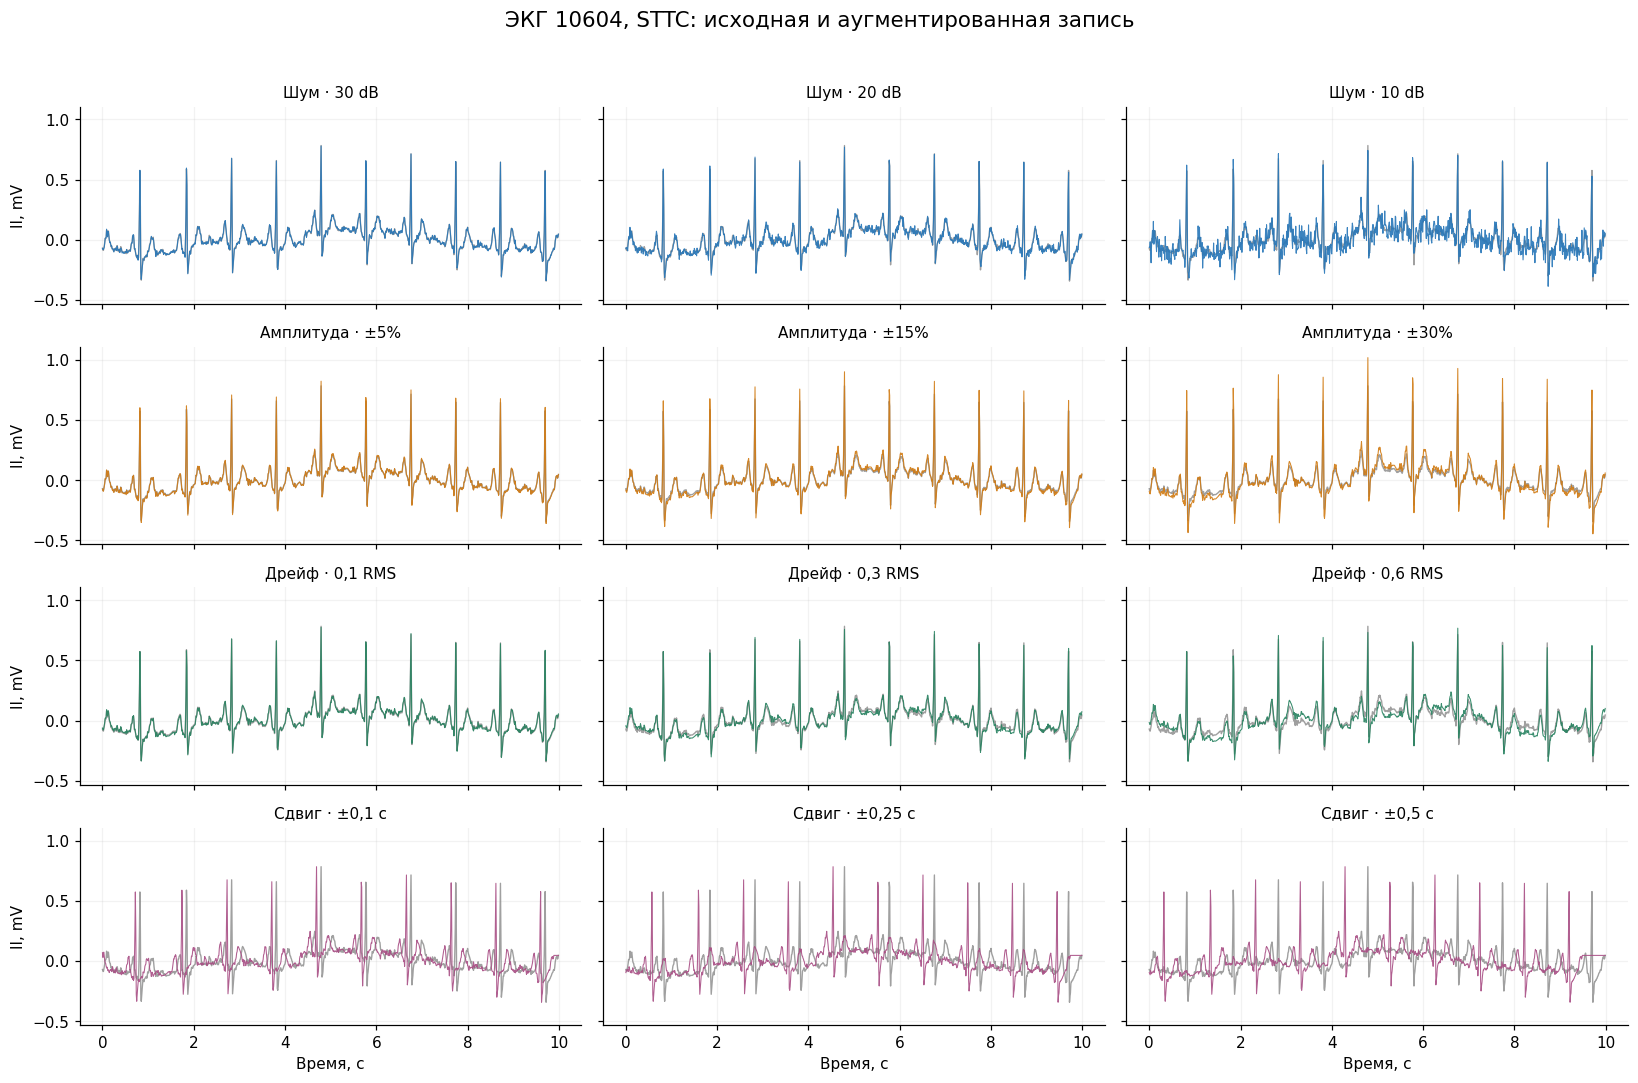

In [65]:
example_id = int(manifest.loc[manifest.sampling_group == "single_STTC", "ecg_id"].iloc[0])
original = signals[example_id]
t = np.arange(len(original))/FS
fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True, sharey=True)
limits = [original[:, 1]]
for i, method in enumerate(METHODS):
    for j, level in enumerate([1, 2, 3]):
        changed, _ = transform(original, example_id, method, level)
        limits.append(changed[:, 1])
        axes[i, j].plot(t, original[:, 1], color="#888888", lw=.9, alpha=.8)
        axes[i, j].plot(t, changed[:, 1], color=COLORS[method], lw=.7, alpha=.9)
        axes[i, j].set_title(f"{NAMES[method]} · {SHORT[method][j]}", fontsize=10)
        axes[i, j].grid(alpha=.16)
        if j == 0:
            axes[i, j].set_ylabel("II, mV")
        if i == 3:
            axes[i, j].set_xlabel("Время, с")
lo, hi = min(x.min() for x in limits), max(x.max() for x in limits)
axes[0, 0].set_ylim(lo-.06*(hi-lo), hi+.06*(hi-lo))
fig.suptitle(f"ЭКГ {example_id}, STTC: исходная и аугментированная запись", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(FIG_DIR / "01_transform_examples.png", dpi=150, bbox_inches="tight")
plt.show()

Посмотрим фрагмент 2-4 с: по одной записи каждого суперкласса
и одну мультиметочную. Для всех методов выбран средний уровень силы.
Масштаб одинаков в пределах строки.

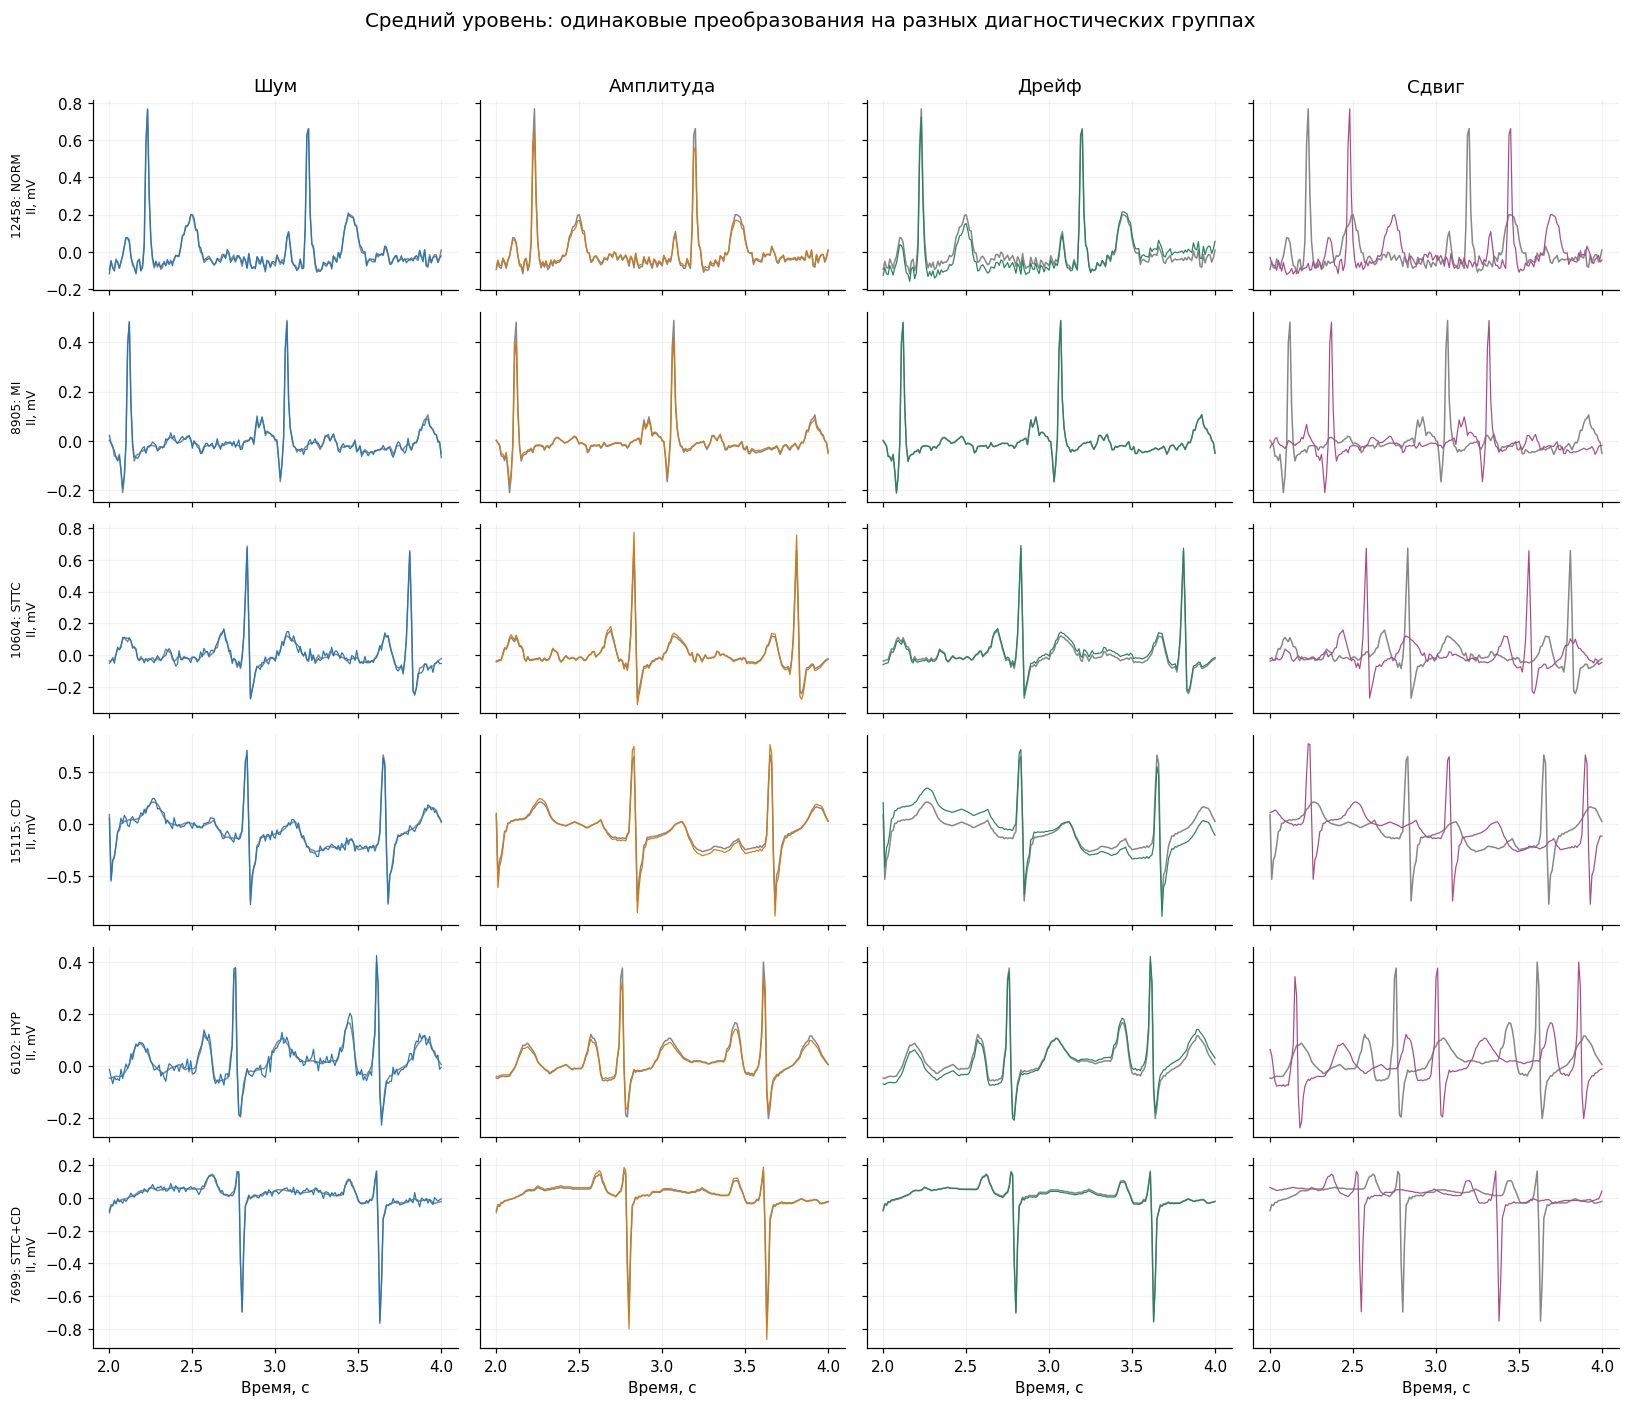

In [66]:
groups = [f"single_{name}" for name in CLASSES] + ["multilabel"]
fig, axes = plt.subplots(6, 4, figsize=(15, 13), sharex=True, sharey="row")
window = (t >= 2) & (t <= 4)
for i, group in enumerate(groups):
    record = manifest.loc[manifest.sampling_group == group].iloc[0]
    ecg_id = int(record.ecg_id)
    original = signals[ecg_id]
    label = "+".join(name for name in CLASSES if record[name] == 1)
    for j, method in enumerate(METHODS):
        changed, _ = transform(original, ecg_id, method, 2)
        axes[i, j].plot(t[window], original[window, 1], color="#888888", lw=1)
        axes[i, j].plot(t[window], changed[window, 1], color=COLORS[method], lw=.8)
        axes[i, j].grid(alpha=.16)
        if i == 0:
            axes[i, j].set_title(NAMES[method])
        if j == 0:
            axes[i, j].set_ylabel(f"{ecg_id}: {label}\nII, mV", fontsize=8)
        if i == 5:
            axes[i, j].set_xlabel("Время, с")
fig.suptitle("Средний уровень: одинаковые преобразования на разных диагностических группах", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(FIG_DIR / "02_group_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### Дрейф во всех 12 отведениях

Веса дрейфа различаются между отведениями. Ниже та же запись
с добавленным дрейфом 0,3 RMS. У каждой панели своя шкала,
общая для исходного и изменённого сигнала.

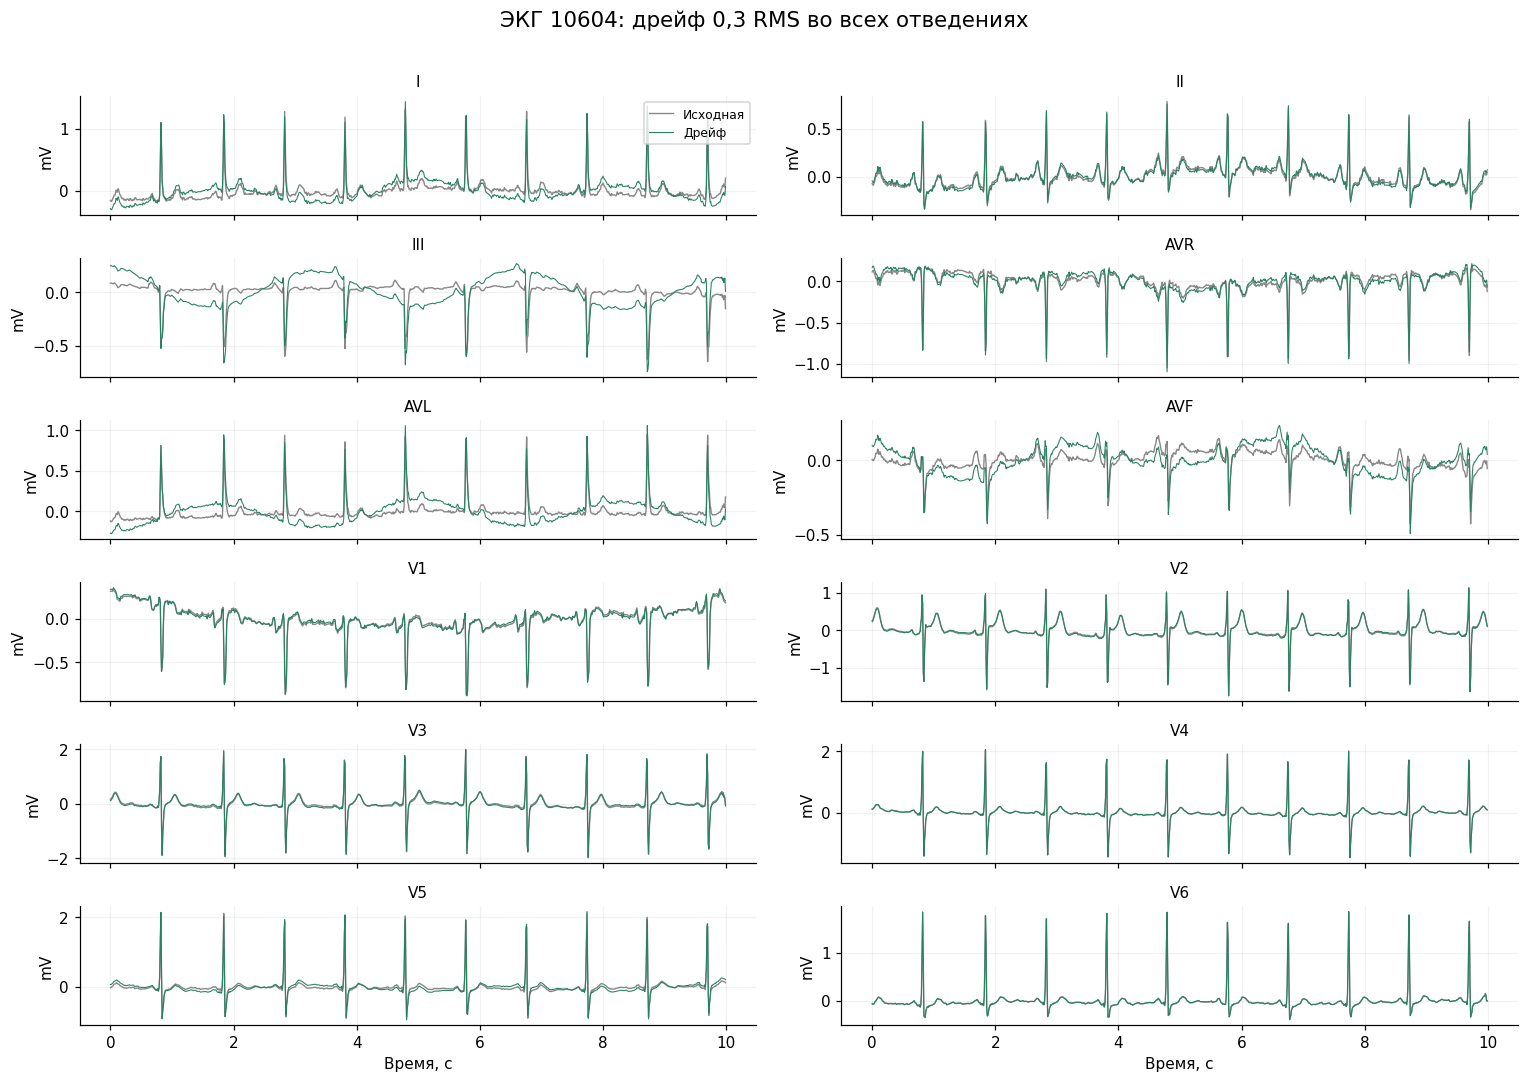

In [67]:
original = signals[example_id]
changed, _ = transform(original, example_id, "wander", 2)
fig, axes = plt.subplots(6, 2, figsize=(14, 10), sharex=True)
for lead_index, ax in enumerate(axes.flat):
    ax.plot(t, original[:, lead_index], color="#888888", lw=.9, label="Исходная")
    ax.plot(t, changed[:, lead_index], color=COLORS["wander"], lw=.7, label="Дрейф")
    ax.set_title(LEADS[lead_index], fontsize=10)
    ax.set_ylabel("mV")
    ax.grid(alpha=.16)
for ax in axes[-1]:
    ax.set_xlabel("Время, с")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle(f"ЭКГ {example_id}: дрейф 0,3 RMS во всех отведениях", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(FIG_DIR / "02b_all_leads.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.5. Сравнение по всей выборке

Точки показывают медианы, отрезки - IQR. Внутри каждого цветового блока
сила преобразования растёт слева направо. Изменение амплитуды видно по STD
и размаху, даже когда корреляция равна 1.

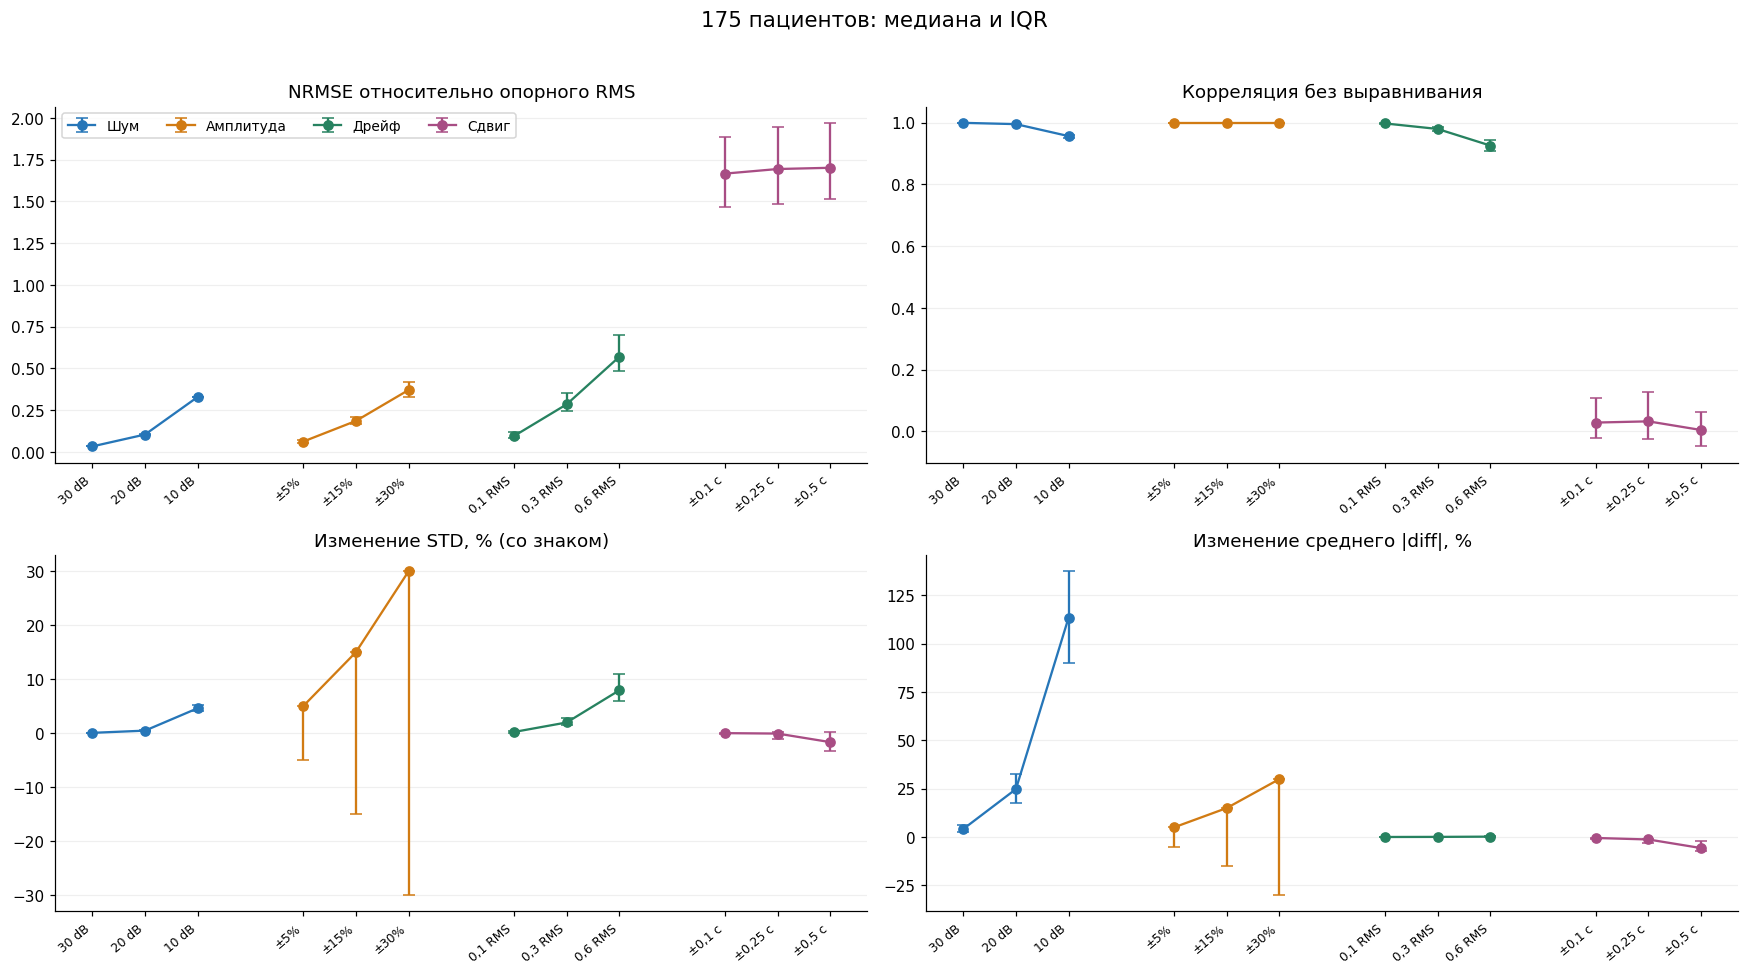

In [68]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
specs = [("nrmse", "NRMSE относительно опорного RMS"),
         ("median_correlation", "Корреляция без выравнивания"),
         ("std_change_pct", "Изменение STD, % (со знаком)"),
         ("madiff_change_pct", "Изменение среднего |diff|, %")]
for ax, (metric, title) in zip(axes.flat, specs):
    for mi, method in enumerate(METHODS):
        values = summary.loc[method]
        x = np.arange(3) + mi*4
        median = values[f"{metric}_median"].to_numpy()
        lower = median-values[f"{metric}_q25"].to_numpy()
        upper = values[f"{metric}_q75"].to_numpy()-median
        ax.errorbar(x, median, yerr=np.vstack([lower, upper]), fmt="o-", capsize=4,
                    color=COLORS[method], label=NAMES[method], lw=1.5)
    ax.set_xticks([mi*4+j for mi in range(4) for j in range(3)],
                  [SHORT[m][j] for m in METHODS for j in range(3)], rotation=40, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.2)
axes[0, 0].legend(ncol=4, fontsize=9)
fig.suptitle("175 пациентов: медиана и IQR", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(FIG_DIR / "03_distortion_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Увеличение и уменьшение амплитуды разберём отдельно: общий медианный
знак зависит от того, какое направление выпало чаще. Также сравним
заданный опорный SNR шума с фактическим.

In [69]:
gain_details = metrics.loc[metrics.method == "gain"].assign(
    direction=lambda df: np.where(df.gain_factor > 1, "увеличение", "уменьшение"))
display(gain_details.groupby(["level", "direction"]).agg(
    n=("ecg_id", "size"), gain=("gain_factor", "first"),
    correlation=("median_correlation", "median"), std_change_pct=("std_change_pct", "median")))
display(metrics.loc[metrics.method == "noise"].groupby("reference_snr_db").agg(
    realized_snr_median=("realized_snr_db", "median"),
    realized_snr_q25=("realized_snr_db", lambda s: s.quantile(.25)),
    realized_snr_q75=("realized_snr_db", lambda s: s.quantile(.75))))

n  gain  correlation  std_change_pct
level direction                                        
1     увеличение  91  1.05          1.0             5.0
      уменьшение  84  0.95          1.0            -5.0
2     увеличение  91  1.15          1.0            15.0
      уменьшение  84  0.85          1.0           -15.0
3     увеличение  91  1.30          1.0            30.0
      уменьшение  84  0.70          1.0           -30.0

,realized_snr_median,realized_snr_q25,realized_snr_q75
reference_snr_db,,,
10.0,11.467237,10.459642,12.470095
20.0,21.467237,20.459642,22.470095
30.0,31.467237,30.459642,32.470095


### Сдвиг и обработка краёв

После обратного выравнивания сохранившаяся часть сигнала совпадает
с исходной. При этом один край теряется, а на другом появляется
постоянный участок. Если проявление патологии было на потерянном краю,
исходная метка может перестать соответствовать записи.

,nrmse_median,median_correlation_median,aligned_nrmse_median,lost_fraction_median
level,,,,
1,1.666424,0.028010,0.0,0.010
2,1.693940,0.031971,0.0,0.025
3,1.701412,0.003899,0.0,0.050


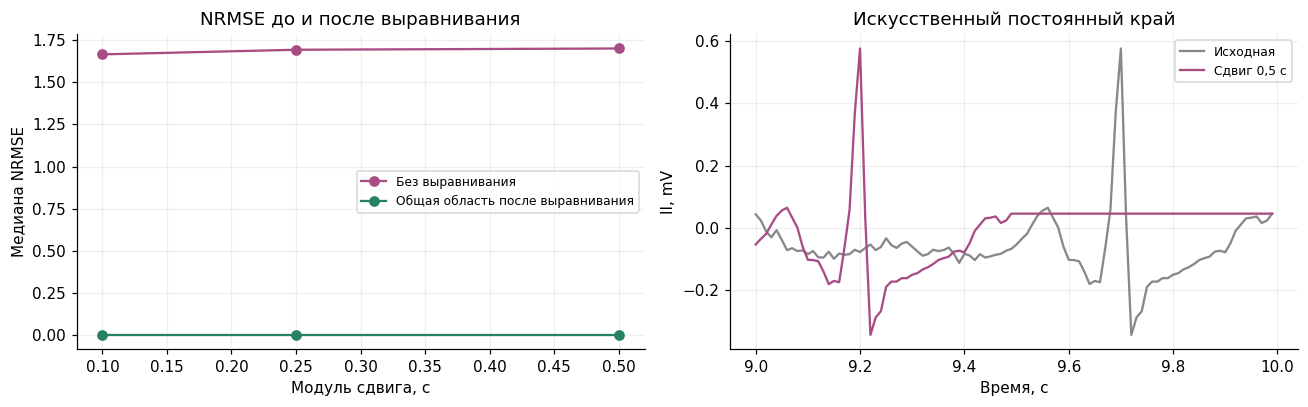

In [70]:
shift_summary = summary.loc["shift"]
display(shift_summary[["nrmse_median", "median_correlation_median", "aligned_nrmse_median",
                       "lost_fraction_median"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot([.1, .25, .5], shift_summary.nrmse_median, "o-", label="Без выравнивания", color=COLORS["shift"])
axes[0].plot([.1, .25, .5], shift_summary.aligned_nrmse_median, "o-", label="Общая область после выравнивания", color="#278260")
axes[0].set(xlabel="Модуль сдвига, с", ylabel="Медиана NRMSE", title="NRMSE до и после выравнивания")
axes[0].legend(fontsize=8)
original = signals[example_id]
changed, extra = transform(original, example_id, "shift", 3)
edge = (t <= 1) if extra["shift_samples"] > 0 else (t >= 9)
axes[1].plot(t[edge], original[edge, 1], color="#888888", label="Исходная")
axes[1].plot(t[edge], changed[edge, 1], color=COLORS["shift"], label="Сдвиг 0,5 с")
axes[1].set(xlabel="Время, с", ylabel="II, mV", title="Искусственный постоянный край")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_shift_alignment.png", dpi=150, bbox_inches="tight")
plt.show()

### Сравнение по диагностическим группам

Ниже медианный NRMSE по шести группам выборки. В каждой группе
25 или 50 записей; таблица показывает различия в силе искажения.
Статистическую значимость различий здесь не проверяем.

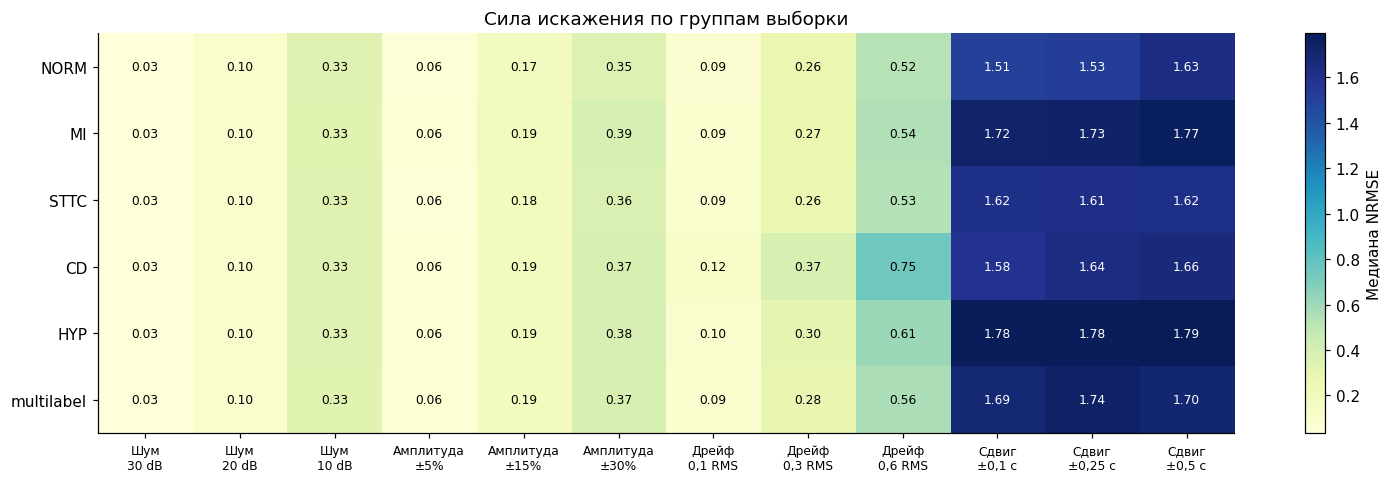

In [71]:
pivot = metrics.pivot_table(index="sampling_group", columns=["method", "level"], values="nrmse", aggfunc="median")
pivot = pivot.reindex(index=groups, columns=pd.MultiIndex.from_product([METHODS, [1, 2, 3]]))
fig, ax = plt.subplots(figsize=(14, 4.5))
image = ax.imshow(pivot, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(6), [name.replace("single_", "") for name in groups])
ax.set_xticks(range(12), [f"{NAMES[m]}\n{SHORT[m][j]}" for m in METHODS for j in range(3)], fontsize=8)
for i in range(6):
    for j in range(12):
        value = pivot.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if value > np.nanmax(pivot.to_numpy())*.55 else "black")
fig.colorbar(image, ax=ax, label="Медиана NRMSE")
ax.set_title("Сила искажения по группам выборки")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_group_distortion.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.6. Выводы

In [72]:
def value(method, level, metric):
    return float(summary.loc[(method, level), f"{metric}_median"])

def number(method, level, metric, digits=3):
    return f"{value(method, level, metric):.{digits}f}".replace(".", ",")

observations = f"""
### Результаты сравнения

При добавлении шума с опорным SNR от 30 до 10 dB медианный NRMSE вырос
с {number('noise', 1, 'nrmse')} до {number('noise', 3, 'nrmse')},
а корреляция снизилась с {number('noise', 1, 'median_correlation', 4)}
до {number('noise', 3, 'median_correlation', 4)}. При 10 dB среднее |diff| выросло на
{number('noise', 3, 'madiff_change_pct', 1)}% (медиана по выборке).
Сильный шум заметно меняет этот признак; при 30 dB его рост составил
{number('noise', 1, 'madiff_change_pct', 1)}%.

При изменении амплитуды корреляция осталась равной 1 даже для ±30%.
При этом STD, размах и среднее |diff| изменились на выбранные ±5/15/30%.
По одной корреляции такие преобразования оценивать нельзя.

Для дрейфа изолинии медианный NRMSE вырос с {number('wander', 1, 'nrmse')}
до {number('wander', 3, 'nrmse')}. Среднее |diff| изменилось мало:
даже на высоком уровне медианное изменение составило
{number('wander', 3, 'madiff_change_pct', 1)}%. Этот показатель слабо реагирует
на медленные колебания изолинии.

При сдвиге на 0,5 с NRMSE до выравнивания составил
{number('shift', 3, 'nrmse')}, а после выравнивания общей области - 0.
Форма сохранившегося участка не изменилась, но сдвиги на 0,1/0,25/0,5 с
удалили соответственно 1/2,5/5% исходных отсчётов. На противоположном
краю появился постоянный участок.

"""
display(Markdown(observations))
(REPORT_DIR / "conclusions.md").write_text(
    "# Аугментации ЭКГ: результаты и выводы\n\n" + observations.strip() + "\n", encoding="utf-8")
recommendations = pd.DataFrame([
    ["noise", "30 dB", "проверить первым при обучении", "20 dB отдельно; 10 dB для сильных помех"],
    ["gain", "±5%", "сравнить с исходными данными", "амплитуда важна для части диагнозов"],
    ["wander", "0.1 reference RMS", "пробовать после просмотра ST/T", "высокие уровни для сильного дрейфа"],
    ["shift", "±0.1 s", "пробовать, если потеря края допустима", "теряется 1% записи"],
], columns=["method", "candidate_setting", "recommendation", "limitation"])
recommendations.to_csv(REPORT_DIR / "recommendations.csv", index=False)


### Результаты сравнения

При добавлении шума с опорным SNR от 30 до 10 dB медианный NRMSE вырос
с 0,033 до 0,329,
а корреляция снизилась с 0,9995
до 0,9565. При 10 dB среднее |diff| выросло на
113,5% (медиана по выборке).
Сильный шум заметно меняет этот признак; при 30 dB его рост составил
4,1%.

При изменении амплитуды корреляция осталась равной 1 даже для ±30%.
При этом STD, размах и среднее |diff| изменились на выбранные ±5/15/30%.
По одной корреляции такие преобразования оценивать нельзя.

Для дрейфа изолинии медианный NRMSE вырос с 0,095
до 0,570. Среднее |diff| изменилось мало:
даже на высоком уровне медианное изменение составило
0,2%. Этот показатель слабо реагирует
на медленные колебания изолинии.

При сдвиге на 0,5 с NRMSE до выравнивания составил
1,701, а после выравнивания общей области - 0.
Форма сохранившегося участка не изменилась, но сдвиги на 0,1/0,25/0,5 с
удалили соответственно 1/2,5/5% исходных отсчётов. На противоположном
краю появился постоянный участок.



## 6. Общие выводы

Данные приведены к общим путям, пяти целевым меткам и разбиению по пациентам.
Пропуски в дополнительных метаданных не означают пропуски в ЭКГ: все сигналы
имеют формат 1000 × 12 и не содержат NaN/Inf. Постоянные участки, большие
амплитуды и медленные изменения требуют отдельной проверки. В этой работе
они не служат автоматическим основанием для удаления записей или фильтрации.

Бейзлайн на 48 статистиках даёт исходный уровень для дальнейшего сравнения.
Предобработка модели обучается на train; validation и test сохраняются
отдельно. Качество различается между классами, поэтому вместе с macro ROC-AUC
смотрим average precision и F1 по каждой группе. Статистики не описывают
всю форму и временную структуру ЭКГ.

Аугментации сравнивались по изменениям сигналов, без повторного обучения
модели. Сильный шум меняет признаки, масштабирование не обнаруживается
корреляцией, среднее |diff| слабо реагирует на дрейф, а сдвиг теряет края
записи. Эти результаты помогают выбрать и проверить последующие эксперименты,
но пока не показывают улучшения качества классификации.

Практическая ценность проекта описана в `reports/practical_value.pdf`.